# Comparative Analysis of CNN, RNN, and Hybrid CNN–RNN Architectures for Papilledema Detection and Severity Grading

**Central Research & Reproducibility Notebook**

This notebook consolidates the complete, audited research pipeline from raw data inspection and leakage-aware splitting through multi-seed GPU training, per-track evaluation, nonparametric/parametric hypothesis testing, error inspection, and final artifact export.

### Experimental Tracks Evaluated (Strictly Separate — Never Pooled)
1. **Track 1 — `fundus_3class` (Kim Fundus 3-Class Classification):** `Normal` vs. `Papilledema` vs. `Pseudopapilledema` across **10 architectures** (`cnn`: ResNet-50, DenseNet-121, EfficientNet-B0; `rnn`: Ordered LSTM, Ordered BiLSTM; `hybrid`: ResNet50-LSTM, ResNet50-BiLSTM, EfficientNetB0-BiLSTM; `baseline`: MLP, Autoencoder+Classifier) x **5 seeds** = **50 runs**.
2. **Track 2 — `oct_individual` (Original OCT 3-Class Individual B-Scan):** `Normal` vs. `Papilledema` vs. `Pseudopapilledema` on individual OCT B-scans across **10 architectures** x **5 seeds** = **50 runs**.
3. **Track 3 — `oct_sequence` (Original OCT 3-Class Ordered B-Scan Sequence):** 8-slice non-overlapping ordered B-scan windows (`seq_len=8, stride=8`) across **5 sequence-compatible architectures** (`resnet50_bilstm`, `efficientnet_b0_bilstm`, `resnet50_lstm`, `bilstm`, `lstm`) x **5 seeds** = **25 runs**.
4. **Track 4 — `oct_severity` (Original OCT Exploratory Frisén Severity Grading, G1–G4):** 4-class B-scan grading across **10 architectures** x **5 seeds** = **50 runs**. *Explicitly marked strictly exploratory due to absence of verified clinical grading metadata and single-prefix minority classes.*

### Execution Modes (Section 3)
- **Mode B (`RUN_MISSING_EXPERIMENTS = False`, Default):** Inspects, verifies, and analyzes all **175 completed full non-smoke runs**, tables, statistics, and error logs from disk without triggering multi-hour re-training.
- **Mode A (`RUN_MISSING_EXPERIMENTS = True`):** Automatically executes any missing runs via `run_single_experiment` / `ExperimentManager`, refreshes all comparison tables/statistics/figures, and executes end-to-end.

## 2. Environment, Hardware & Reproducibility Setup

Verifies Python/PyTorch/CUDA versions, NVIDIA RTX 5050 Laptop GPU (`sm_120`, 8 GB VRAM) compatibility, Windows-safe `DataLoader` configuration (`num_workers=0`), deterministic seeding across 5 seeds `[42, 123, 2024, 3407, 5678]`, and mixed-precision (`AMP`) support. Multi-layer dropout LSTMs on Windows + CUDA `sm_120` automatically invoke the verified cuDNN fallback inside `src/models/rnn.py` and `src/models/hybrid.py` (`torch.backends.cudnn.flags(enabled=False)` when `is_cuda and num_layers > 1 and dropout > 0`) to prevent Windows process-exit crash `0xC0000409`.

In [1]:
%matplotlib inline
import json
import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image as IPyImage, display
from PIL import Image

warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams["figure.dpi"] = 120
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 180)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

from src.utils.config import load_all_configs, resolve_path
from src.utils.device import clear_gpu_memory, get_device, get_gpu_memory_mb, get_hardware_info, verify_gpu_compatibility
from src.utils.reproducibility import seed_everything

hw = get_hardware_info()
gpu_ok, gpu_msg = verify_gpu_compatibility()
device = get_device(prefer_gpu=True)
seed_everything(42, deterministic=True)

print("Project Root :", PROJECT_ROOT)
print("Platform     :", hw["platform"])
print("Python       :", hw["python_version"])
print("PyTorch      :", hw["torch_version"], "| CUDA:", hw["cuda_version"])
print("GPU Check    :", gpu_ok, "|", gpu_msg)
print("Active Device:", device)
print("System RAM GB:", round(hw["ram_total_gb"], 2), "| CPU cores:", hw["cpu_cores_physical"], "/", hw["cpu_cores_logical"])

Project Root : C:\Users\Shuvendu\Desktop\Papilledema_analysis
Platform     : Windows-11-10.0.26200-SP0
Python       : 3.12.10
PyTorch      : 2.14.0+cu132 | CUDA: 13.2
GPU Check    : True | NVIDIA GeForce RTX 5050 Laptop GPU (sm_120) verified with PyTorch 2.14.0+cu132
Active Device: cuda
System RAM GB: 23.64 | CPU cores: 10 / 16


## 3. Configuration & Dual Execution Control

Loads merged YAML configurations from `configs/` (`base.yaml`, `fundus.yaml`, `oct.yaml`, `models.yaml`, `experiments.yaml`) using relative paths and defines the dual-mode switch:
- **`RUN_MISSING_EXPERIMENTS = False` (Mode B — Default Analysis Mode):** Verifies completion of all 175 non-smoke experiments and proceeds cleanly using persisted metrics, predictions, checkpoints, tables, and statistical results.
- **`RUN_MISSING_EXPERIMENTS = True` (Mode A — Full Reproduction Mode):** Executes only missing non-smoke `(track, model, seed)` combinations sequentially on GPU and regenerates all downstream outputs via `ExperimentManager.generate_all_outputs()` and `run_statistical_analysis()`.

In [2]:
from src.data.validation import FUNDUS_CLASSES, OCT_3CLASSES, OCT_SEVERITY_CLASSES
from src.experiments.manager import ExperimentManager, make_experiment_id
from src.statistics import run_statistical_analysis
from src.training.experiment_runner import run_single_experiment

# Restore notebook inline plotting after src.visualization imports matplotlib Agg backend
get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams["figure.dpi"] = 120

RUN_MISSING_EXPERIMENTS = False  # Mode B default; set True (Mode A) to execute any missing runs

cfg = load_all_configs("configs")
manager = ExperimentManager(cfg)
seeds = [int(s) for s in cfg["project"]["random_seeds"]]
tracks_cfg = cfg["experiments"]

print("Configured Random Seeds :", seeds)
print("Max Epochs / Patience   :", cfg["training"]["epochs"], "/", cfg["training"]["early_stopping_patience"])
print("Learning Rate / WeightD :", cfg["training"]["learning_rate"], "/", cfg["training"]["weight_decay"])
print("Batch Size / NumWorkers :", cfg["training"]["batch_size"], "/", cfg["training"]["num_workers"])
print("Mixed Precision / Clip  :", cfg["training"]["use_mixed_precision"], "/", cfg["training"]["grad_clip_norm"])

planned_runs = []
missing_runs = []
for track_name, tcfg in tracks_cfg.items():
    for model_name in tcfg["models"]:
        for seed in seeds:
            exp_id = make_experiment_id(track_name, model_name, seed)
            done = manager.is_completed(exp_id)
            planned_runs.append((track_name, model_name, seed, exp_id, done))
            if not done:
                missing_runs.append((track_name, model_name, seed, exp_id))

print(f"Planned Matrix: {len(planned_runs)} runs | Completed: {len(planned_runs) - len(missing_runs)} | Missing: {len(missing_runs)}")

if RUN_MISSING_EXPERIMENTS and missing_runs:
    print(f"Mode A active: launching {len(missing_runs)} missing runs sequentially...")
    for track_name, model_name, seed, exp_id in missing_runs:
        print(f"Running {exp_id} ...")
        run_single_experiment(cfg, track=track_name, model_name=model_name, seed=seed, overwrite=False, resume=True)
    outputs_info = manager.generate_all_outputs()
    runs_df_tmp = manager.collect_completed_runs()
    track_classes = {
        "fundus_3class": FUNDUS_CLASSES,
        "oct_individual": OCT_3CLASSES,
        "oct_sequence": OCT_3CLASSES,
        "oct_severity": OCT_SEVERITY_CLASSES,
    }
    run_statistical_analysis(
        runs_df=runs_df_tmp,
        predictions_dir=resolve_path(cfg["paths"]["results_dir"]) / "predictions",
        output_dir=resolve_path(cfg["paths"]["results_dir"]) / "statistical_analysis",
        track_classes=track_classes,
        alpha=float(cfg["evaluation"]["alpha"]),
        n_bootstrap=int(cfg["evaluation"]["bootstrap_resamples"]),
        seed=42,
    )
    print("Mode A regeneration complete:", outputs_info)
else:
    print("Mode B active: reading verified completed experiment artifacts from disk.")

Configured Random Seeds : [42, 123, 2024, 3407, 5678]
Max Epochs / Patience   : 30 / 7
Learning Rate / WeightD : 0.0001 / 0.0001
Batch Size / NumWorkers : 16 / 0
Mixed Precision / Clip  : True / 1.0
Planned Matrix: 175 runs | Completed: 175 | Missing: 0
Mode B active: reading verified completed experiment artifacts from disk.


## 4. Raw Dataset Discovery, Verification & Exploratory Statistics

Inspects `data/manifests/dataset_audit.json`, exclusion logs (`fundus_excluded.csv`, `oct_excluded.csv`), image dimensions, color modes, pixel intensity summaries, class distributions, and representative real samples across both modalities and severity grades.

Key verified facts from disk audit:
- **Kim Fundus:** **1,367** valid fundus images retained (`778` Normal, `295` Papilledema, `294` Pseudopapilledema), widths `240` px and heights `208–240` px (`RGB uint8`, `in_channels=3`); **2** exact/near-exact cross-class conflicting duplicates excluded (`Normal/452.jpg` and `Pseudopapilledema/149.jpg`).
- **Original OCT:** **1,140** valid OCT B-scans retained (`895` Papilledema, `132` Normal, `113` Pseudopapilledema); **1** non-B-scan IR/SLO reflectance image (`Pseudo papilledema/heshama_001.jpg`, `269x701`, `max_ch_diff=0`) excluded. Disk widths span `381–765` px at height `596` px (`in_channels=1` grayscale during training).
- **Original OCT Severity Subset (Exploratory):** **895** Papilledema B-scans annotated `G1=40`, `G2=598`, `G3=184`, `G4=73`.
- Excluded non-canonical/augmented directories (`Original Data/Original Data/OCT`, `OCT Data with Patient ID`, `Augmented Data`) were strictly excluded prior to all training.

=== Dataset Summary ===
     dataset          task             class  count
  Kim Fundus fundus_3class            Normal    778
  Kim Fundus fundus_3class       Papilledema    295
  Kim Fundus fundus_3class Pseudopapilledema    294
Original OCT    oct_3class       Papilledema    895
Original OCT    oct_3class            Normal    132
Original OCT    oct_3class Pseudopapilledema    113
Original OCT  oct_severity                G2    598
Original OCT  oct_severity                G3    184
Original OCT  oct_severity                G4     73
Original OCT  oct_severity                G1     40

=== Excluded Files ===
Fundus excluded: 2
                   sample_id                                image_path             label                          exclusion_reason
           fundus_Normal_452            data/raw/fundus/Normal/452.jpg            Normal cross_class_exact_or_near_exact_duplicate
fundus_Pseudopapilledema_149 data/raw/fundus/Pseudopapilledema/149.jpg Pseudopapilledema cross_clas

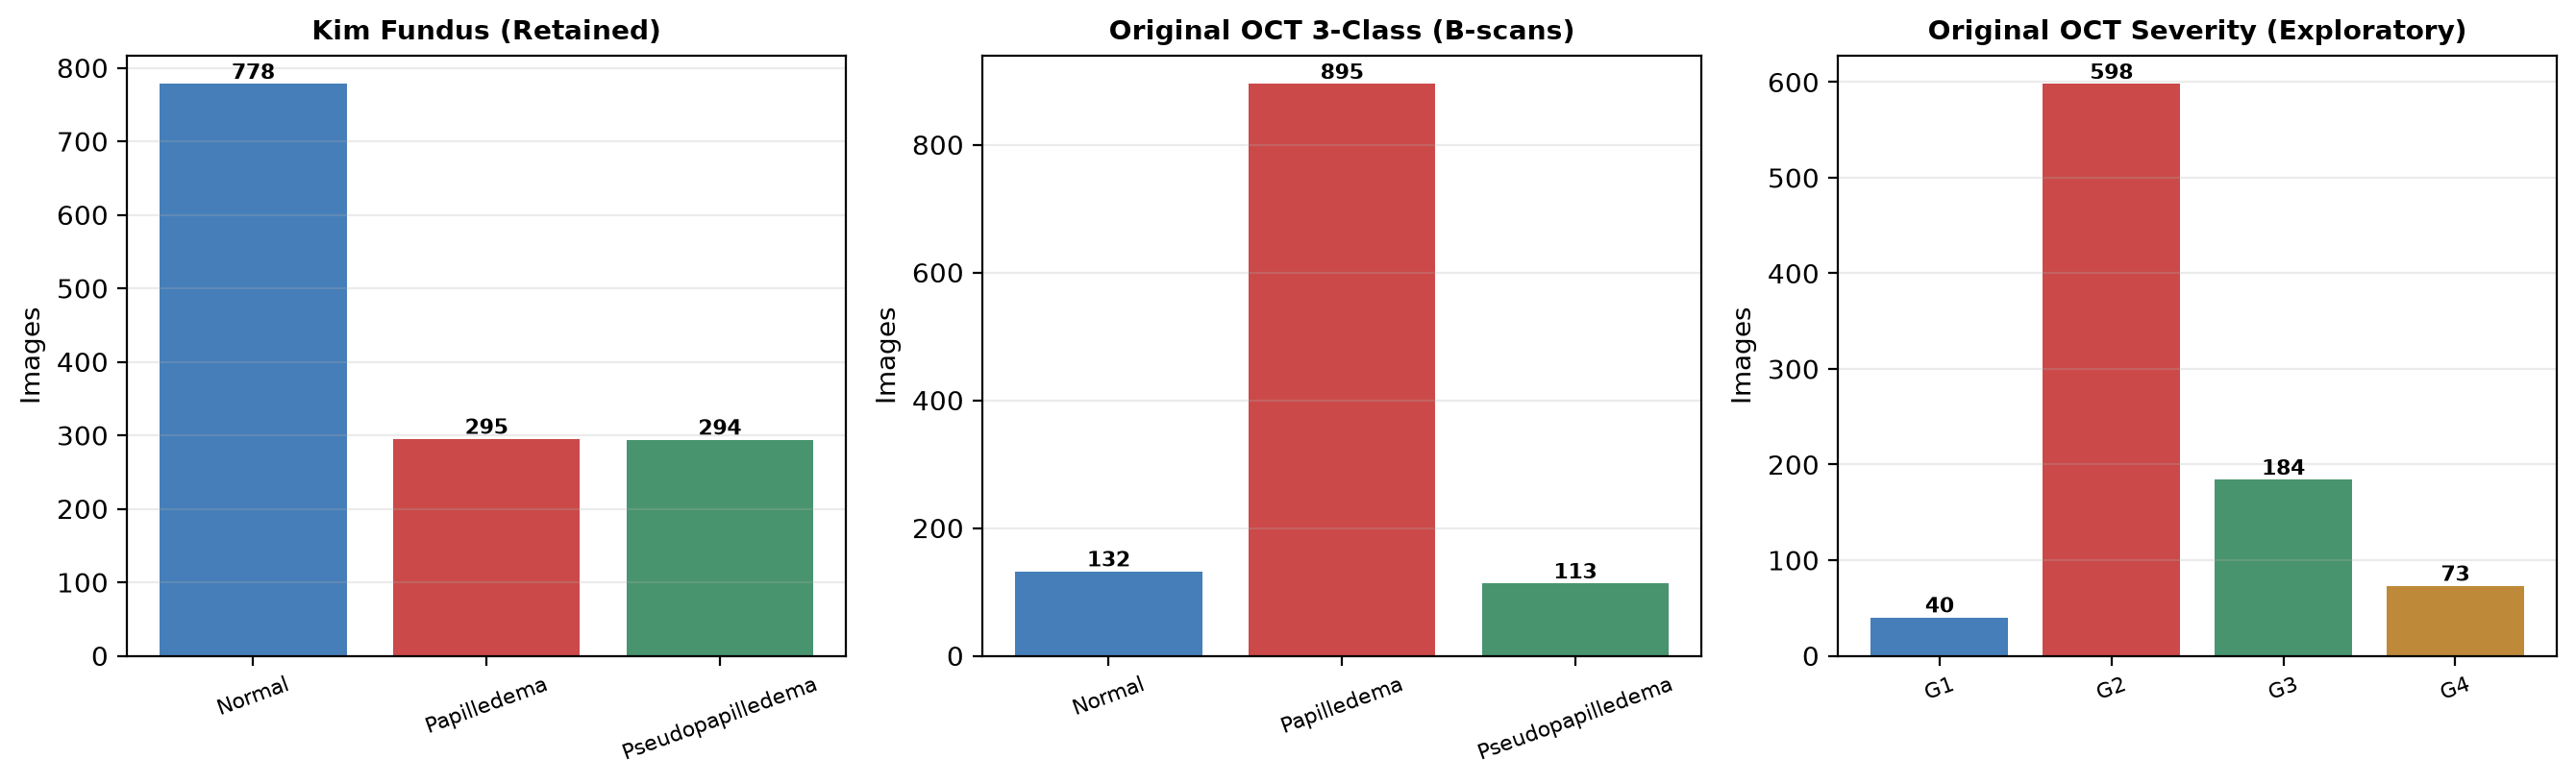

In [3]:
audit_path = Path("data/manifests/dataset_audit.json")
audit_data = json.loads(audit_path.read_text(encoding="utf-8"))
ds_summary = pd.read_csv("results/tables/dataset_summary.csv")
fundus_excl = pd.read_csv("data/manifests/fundus_excluded.csv")
oct_excl = pd.read_csv("data/manifests/oct_excluded.csv")

print("=== Dataset Summary ===")
print(ds_summary.to_string(index=False))
print("\n=== Excluded Files ===")
print("Fundus excluded:", len(fundus_excl))
if len(fundus_excl):
    print(fundus_excl[["sample_id", "image_path", "label", "exclusion_reason"]].to_string(index=False))
print("OCT excluded:", len(oct_excl))
if len(oct_excl):
    print(oct_excl.to_string(index=False))

# Exact geometry + stratified intensity audit from split manifests
stats_rows = []
for mod_name, csv_p, conv_mode in [
    ("Kim Fundus (all 1367, train ch=3 RGB)", "data/splits/fundus_splits.csv", "RGB"),
    ("Original OCT B-scans (all 1140, train ch=1 Gray)", "data/splits/oct_3class_splits.csv", "L"),
]:
    sdf = pd.read_csv(csv_p)
    samp = sdf.sample(min(200, len(sdf)), random_state=42)
    vals_mean, vals_std = [], []
    for img_p in samp["image_path"]:
        arr = np.asarray(Image.open(img_p).convert(conv_mode), dtype=np.float32) / 255.0
        if conv_mode == "RGB":
            vals_mean.append(arr.mean(axis=(0, 1)))
            vals_std.append(arr.std(axis=(0, 1)))
        else:
            vals_mean.append([arr.mean()])
            vals_std.append([arr.std()])
    m_vec = np.mean(vals_mean, axis=0)
    s_vec = np.mean(vals_std, axis=0)
    stats_rows.append({
        "dataset": mod_name,
        "count": len(sdf),
        "disk_modes": ",".join(sorted(sdf["mode"].unique())),
        "width_range": f"{sdf['width'].min()}-{sdf['width'].max()}",
        "height_range": f"{sdf['height'].min()}-{sdf['height'].max()}",
        "sampled_mean": "(" + ", ".join(f"{x:.3f}" for x in m_vec) + ")",
        "sampled_std": "(" + ", ".join(f"{x:.3f}" for x in s_vec) + ")",
    })
print("\n=== Image Geometry & Pixel Intensity Summary ===")
print(pd.DataFrame(stats_rows).to_string(index=False))

display(IPyImage(filename="results/figures/dataset_class_distribution.png"))

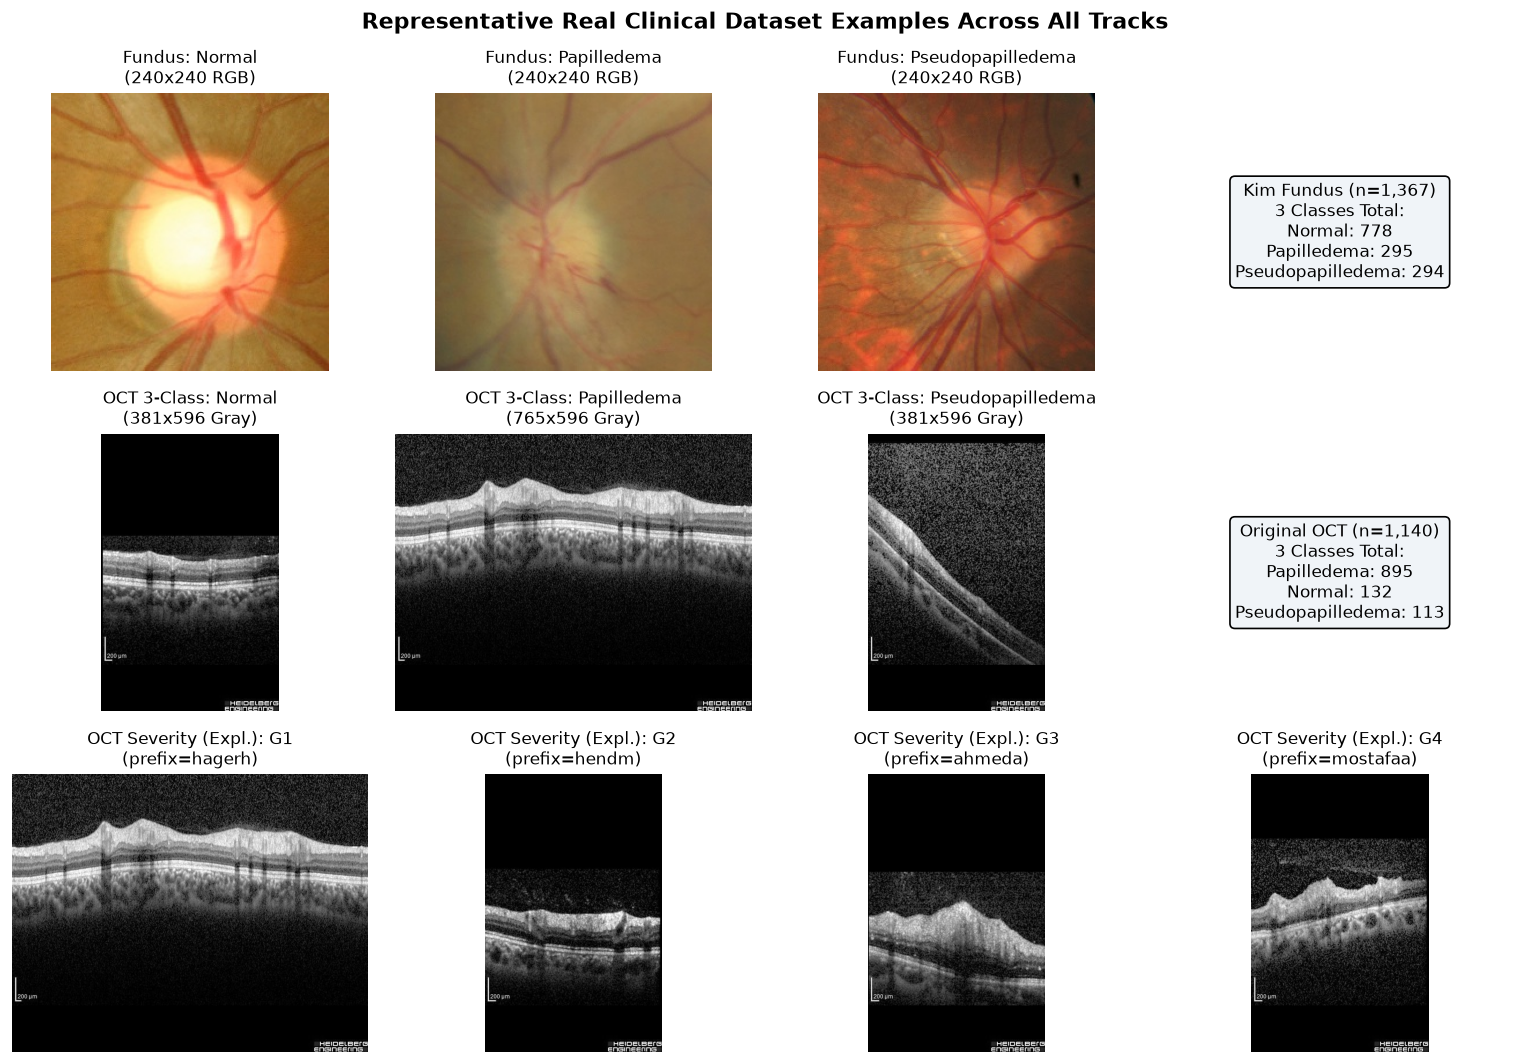

In [4]:
# Representative real images from Fundus 3-class, OCT 3-class, and OCT G1-G4 severity
fundus_df = pd.read_csv("data/splits/fundus_splits.csv")
oct3_df = pd.read_csv("data/splits/oct_3class_splits.csv")
oct_sev_df = pd.read_csv("data/splits/oct_severity_splits.csv")

fig, axes = plt.subplots(3, 4, figsize=(13, 9))
for j, cls in enumerate(["Normal", "Papilledema", "Pseudopapilledema"]):
    row = fundus_df[fundus_df["label"] == cls].iloc[0]
    im = Image.open(row["image_path"]).convert("RGB")
    axes[0, j].imshow(im)
    axes[0, j].set_title(f"Fundus: {cls}\n({row['width']}x{row['height']} RGB)", fontsize=10)
    axes[0, j].axis("off")
axes[0, 3].text(0.5, 0.5, "Kim Fundus (n=1,367)\n3 Classes Total:\nNormal: 778\nPapilledema: 295\nPseudopapilledema: 294", ha="center", va="center", fontsize=10, bbox=dict(boxstyle="round", facecolor="#f0f4f8"))
axes[0, 3].axis("off")

for j, cls in enumerate(["Normal", "Papilledema", "Pseudopapilledema"]):
    row = oct3_df[oct3_df["label"] == cls].iloc[0]
    im = Image.open(row["image_path"]).convert("L")
    axes[1, j].imshow(im, cmap="gray")
    axes[1, j].set_title(f"OCT 3-Class: {cls}\n({row['width']}x{row['height']} Gray)", fontsize=10)
    axes[1, j].axis("off")
axes[1, 3].text(0.5, 0.5, "Original OCT (n=1,140)\n3 Classes Total:\nPapilledema: 895\nNormal: 132\nPseudopapilledema: 113", ha="center", va="center", fontsize=10, bbox=dict(boxstyle="round", facecolor="#f0f4f8"))
axes[1, 3].axis("off")

for j, cls in enumerate(["G1", "G2", "G3", "G4"]):
    row = oct_sev_df[oct_sev_df["label"] == cls].iloc[0]
    im = Image.open(row["image_path"]).convert("L")
    axes[2, j].imshow(im, cmap="gray")
    axes[2, j].set_title(f"OCT Severity (Expl.): {cls}\n(prefix={row['inferred_subject_prefix']})", fontsize=10)
    axes[2, j].axis("off")

plt.suptitle("Representative Real Clinical Dataset Examples Across All Tracks", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 5. Leakage Audit, Duplicate Clustering & Split Verification

Verifies the persisted leakage-aware train/val/test partitions in `data/splits/` and `data/splits/split_validation.json`:
- **Kim Fundus:** Exact pixel-hash and normalized-cross-correlation near-duplicate images were grouped into connected-component clusters (`cluster_id`), keeping every cluster strictly inside one split (`0` cluster overlaps; `190` distinct clusters in `test` across `205` images).
- **Original OCT:** B-scan volumes were grouped by inferred visual/filename series (`inferred_sequence_id`), yielding **0** sequence overlaps between splits and **101 train / 23 val / 23 test** non-overlapping **8-slice stride-8** sequence windows (`4` test sequence IDs).
- **Critical Provenance Caveat:** Verified patient IDs do **not** exist in either dataset. Moreover, OCT `Normal` (`sabrenr`), `Pseudopapilledema` (`heshama`), `G1` (`hagerh`), and `G4` (`mostafaa`) each contain only **1 inferred subject prefix**, so OCT splits must **never** be described as patient-independent evaluation.

In [5]:
split_val = json.loads(Path("data/splits/split_validation.json").read_text(encoding="utf-8"))
fundus_dups = pd.read_csv("data/manifests/fundus_duplicates.csv")
fundus_splits_chk = pd.read_csv("data/splits/fundus_splits.csv")
multi_cl = fundus_splits_chk[fundus_splits_chk["cluster_size"] > 1]

print("=== Split Validation Audit Summary ===")
for k, v in split_val.items():
    print(f"  {k}: {v}")

print(f"\nFundus Duplicate Pair Edges: {len(fundus_dups)} | Images in Multi-Image Clusters: {len(multi_cl)} ({multi_cl['cluster_id'].nunique()} clusters)")

for fname, gcol, title in [
    ("data/splits/fundus_splits.csv", "cluster_id", "Kim Fundus (grouped by cluster_id)"),
    ("data/splits/oct_3class_splits.csv", "inferred_sequence_id", "Original OCT 3-Class (grouped by inferred_sequence_id)"),
    ("data/splits/oct_severity_splits.csv", "inferred_sequence_id", "Original OCT Severity G1-G4 (grouped by inferred_sequence_id)"),
]:
    df_s = pd.read_csv(fname)
    print(f"\n--- {title} (n={len(df_s)}) ---")
    print(pd.crosstab(df_s["split"], df_s["label"], margins=True))
    tr_g = set(df_s[df_s["split"] == "train"][gcol])
    va_g = set(df_s[df_s["split"] == "val"][gcol])
    te_g = set(df_s[df_s["split"] == "test"][gcol])
    print(f"Groups per split -> train={len(tr_g)}, val={len(va_g)}, test={len(te_g)} | pairwise overlaps: tr&va={len(tr_g & va_g)}, tr&te={len(tr_g & te_g)}, va&te={len(va_g & te_g)}")

=== Split Validation Audit Summary ===
  seed: 42
  fundus_3class: {'task': 'fundus_3class', 'passed': True, 'errors': [], 'warnings': [], 'split_counts': {'train': 956, 'val': 206, 'test': 205}, 'class_by_split': {'train': {'Normal': 544, 'Papilledema': 206, 'Pseudopapilledema': 206}, 'val': {'Normal': 117, 'Papilledema': 45, 'Pseudopapilledema': 44}, 'test': {'Normal': 117, 'Papilledema': 44, 'Pseudopapilledema': 44}}}
  oct_3class: {'task': 'oct_3class', 'passed': True, 'errors': [], 'warnings': ["Single-subject OCT class 'Normal' (n_prefixes=1) uses contiguous spatial-block splitting across splits on sequences ['Normal__sabrenr__paren']; NOT patient-independent.", "Single-subject OCT class 'Pseudopapilledema' (n_prefixes=1) uses contiguous spatial-block splitting across splits on sequences ['Pseudopapilledema__heshama__paren']; NOT patient-independent."], 'split_counts': {'train': 774, 'val': 183, 'test': 183}, 'class_by_split': {'train': {'Papilledema': 603, 'Normal': 92, 'Pseudop

## 6. Preprocessing, Augmentation & Ordered Sequence Construction

Demonstrates the exact preprocessing and sequence assembly modules from `src/data/`:
- **Kim Fundus (`use_clahe: false` in `configs/fundus.yaml`):** Canonical training resizes RGB fundus images to `224x224` and normalizes using ImageNet channel statistics (`mean=[0.485, 0.456, 0.406]`, `std=[0.229, 0.224, 0.225]`). `apply_fundus_clahe` (CIE-LAB lightness CLAHE, `clip_limit=2.0`, `grid_size=(8, 8)`) is implemented in `src/data/preprocessing.py` and disabled in default Fundus training; illustrated side-by-side below for completeness.
- **Original OCT (`in_channels: 1` in `configs/oct.yaml`):** B-scans are converted to 1-channel grayscale (`L`), resized to `224x224`, and standardized (`mean=[0.5]`, `std=[0.5]`).
- **Training vs. Evaluation Transforms:** Mild spatial/photometric torchvision transforms apply **strictly to training splits** (`RandomHorizontalFlip`, small rotation/affine shift, brightness/contrast jitter — never vertical flip on OCT); validation and test sets use deterministic resize + normalization only.
- **Ordered OCT Sequences (`OCTSequenceDataset`):** Slices within each `inferred_sequence_id` are sorted numerically by `slice_index` and chunked into **non-overlapping 8-slice windows** (`sequence_length=8`, `sequence_stride=8`), yielding tensors `(8, 1, 224, 224)` with boolean validity `mask` (`101 train / 23 val / 23 test` windows).

OCT sequence datasets -> train=101, val=23, test=23 | window tensor shape: (8, 1, 224, 224) | valid len: 8


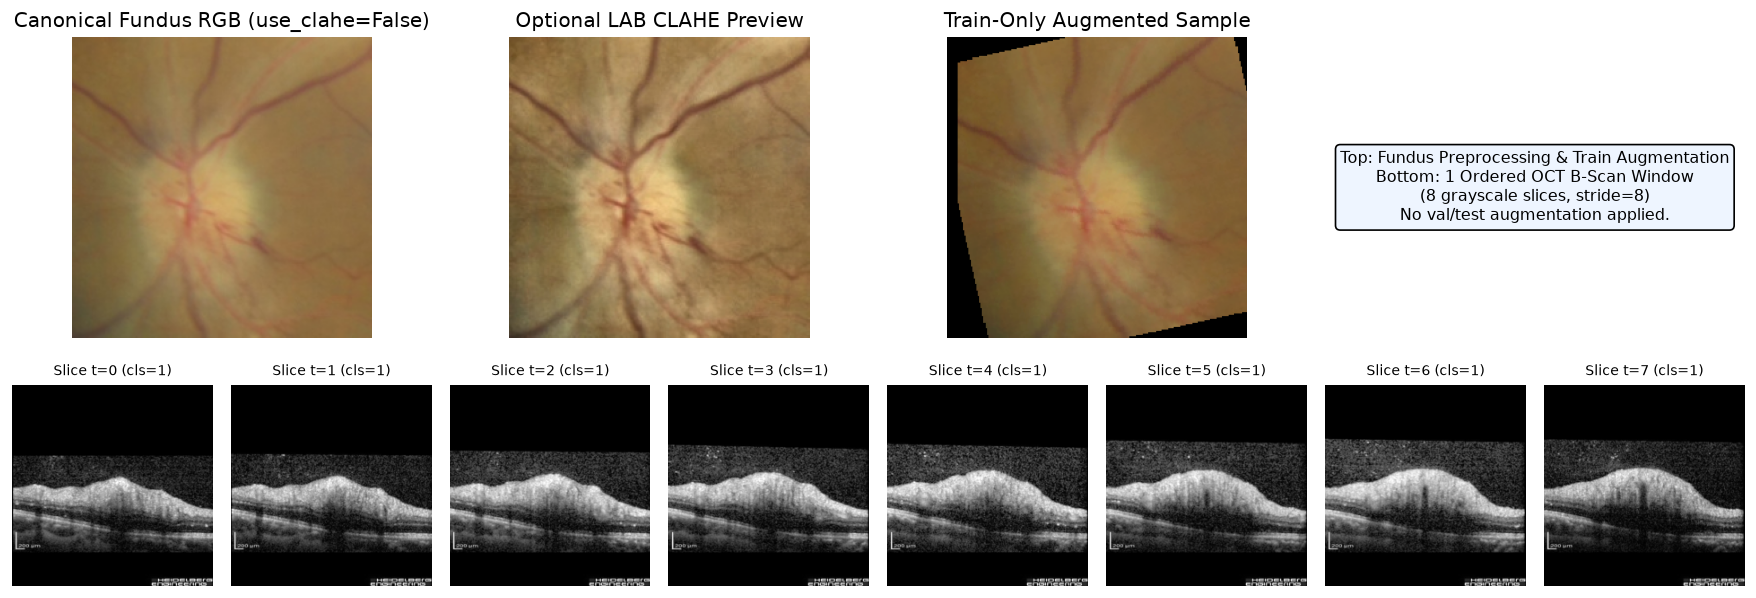

In [6]:
from src.data.augmentation import build_eval_transform, build_train_augmentations
from src.data.datasets import OCTSequenceDataset
from src.data.preprocessing import load_preprocessed_pil

fundus_df = pd.read_csv("data/splits/fundus_splits.csv")
sample_f_path = Path(fundus_df[fundus_df["label"] == "Papilledema"].iloc[0]["image_path"])
raw_f = load_preprocessed_pil(sample_f_path, modality="fundus", image_size=224, use_clahe=False)
clahe_f = load_preprocessed_pil(sample_f_path, modality="fundus", image_size=224, use_clahe=True)
aug_tr = build_train_augmentations("fundus", image_size=224)
aug_pil = aug_tr(raw_f)

oct_df = pd.read_csv("data/splits/oct_3class_splits.csv")
oct_tr_seq = OCTSequenceDataset(
    oct_df[oct_df["split"] == "train"],
    seq_len=cfg["oct"]["sequence_length"],
    stride=cfg["oct"]["sequence_stride"],
    image_size=224,
    is_train=False,
    mean=cfg["oct"]["normalize_mean"],
    std=cfg["oct"]["normalize_std"],
)
oct_va_seq = OCTSequenceDataset(
    oct_df[oct_df["split"] == "val"],
    seq_len=cfg["oct"]["sequence_length"],
    stride=cfg["oct"]["sequence_stride"],
    image_size=224,
    is_train=False,
    mean=cfg["oct"]["normalize_mean"],
    std=cfg["oct"]["normalize_std"],
)
oct_te_seq = OCTSequenceDataset(
    oct_df[oct_df["split"] == "test"],
    seq_len=cfg["oct"]["sequence_length"],
    stride=cfg["oct"]["sequence_stride"],
    image_size=224,
    is_train=False,
    mean=cfg["oct"]["normalize_mean"],
    std=cfg["oct"]["normalize_std"],
)
(seq_tensor, seq_mask), seq_label = oct_te_seq[0]

print(f"OCT sequence datasets -> train={len(oct_tr_seq)}, val={len(oct_va_seq)}, test={len(oct_te_seq)} | window tensor shape: {tuple(seq_tensor.shape)} | valid len: {int(seq_mask.sum())}")

fig = plt.figure(figsize=(15, 5.5))
gs = fig.add_gridspec(2, 8, height_ratios=[1, 1])

ax1 = fig.add_subplot(gs[0, :2])
ax1.imshow(raw_f); ax1.set_title("Canonical Fundus RGB (use_clahe=False)"); ax1.axis("off")

ax2 = fig.add_subplot(gs[0, 2:4])
ax2.imshow(clahe_f); ax2.set_title("Optional LAB CLAHE Preview"); ax2.axis("off")

ax3 = fig.add_subplot(gs[0, 4:6])
ax3.imshow(aug_pil); ax3.set_title("Train-Only Augmented Sample"); ax3.axis("off")

ax_note = fig.add_subplot(gs[0, 6:])
ax_note.text(0.5, 0.5, "Top: Fundus Preprocessing & Train Augmentation\nBottom: 1 Ordered OCT B-Scan Window\n(8 grayscale slices, stride=8)\nNo val/test augmentation applied.", ha="center", va="center", fontsize=9.5, bbox=dict(boxstyle="round", facecolor="#eef5ff"))
ax_note.axis("off")

valid_n = int(seq_mask.sum())
for t in range(8):
    axt = fig.add_subplot(gs[1, t])
    if t < valid_n:
        sl = np.clip(seq_tensor[t, 0].numpy() * 0.5 + 0.5, 0, 1)
        axt.imshow(sl, cmap="gray")
        axt.set_title(f"Slice t={t} (cls={seq_label})", fontsize=8.5)
    else:
        axt.set_title(f"Pad t={t}", fontsize=8.5)
    axt.axis("off")

plt.tight_layout()
plt.show()

## 7. Architecture Portfolio & Parameter Comparison

All 10 model architectures are constructed exclusively via `src/models/model_factory.build_model`:
- **CNN Family (3 models):** `resnet50`, `densenet121`, `efficientnet_b0` (ImageNet-pretrained torchvision backbones adapted for 3-channel Fundus or 1-channel OCT and 3/4 target classes).
- **Standalone RNN Family (2 models):** `lstm`, `bilstm` (`OrderedRNNClassifier`). For 2D image tracks, `_image_to_ordered_patches` partitions each `224x224` image into ordered `32x32` spatial patches (`patch_size=32`, `7x7 = 49` tokens in raster scan order) with learnable positional embeddings; for `oct_sequence`, `slice_stem` encodes each B-scan via a compact convolutional stem + `AdaptiveAvgPool2d((2, 2))` across the ordered slices before LSTM/BiLSTM aggregation.
- **Hybrid CNN–RNN Family (3 models):** `resnet50_lstm`, `resnet50_bilstm`, `efficientnet_b0_bilstm` (`HybridCNNRNN`). In image mode, spatial CNN feature maps `(B, D, 7, 7)` are flattened in raster scan order (`49` spatial tokens) with positional embeddings before LSTM/BiLSTM modeling; in sequence mode, CNN pooled per-slice embeddings `(B, T, D)` are passed through `pack_padded_sequence` along the B-scan slice axis `T=8`.
- **Baselines (2 models):** `mlp` (`MLPBaseline` over spatially pooled pixels `16x16`) and `autoencoder_classifier` (`AutoencoderClassifier` with convolutional encoder/decoder pre-trained 5 epochs via MSE reconstruction before supervised classification).

In [7]:
from src.models.model_factory import build_model, count_parameters

arch_rows = []
seq_models = set(cfg["experiments"]["oct_sequence"]["models"])
for mname, mcfg in cfg["models"].items():
    m3_f = build_model(mname, num_classes=3, in_channels=3, cfg=cfg)
    m3_o = build_model(mname, num_classes=3, in_channels=1, cfg=cfg)
    m4_o = build_model(mname, num_classes=4, in_channels=1, cfg=cfg)
    p3_f = count_parameters(m3_f)
    p3_o = count_parameters(m3_o)
    p4_o = count_parameters(m4_o)
    arch_rows.append({
        "model": mname,
        "category": mcfg.get("category"),
        "backbone": mcfg.get("backbone", mname if mcfg.get("category") == "cnn" else "-"),
        "bidirectional": bool(mcfg.get("bidirectional", False)),
        "params_fundus_3ch": p3_f["total_params"],
        "params_oct_1ch_3cls": p3_o["total_params"],
        "params_oct_1ch_4cls": p4_o["total_params"],
        "seq_compatible": mname in seq_models,
    })
    del m3_f, m3_o, m4_o

arch_df = pd.DataFrame(arch_rows).sort_values("params_fundus_3ch", ascending=False)
print(arch_df.to_string(index=False))

                 model category        backbone  bidirectional  params_fundus_3ch  params_oct_1ch_3cls  params_oct_1ch_4cls  seq_compatible
       resnet50_bilstm   hybrid        resnet50           True           24446019             24439747             24440004            True
         resnet50_lstm   hybrid        resnet50          False           24247747             24241475             24241604            True
              resnet50      cnn        resnet50          False           23514179             23507907             23509956           False
           densenet121      cnn     densenet121          False            6956931              6950659              6951684           False
efficientnet_b0_bilstm   hybrid efficientnet_b0           True            4748927              4748351              4748608            True
       efficientnet_b0      cnn efficientnet_b0          False            4011391              4010815              4012096           False
                bils

## 8. Real-Data GPU Forward & Backward Verification

Summarizes the real-data GPU verification across all **35 track-model combinations** (`scripts/verify_models_gpu.py`, executed prior to full training) and runs a live GPU forward/backward sanity pass on representative models from each family (`CNN`, `RNN`, `Hybrid CNN-RNN`, `Baseline`, and `OCT Sequence`) using real Fundus & OCT mini-batches.

In [8]:
from src.data.datasets import create_dataloaders
from src.training.losses import build_loss_fn
from src.utils.device import move_inputs_to_device

f_loaders, f_dfs = create_dataloaders(cfg, task="fundus_3class", mode="image", batch_size=8)
o_seq_loaders, o_seq_dfs = create_dataloaders(cfg, task="oct_3class", mode="sequence", batch_size=4)

xb_f, yb_f = next(iter(f_loaders["train"]))
xb_s, yb_s = next(iter(o_seq_loaders["train"]))
f_loss_fn = build_loss_fn(f_dfs["train"]["label_idx"].tolist(), num_classes=3, use_class_weights=True, device=device)
o_loss_fn = build_loss_fn(o_seq_dfs["train"]["label_idx"].tolist(), num_classes=3, use_class_weights=True, device=device)

sanity_checks = []
for track_label, mod_name, in_ch, x_batch, y_batch, lfn in [
    ("fundus_3class", "efficientnet_b0", 3, xb_f, yb_f, f_loss_fn),
    ("fundus_3class", "bilstm", 3, xb_f, yb_f, f_loss_fn),
    ("fundus_3class", "efficientnet_b0_bilstm", 3, xb_f, yb_f, f_loss_fn),
    ("fundus_3class", "autoencoder_classifier", 3, xb_f, yb_f, f_loss_fn),
    ("oct_sequence", "resnet50_bilstm", 1, xb_s, yb_s, o_loss_fn),
]:
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    model = build_model(mod_name, num_classes=3, in_channels=in_ch, cfg=cfg).to(device)
    model.train()
    x_dev = move_inputs_to_device(x_batch, device)
    y_dev = y_batch.to(device)
    model.zero_grad(set_to_none=True)
    with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
        logits = model(x_dev)
        loss = lfn(logits, y_dev)
    loss.backward()
    max_grad = max(float(p.grad.abs().max().item()) for p in model.parameters() if p.grad is not None)
    sanity_checks.append({
        "track": track_label,
        "model": mod_name,
        "in_channels": in_ch,
        "logits_shape": str(tuple(logits.shape)),
        "loss": round(float(loss.item()), 4),
        "max_abs_grad": round(max_grad, 4),
        "cuda_peak_mb": round(get_gpu_memory_mb(device)["peak_allocated_mb"], 1),
    })
    del model, logits, loss, x_dev, y_dev
    clear_gpu_memory()

print(pd.DataFrame(sanity_checks).to_string(index=False))
print("Full 35/35 track-model GPU verification script: scripts/verify_models_gpu.py")

        track                  model  in_channels logits_shape   loss  max_abs_grad  cuda_peak_mb
fundus_3class        efficientnet_b0            3       (8, 3) 1.1047        0.4377         446.5
fundus_3class                 bilstm            3       (8, 3) 1.2512        0.7690         143.5
fundus_3class efficientnet_b0_bilstm            3       (8, 3) 1.0633        1.0957         460.9
fundus_3class autoencoder_classifier            3       (8, 3) 1.0884        0.5557         114.9
 oct_sequence        resnet50_bilstm            1       (4, 3) 1.0034       52.2500        1579.5
Full 35/35 track-model GPU verification script: scripts/verify_models_gpu.py


## 9. Executed Experiment Matrix & Training Convergence Summary

Collects all completed non-smoke experiment runs via `ExperimentManager.collect_completed_runs()` (`exclude_smoke_if_real_exist=True`). Verifies:
- **175 total non-smoke runs** (`50 fundus_3class` + `50 oct_individual` + `25 oct_sequence` + `50 oct_severity`) across the **5 requested seeds `[42, 123, 2024, 3407, 5678]`**.
- Early stopping (`patience=7`, best validation `macro_f1` checkpoint restoration) prevented over-training and accelerated convergence (`~4.34` total GPU training hours across all 175 runs).

In [9]:
runs_df = manager.collect_completed_runs(exclude_smoke_if_real_exist=True)
print("Collected non-smoke runs:", len(runs_df))
print("Smoke runs included     :", int(runs_df["is_smoke"].sum()))
print("Seeds verified          :", sorted(runs_df["seed"].unique().tolist()))
print("Total GPU compute time  :", f"{runs_df['train_duration_sec'].sum() / 3600.0:.2f} hours ({runs_df['train_duration_sec'].sum():.1f} s)")

matrix_summary = (
    runs_df.groupby(["track", "mode"])
    .agg(
        models=("model", "nunique"),
        seeds=("seed", "nunique"),
        total_runs=("exp_id", "count"),
        mean_best_epoch=("best_epoch", "mean"),
        mean_train_sec=("train_duration_sec", "mean"),
    )
    .round(2)
    .reset_index()
)
print("\n=== Experiment Matrix by Track ===")
print(matrix_summary.to_string(index=False))

Collected non-smoke runs: 175
Smoke runs included     : 0
Seeds verified          : [42, 123, 2024, 3407, 5678]
Total GPU compute time  : 4.34 hours (15635.7 s)

=== Experiment Matrix by Track ===
         track     mode  models  seeds  total_runs  mean_best_epoch  mean_train_sec
 fundus_3class    image      10      5          50            13.32          130.64
oct_individual    image      10      5          50             7.54           74.69
  oct_sequence sequence       5      5          25             2.96           52.85
  oct_severity    image      10      5          50            13.12           80.96


## 10. Track 1 Results — Kim Fundus 3-Class Classification

### Key Quantitative Findings (`fundus_3class`, 10 models x 5 seeds = 50 runs, `test n=205` across `190` clusters)
- **Top Performers:** `efficientnet_b0` leads with **Macro F1 = `0.9835 ± 0.0055`** (`Accuracy = 0.9883`, `Balanced Accuracy = 0.9818`, `ROC-AUC = 0.9998`, `PR-AUC = 0.9994`), closely followed by hybrid `efficientnet_b0_bilstm` (`Macro F1 = 0.9806 ± 0.0100`, highest `Balanced Accuracy = 0.9820`), `densenet121` (`0.9795 ± 0.0054`), `resnet50` (`0.9779 ± 0.0034`), `resnet50_bilstm` (`0.9779 ± 0.0085`), and `resnet50_lstm` (`0.9684 ± 0.0084`).
- **Baselines & Standalone RNNs:** `autoencoder_classifier` (`0.8691 ± 0.0107`, fastest at `1.72 ms/sample`) and `mlp` (`0.8018 ± 0.0176`) substantially outperform standalone patch-strip RNNs (`lstm = 0.7522 ± 0.0132`, `bilstm = 0.7230 ± 0.0480`) without CNN convolutional spatial hierarchy.
- **No Meaningful Hybrid Gain Over Pure CNN on 2D Fundus:** Adding recurrent layers onto ResNet-50 or EfficientNet-B0 does **not** statistically surpass the standalone CNN backbones (`Holm-adjusted p = 1.0`).

=== Kim Fundus Ranked Comparison (5-Seed Mean & Std) ===
                 model category  macro_f1_mean  macro_f1_std  balanced_accuracy_mean  accuracy_mean  macro_precision_mean  macro_recall_mean  roc_auc_mean  pr_auc_mean  total_params  inference_latency_ms
       efficientnet_b0      cnn         0.9835        0.0055                  0.9818         0.9883                0.9861             0.9818        0.9998       0.9994       4011391                2.5411
efficientnet_b0_bilstm   hybrid         0.9806        0.0100                  0.9820         0.9854                0.9795             0.9820        0.9986       0.9957       4748927                2.5661
           densenet121      cnn         0.9795        0.0054                  0.9786         0.9844                0.9805             0.9786        0.9995       0.9983       6956931                3.2520
              resnet50      cnn         0.9779        0.0034                  0.9771         0.9834                0.9796      

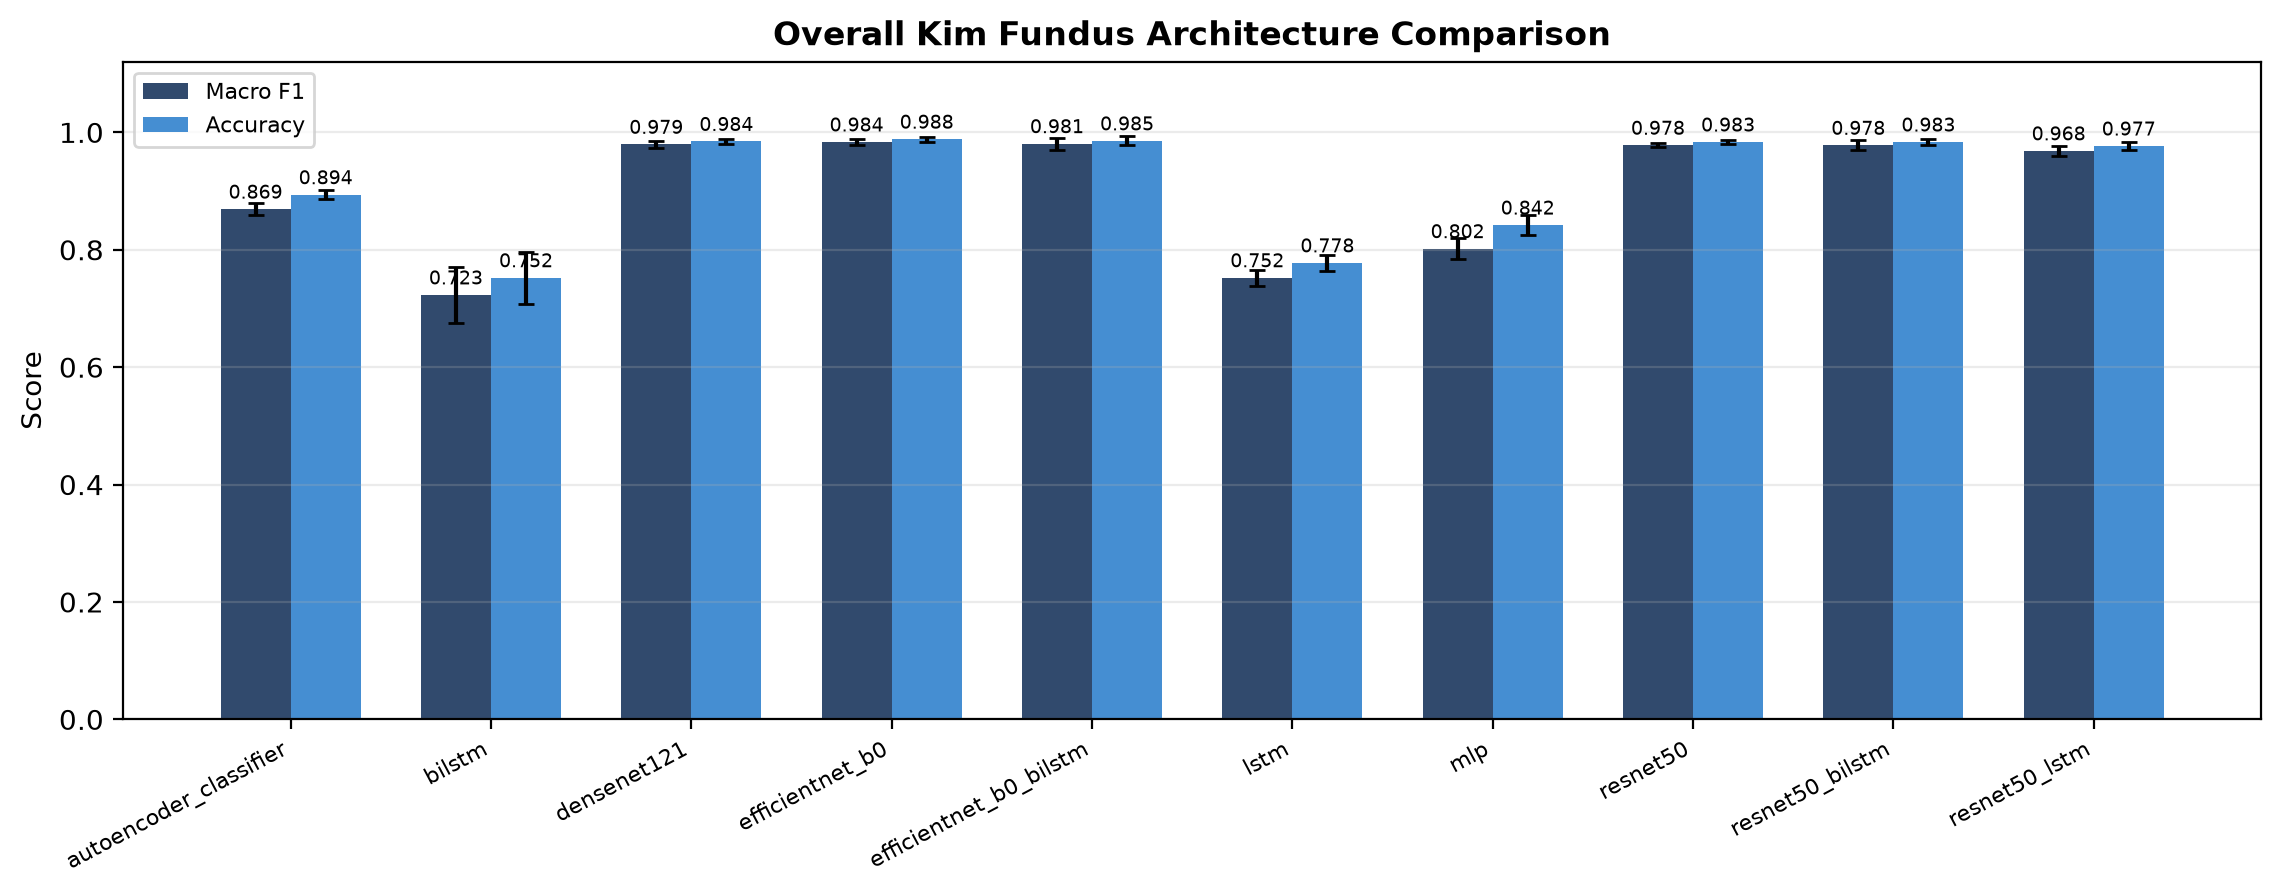

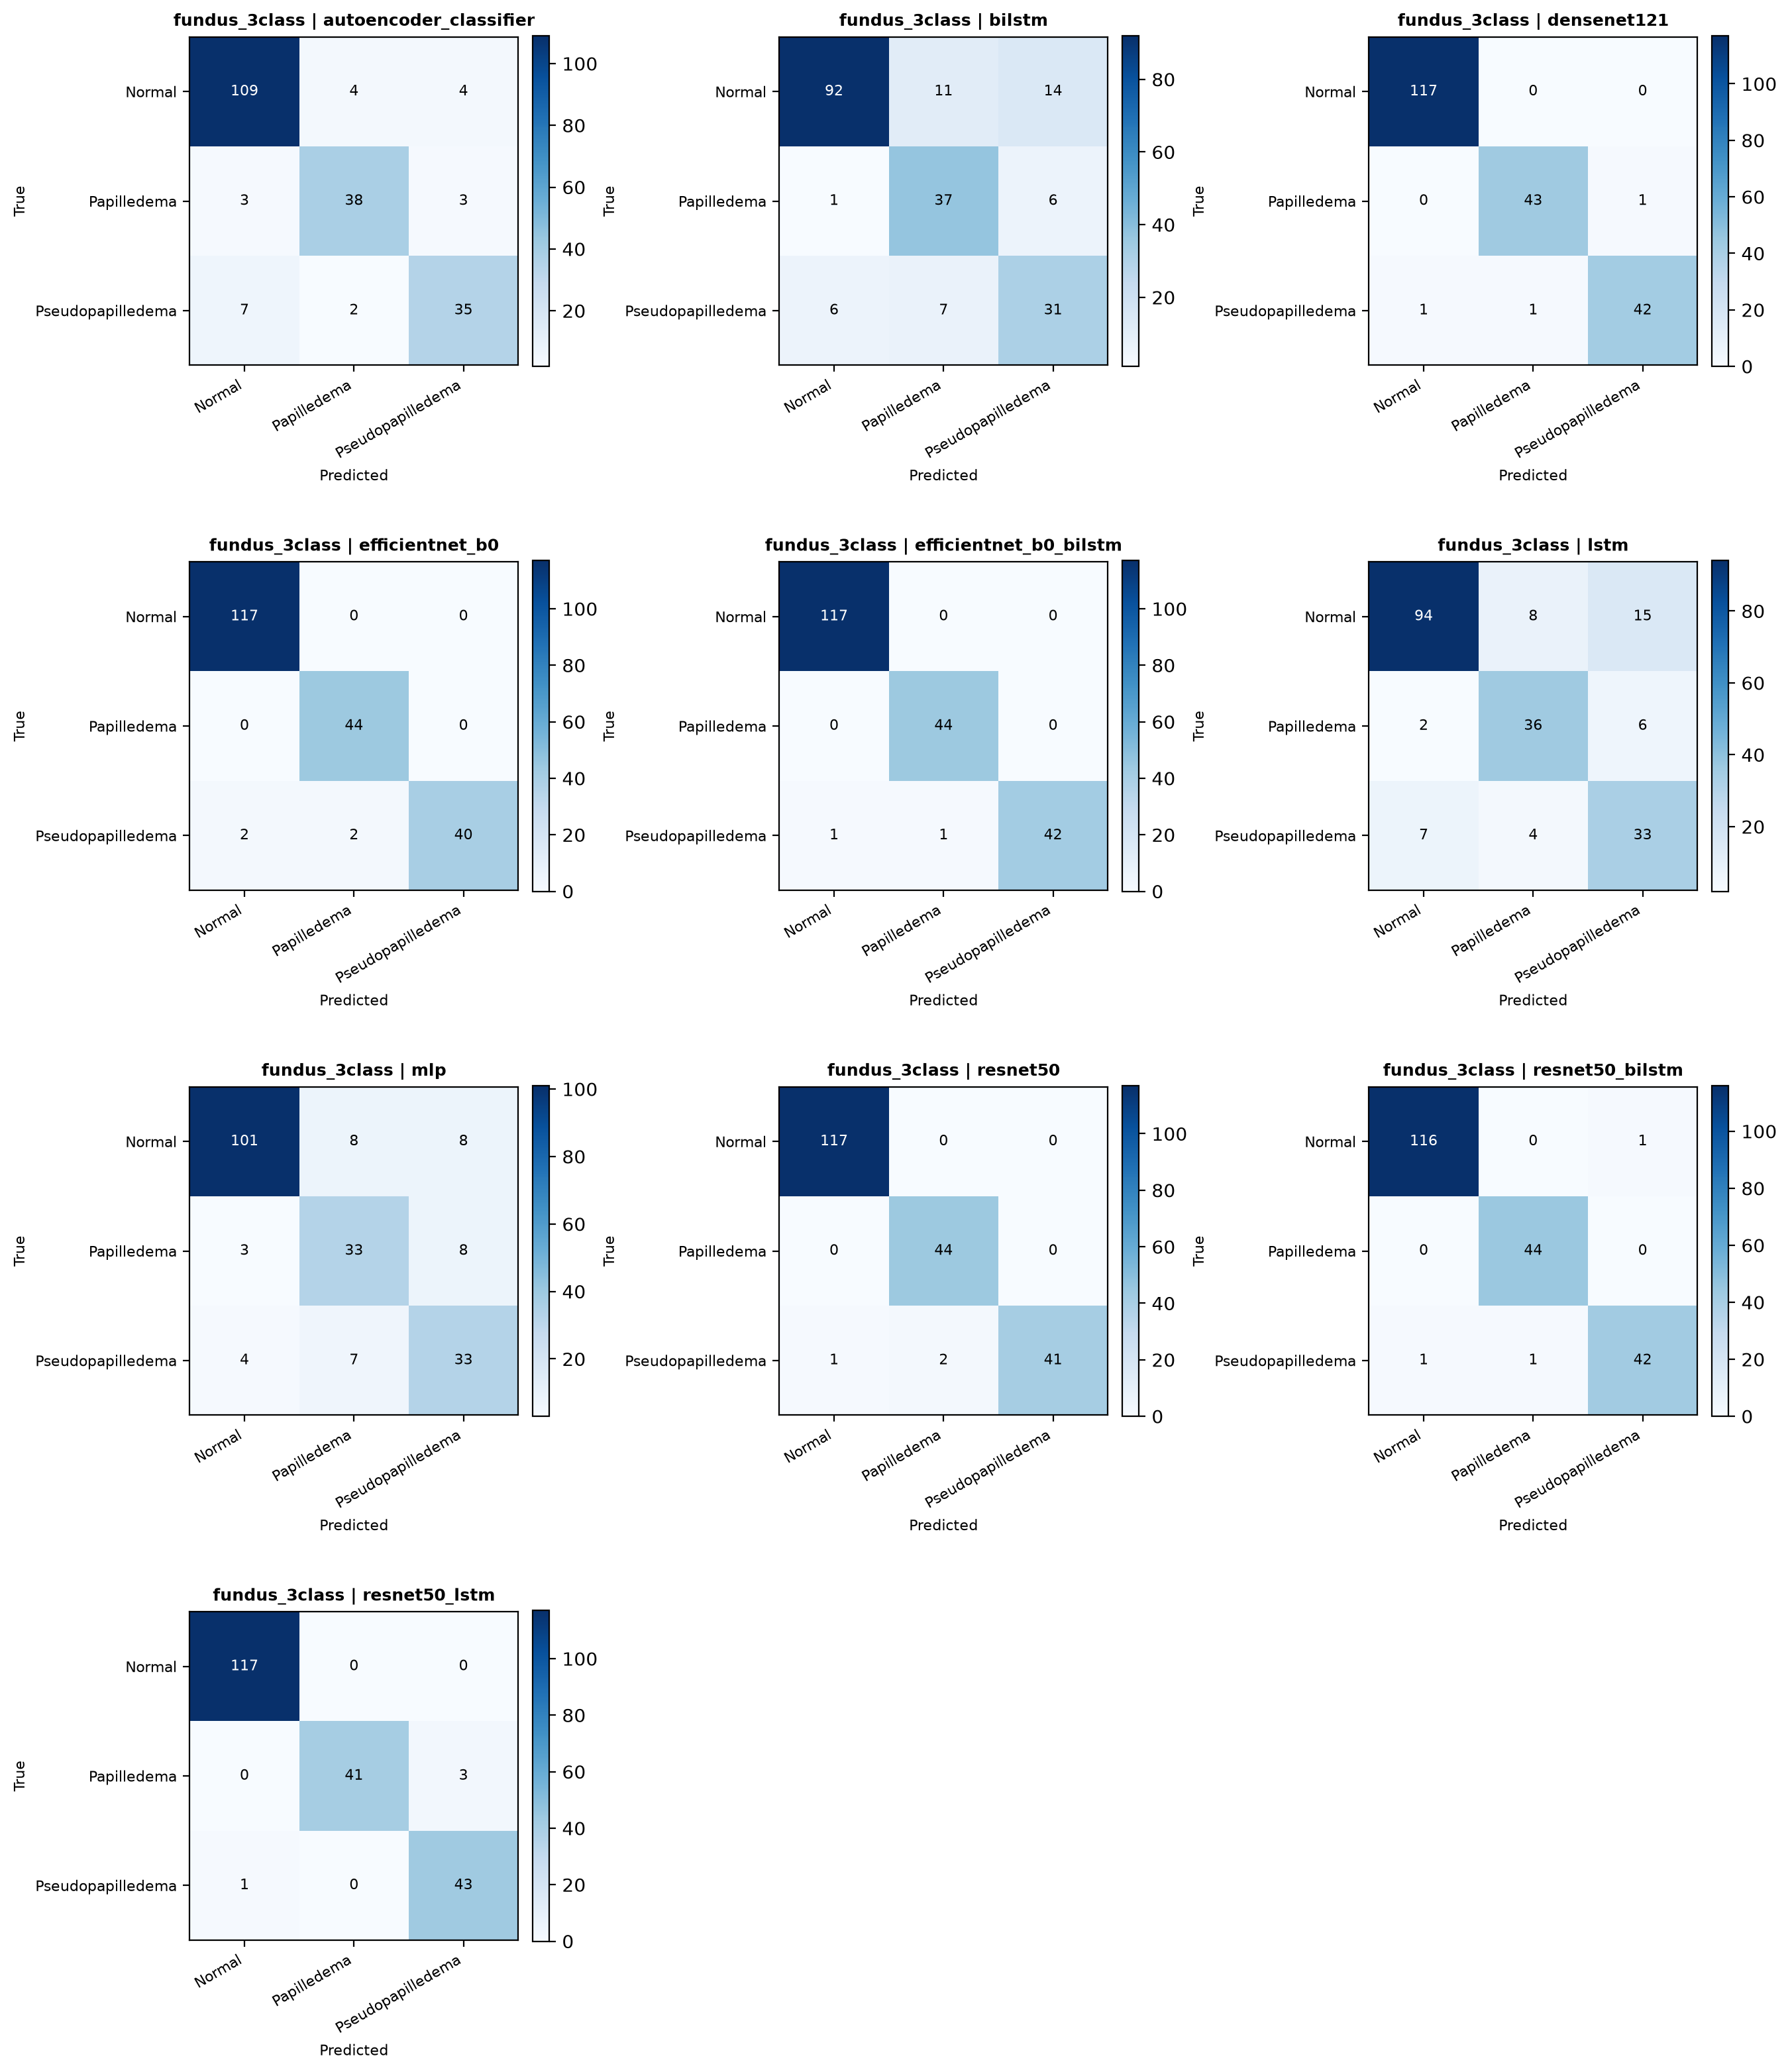

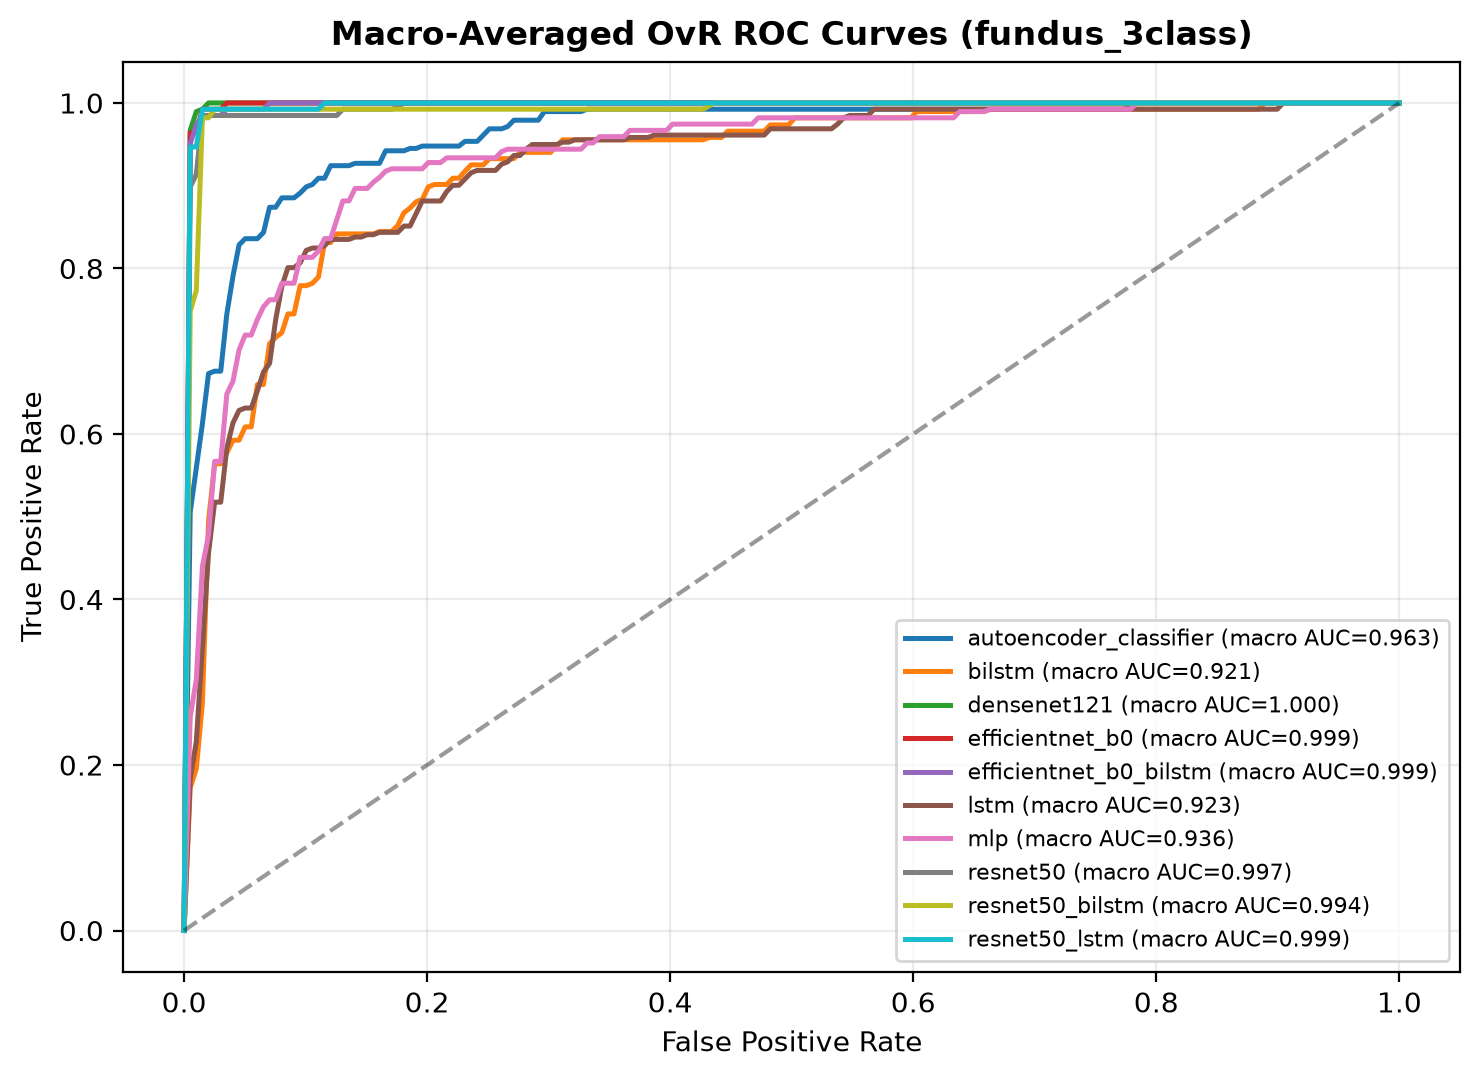

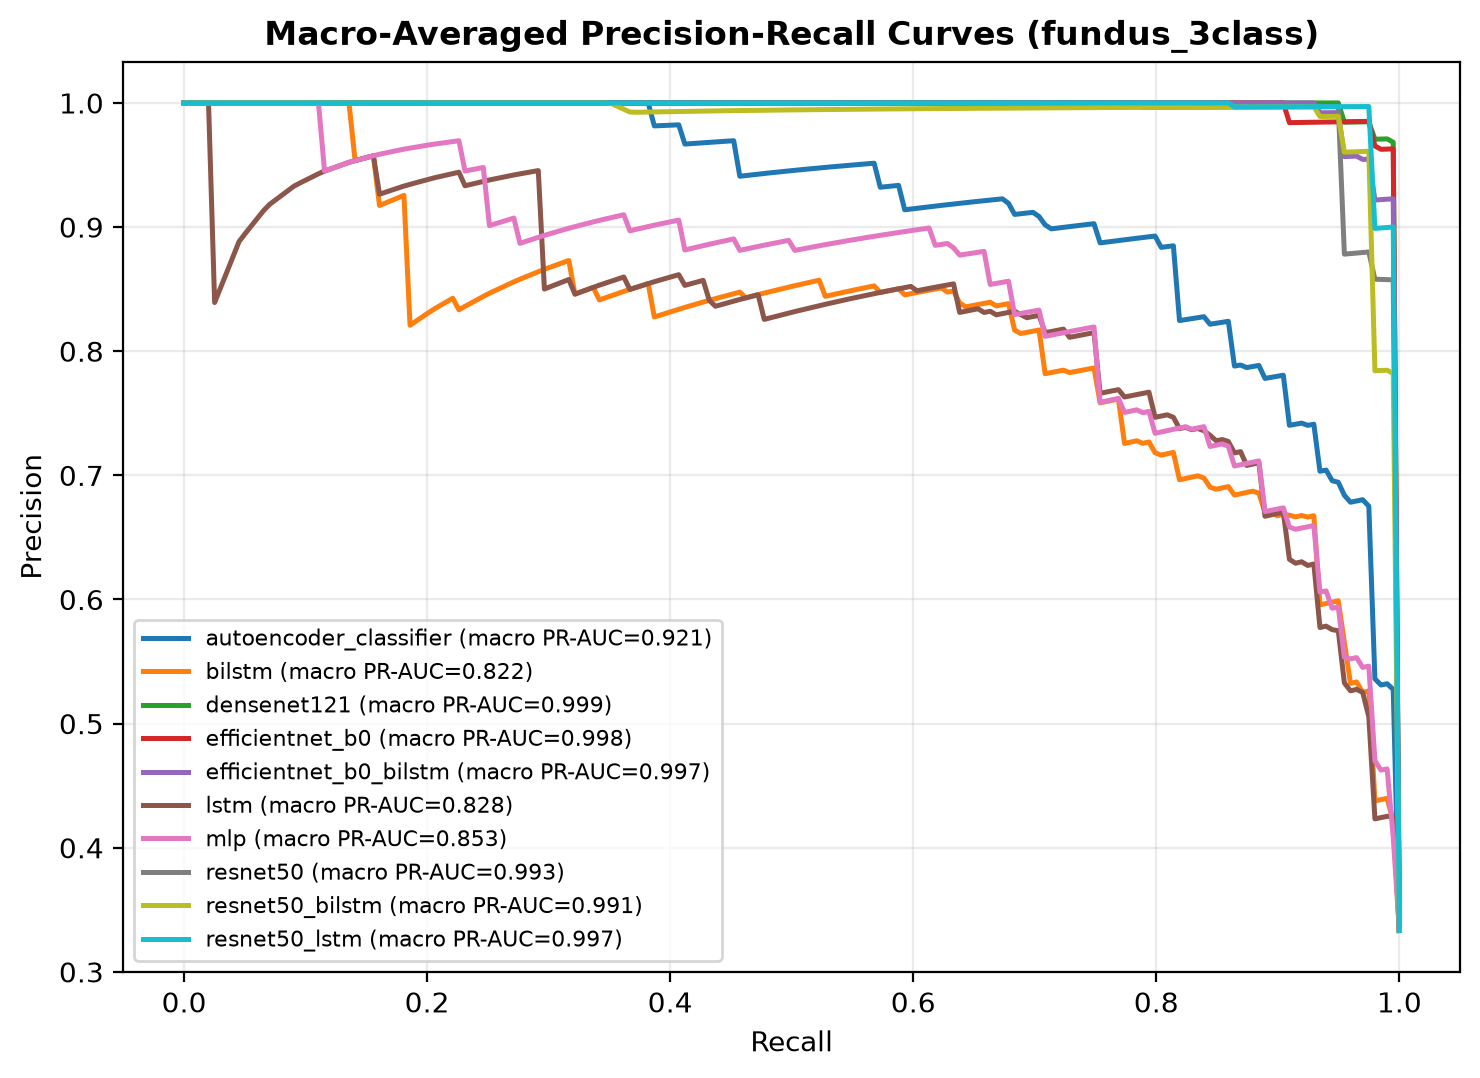

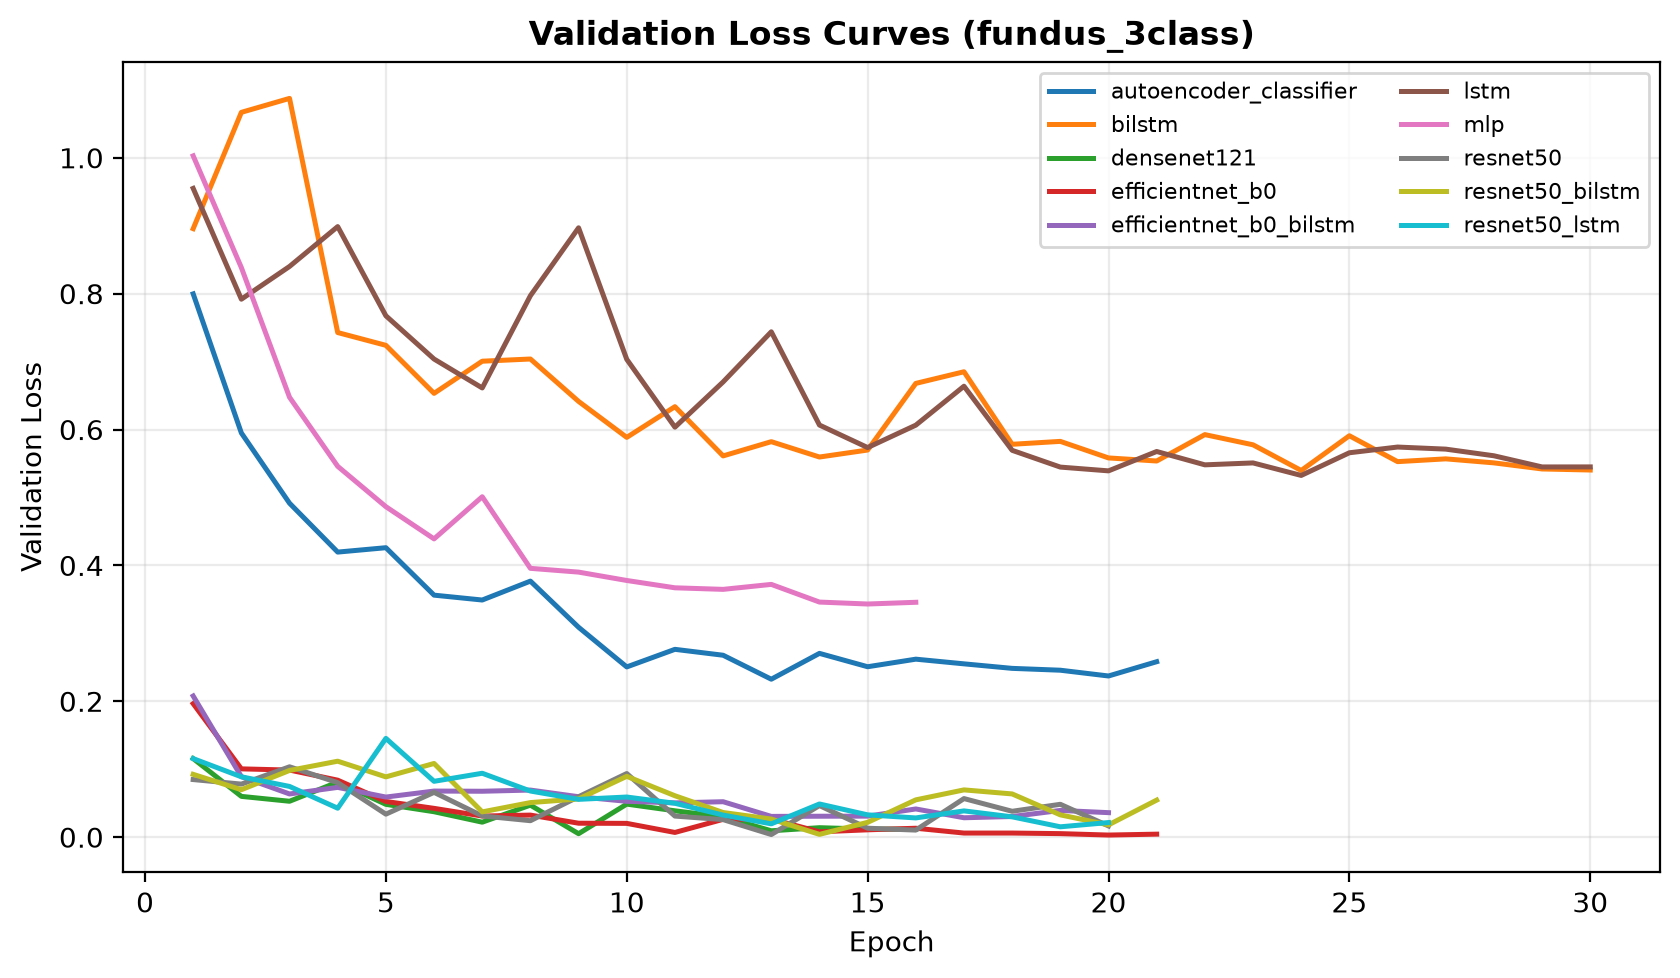

In [10]:
f_tbl = pd.read_csv("results/tables/model_comparison.csv")
ci_df = pd.read_csv("results/statistical_analysis/confidence_intervals.csv")
f_ci = ci_df[(ci_df["track"] == "fundus_3class") & (ci_df["metric"] == "macro_f1")][["model", "point_estimate", "ci95_low", "ci95_high", "n_groups"]]

print("=== Kim Fundus Ranked Comparison (5-Seed Mean & Std) ===")
cols_show = ["model", "category", "macro_f1_mean", "macro_f1_std", "balanced_accuracy_mean", "accuracy_mean", "macro_precision_mean", "macro_recall_mean", "roc_auc_mean", "pr_auc_mean", "total_params", "inference_latency_ms"]
print(f_tbl[cols_show].round(4).to_string(index=False))
print("\n=== Grouped Bootstrap 95% CIs (Representative Checkpoint per Model, 190 Test Clusters) ===")
print(f_ci.sort_values("point_estimate", ascending=False).round(4).to_string(index=False))

for fig_name in [
    "results/figures/overall_fundus_comparison.png",
    "results/figures/fundus_3class_confusion_matrices.png",
    "results/figures/fundus_3class_roc_curves.png",
    "results/figures/fundus_3class_pr_curves.png",
    "results/figures/fundus_3class_validation_loss_curves.png",
]:
    display(IPyImage(filename=fig_name))

## 11. Track 2 Results — Original OCT 3-Class Individual B-Scan Classification

### Key Quantitative Findings (`oct_individual`, 10 models x 5 seeds = 50 runs, `test n=183` across `4` sequence clusters)
- **Fast CNN & Hybrid Saturation:** `densenet121` (`Macro F1 = 0.9928 ± 0.0099`, `Accuracy = 0.9978`, `ROC/PR AUC = 1.0000`), `efficientnet_b0` (`0.9903 ± 0.0000`), and `resnet50_bilstm` (`0.9863 ± 0.0255`) achieve near-ceiling separation within **1–4 epochs** (`best_epoch = 1.2–3.4`).
- **Imbalance & Pixel-RNN Limitation:** Test accuracy for `mlp` (`0.8678`) masks much lower minority-sensitive `macro_f1` (`0.7164`) because `Papilledema` dominates OCT (`146/183` test slices). Standalone pixel-patch `lstm` (`0.5585 ± 0.1212`) and `bilstm` (`0.6517 ± 0.0461`) trail CNN/Hybrid models by `0.33–0.43` Macro F1.
- **Cluster Diversity Caveat:** All `183` OCT test B-scans stem from only **4 sequence clusters** (`Normal` and `Pseudopapilledema` have 1 inferred prefix each), yielding degenerate or overly optimistic test-slice bootstrap CIs and `~1.0` AUC values.

=== OCT Individual B-Scan Ranked Comparison (5-Seed Mean & Std) ===
                 model category  macro_f1_mean  macro_f1_std  balanced_accuracy_mean  accuracy_mean  macro_precision_mean  macro_recall_mean  roc_auc_mean  pr_auc_mean  total_params  inference_latency_ms
           densenet121      cnn         0.9928        0.0099                  0.9933         0.9978                0.9926             0.9933        1.0000       1.0000       6950659                3.8899
       efficientnet_b0      cnn         0.9903        0.0000                  0.9833         0.9945                0.9977             0.9833        0.9997       0.9985       4010815                3.2533
       resnet50_bilstm   hybrid         0.9863        0.0255                  0.9858         0.9934                0.9886             0.9858        0.9997       0.9996      24439747                3.8744
efficientnet_b0_bilstm   hybrid         0.9807        0.0154                  0.9820         0.9913                0

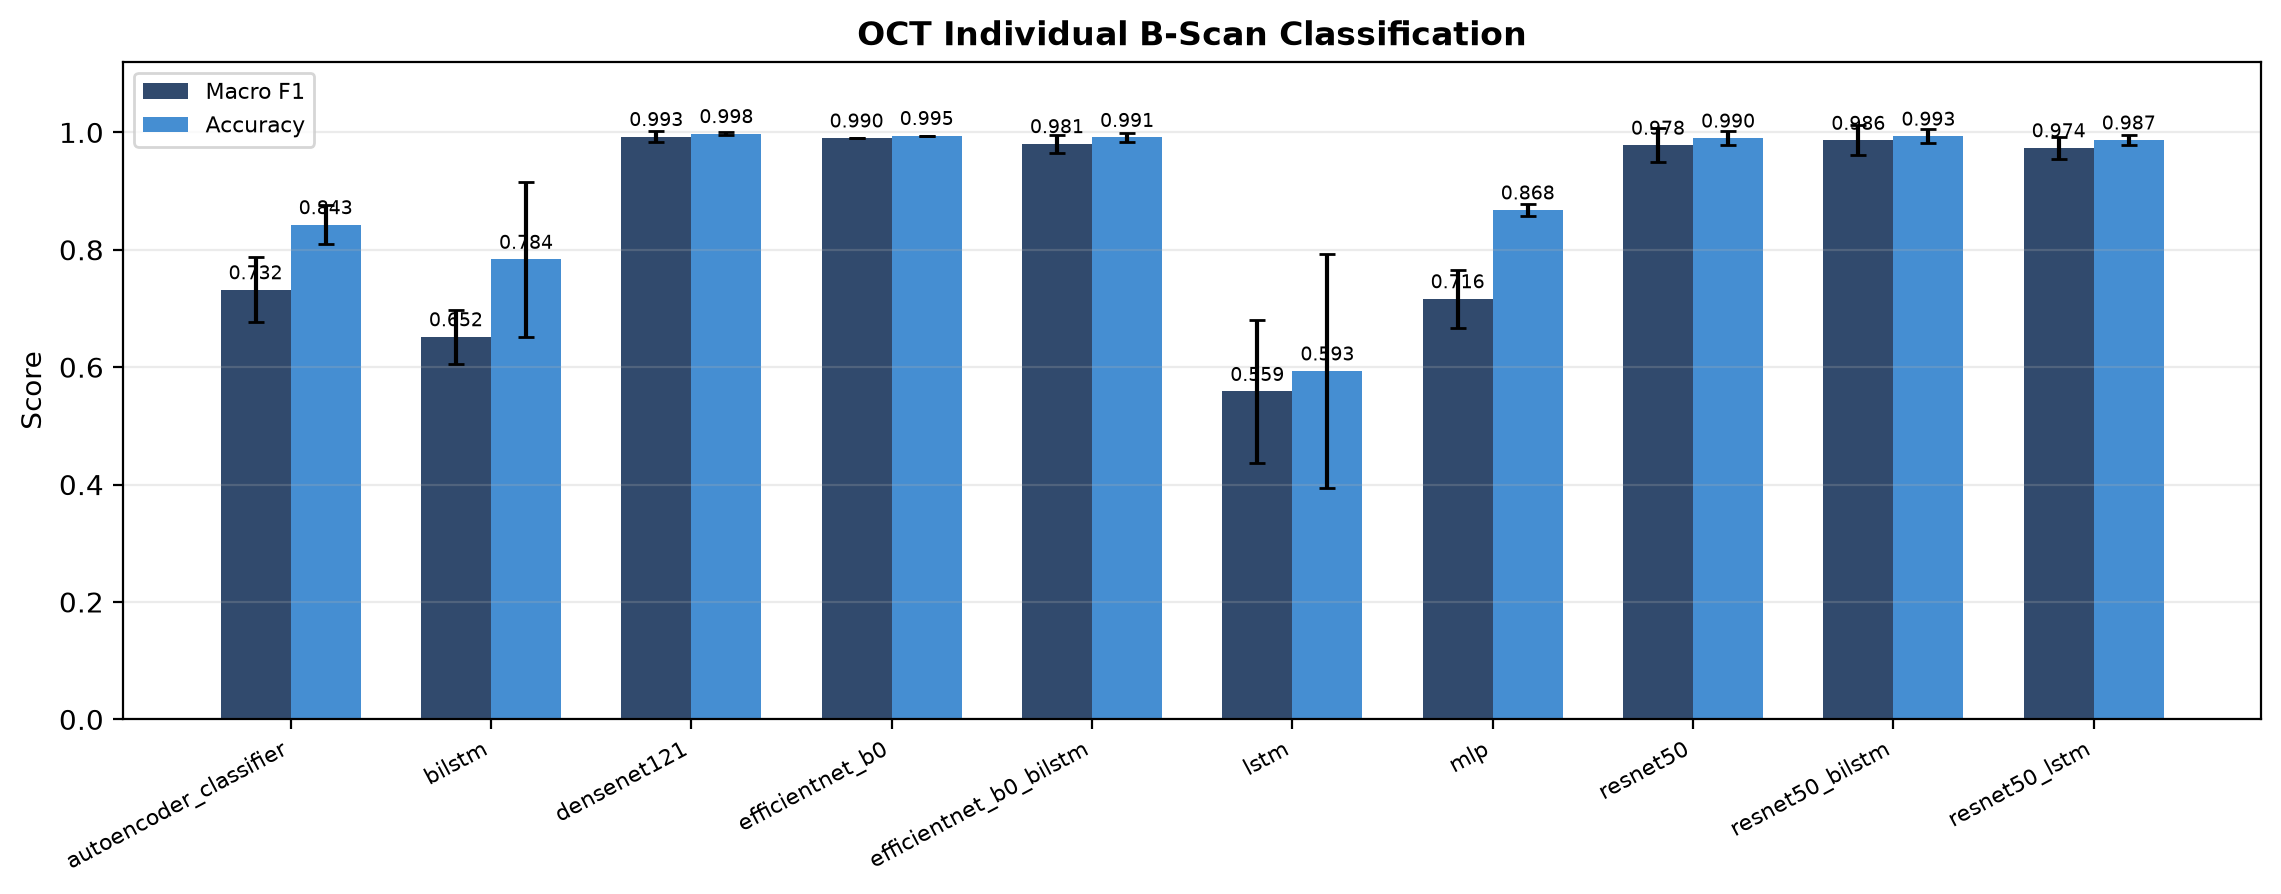

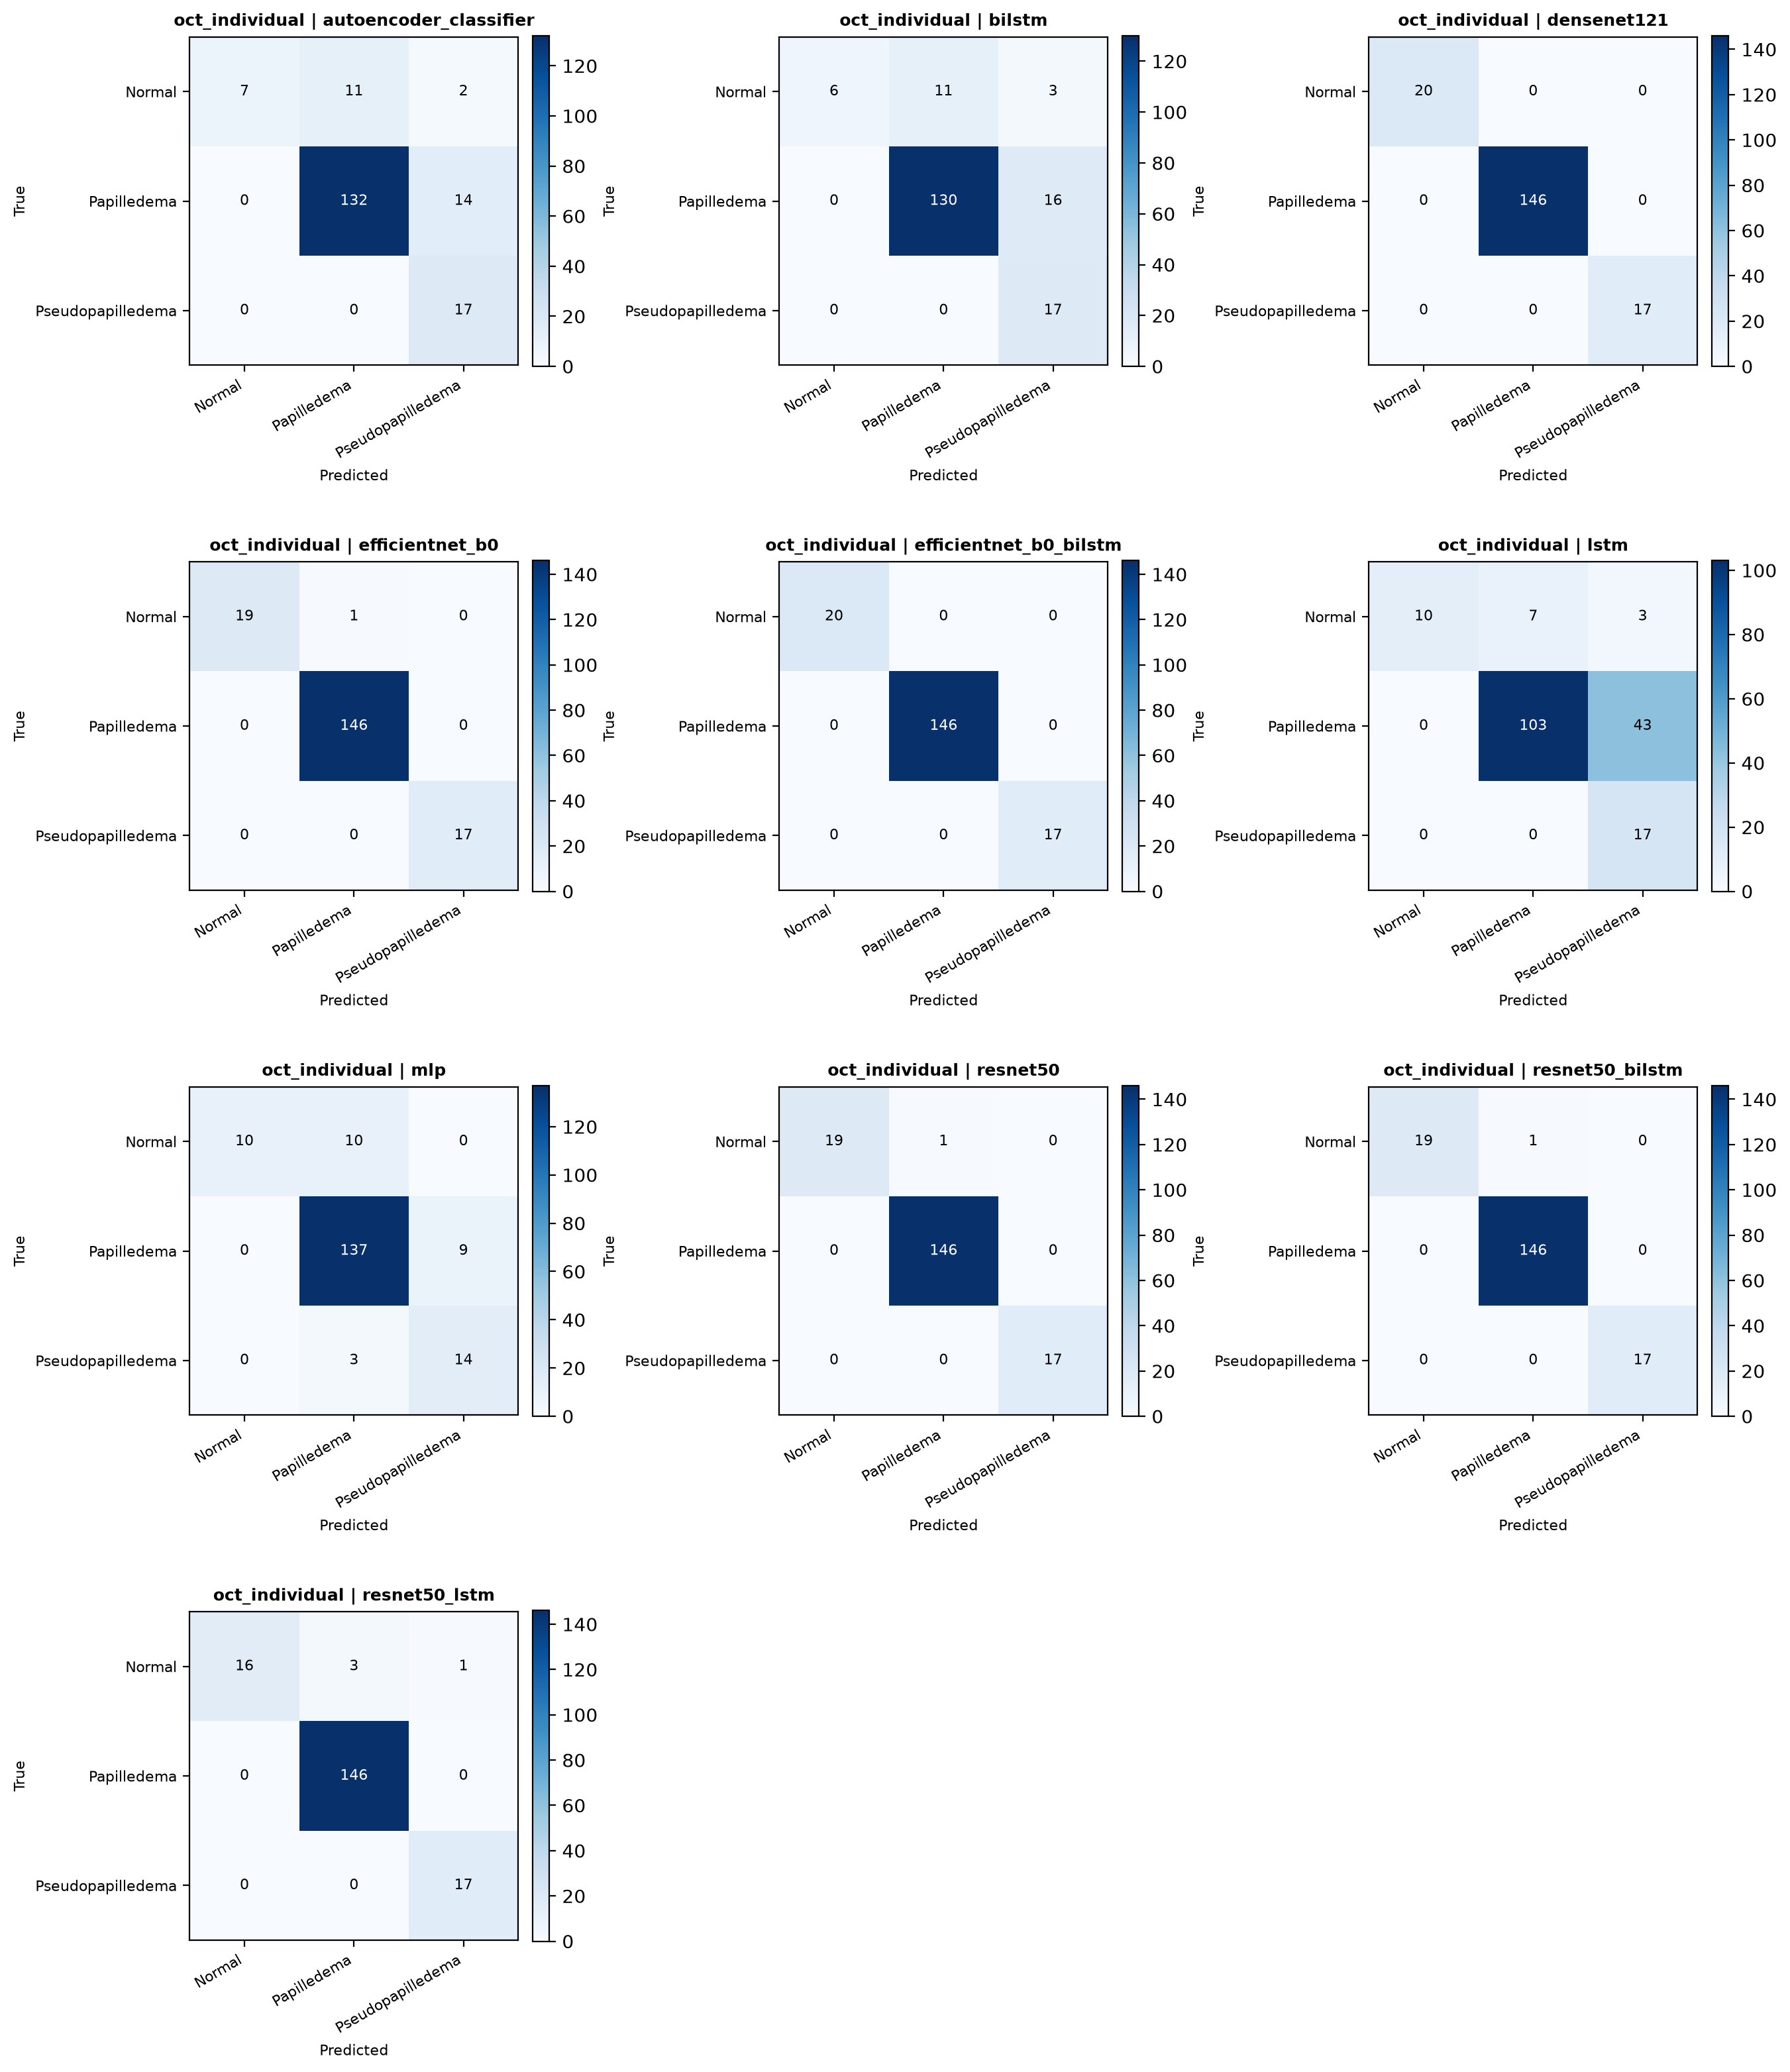

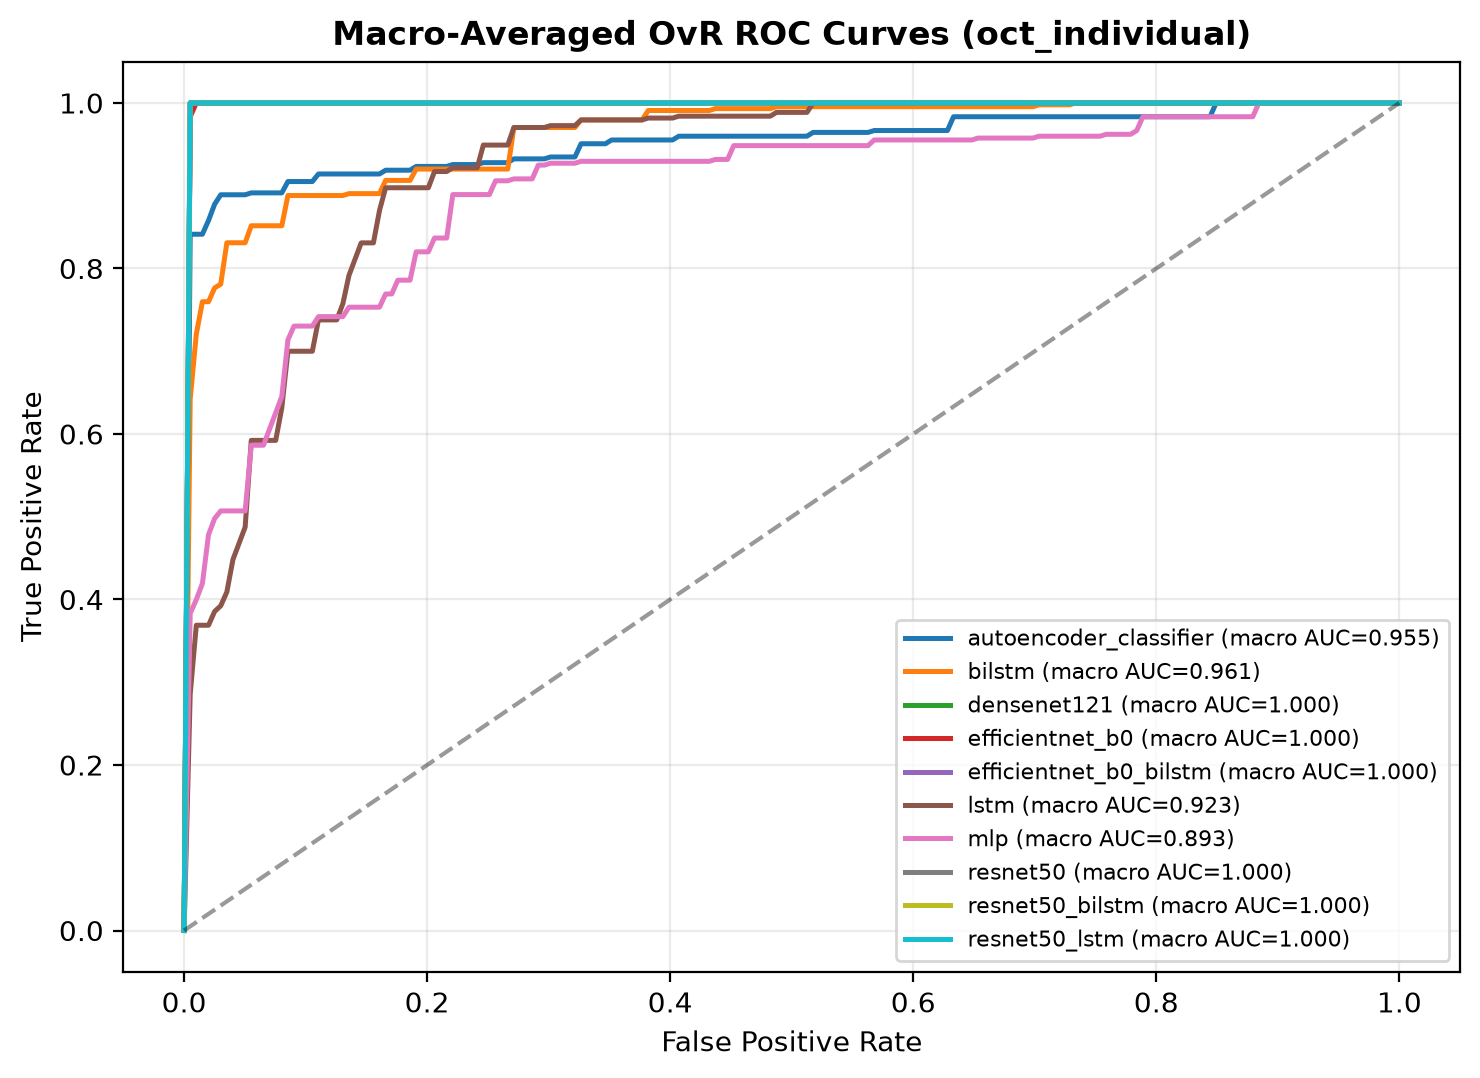

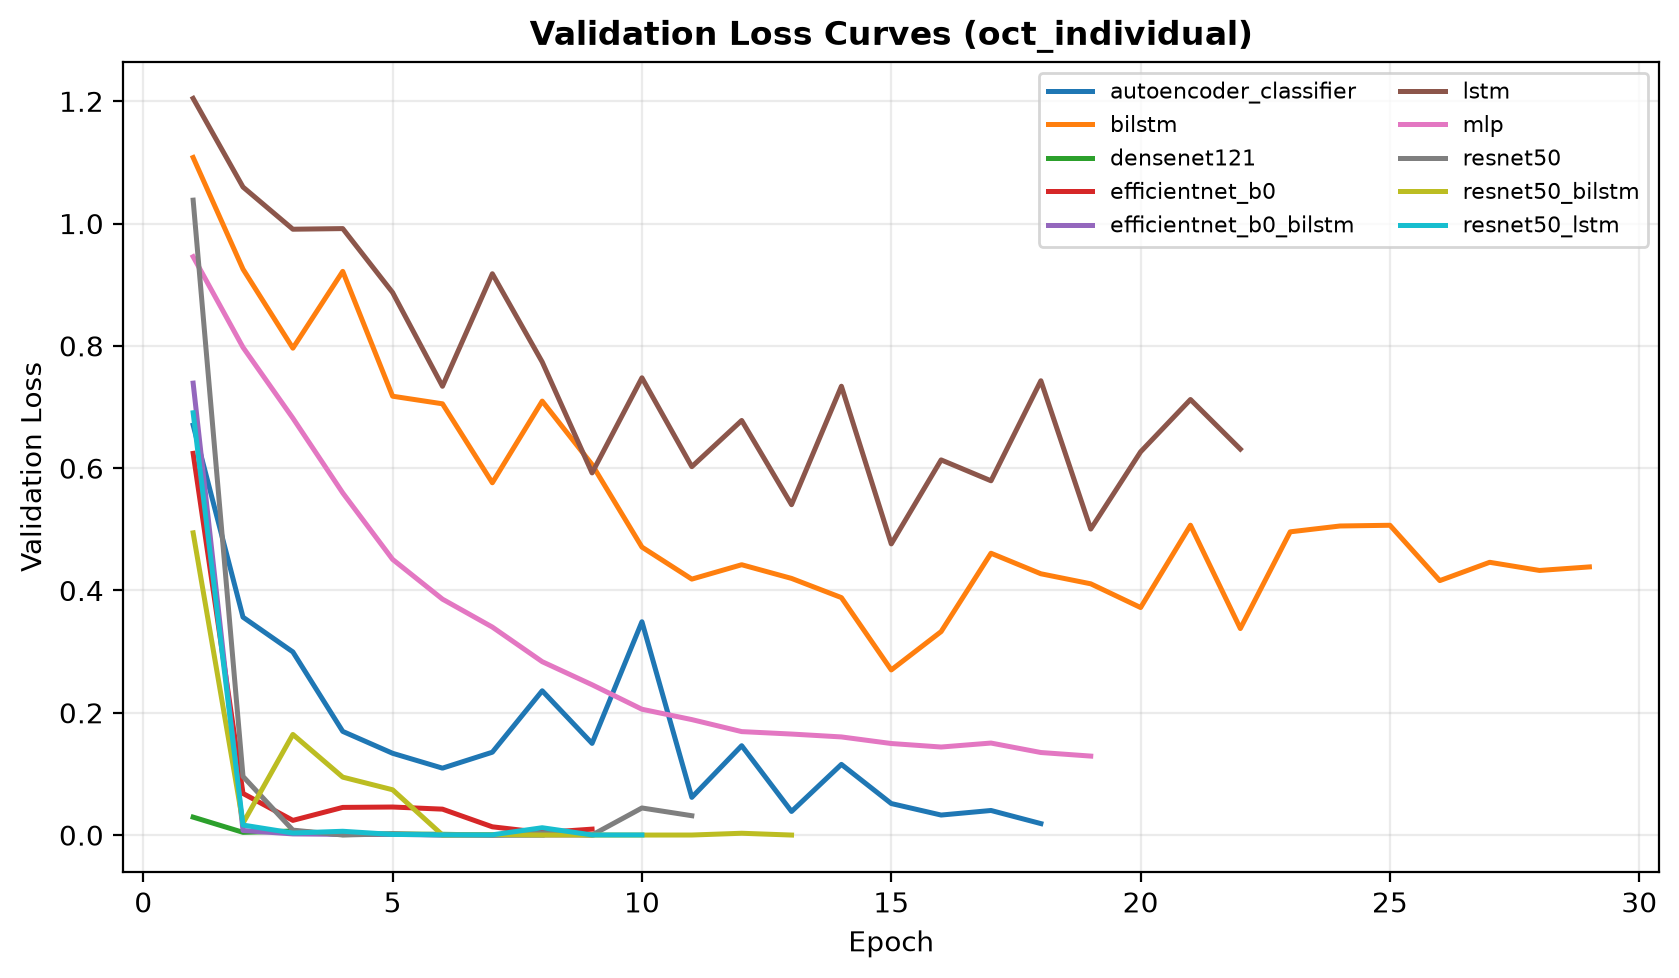

In [11]:
o_ind_tbl = pd.read_csv("results/tables/oct_individual_comparison.csv")
o_ind_ci = ci_df[(ci_df["track"] == "oct_individual") & (ci_df["metric"] == "macro_f1")][["model", "point_estimate", "ci95_low", "ci95_high", "n_groups"]]

print("=== OCT Individual B-Scan Ranked Comparison (5-Seed Mean & Std) ===")
print(o_ind_tbl[["model", "category", "macro_f1_mean", "macro_f1_std", "balanced_accuracy_mean", "accuracy_mean", "macro_precision_mean", "macro_recall_mean", "roc_auc_mean", "pr_auc_mean", "total_params", "inference_latency_ms"]].round(4).to_string(index=False))
print("\n=== Grouped Bootstrap 95% CIs (Note: Only 4 Test Sequence Clusters) ===")
print(o_ind_ci.sort_values("point_estimate", ascending=False).round(4).to_string(index=False))

for fig_name in [
    "results/figures/oct_individual_comparison.png",
    "results/figures/oct_individual_confusion_matrices.png",
    "results/figures/oct_individual_roc_curves.png",
    "results/figures/oct_individual_validation_loss_curves.png",
]:
    display(IPyImage(filename=fig_name))

## 12. Track 3 Results — Original OCT 3-Class Ordered Sequence Classification

### Key Quantitative Findings (`oct_sequence`, 5 sequence-compatible models x 5 seeds = 25 runs, `test n=23` 8-slice windows from `4` sequences)
- **Sharp Architectural Contrast:** Integrating ordered B-scan slices (`seq_len=8, stride=8`) via Hybrid CNN–RNN clearly succeeds (`resnet50_bilstm Macro F1 = 0.9849 ± 0.0338`, `Accuracy = 0.9913`, `ROC/PR AUC = 1.0000`; `efficientnet_b0_bilstm = 0.9142 ± 0.1138`; `resnet50_lstm = 0.8608 ± 0.2046`).
- **Failure of Standalone Pixel-Stem RNNs on Small Sequence Count:** Without pretrained convolutional spatial representation, `bilstm` (`0.3385 ± 0.1024`) and `lstm` (`0.2760 ± 0.0279`) collapse largely toward majority `Papilledema` prediction (`18/23` test windows).
- **Bidirectional Context Advantage:** `resnet50_bilstm` reduces inter-seed variance over unidirectional `resnet50_lstm` (`std 0.0338 vs 0.2046`). Results remain constrained by small test sequence count (`4` test sequences, `23` windows).

=== OCT Ordered Sequence Ranked Comparison (5-Seed Mean & Std) ===
                 model category  macro_f1_mean  macro_f1_std  balanced_accuracy_mean  accuracy_mean  macro_precision_mean  macro_recall_mean  roc_auc_mean  pr_auc_mean  total_params  inference_latency_ms
       resnet50_bilstm   hybrid         0.9849        0.0338                  0.9778         0.9913                0.9965             0.9778        1.0000       1.0000      24439747               29.6653
efficientnet_b0_bilstm   hybrid         0.9142        0.1138                  0.9111         0.9652                0.9596             0.9111        1.0000       1.0000       4748351               24.8027
         resnet50_lstm   hybrid         0.8608        0.2046                  0.8889         0.9565                0.8708             0.8889        1.0000       1.0000      24241475               28.8267
                bilstm      rnn         0.3385        0.1024                  0.3815         0.7565                0.

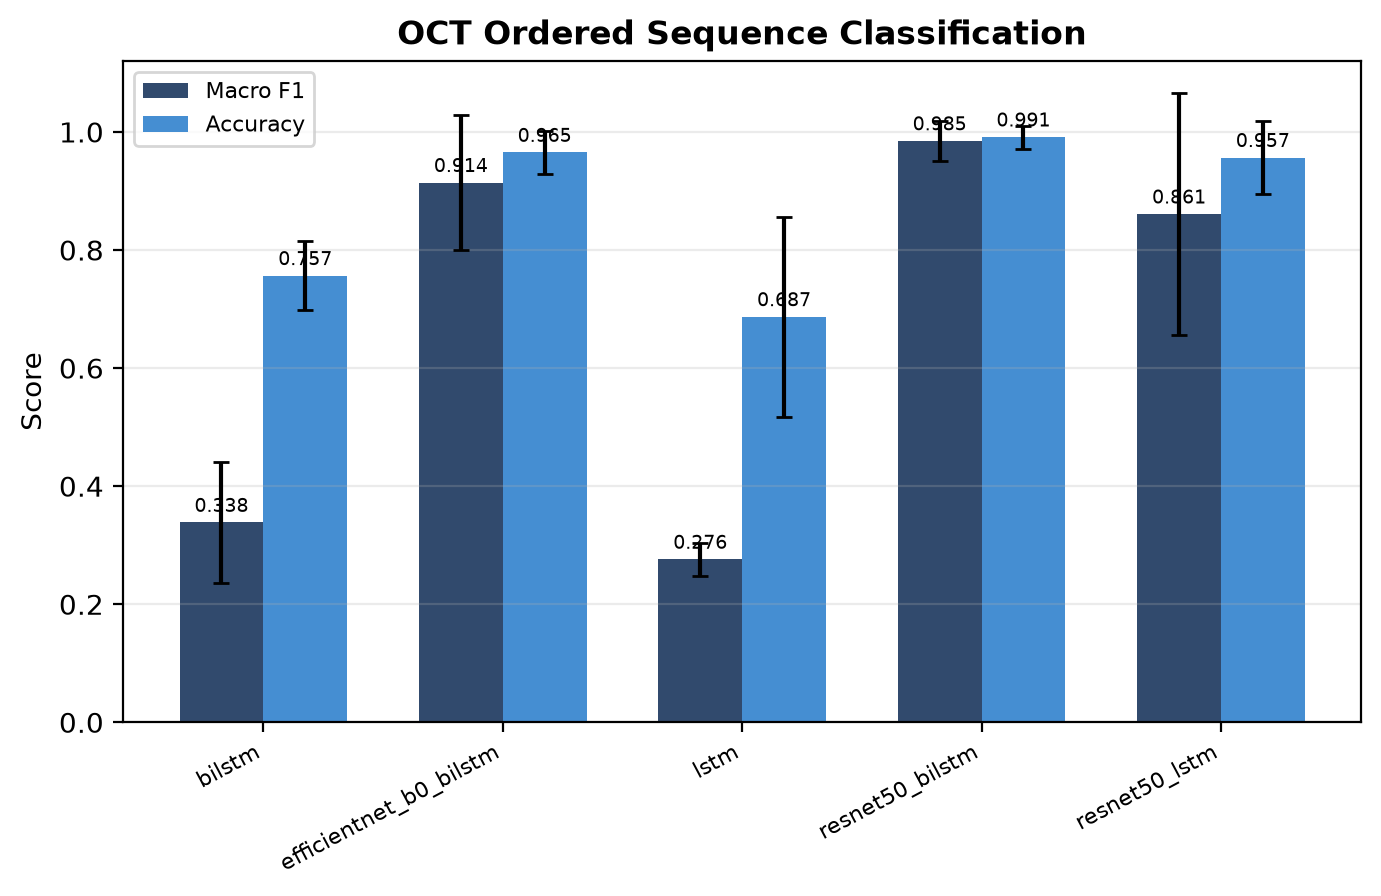

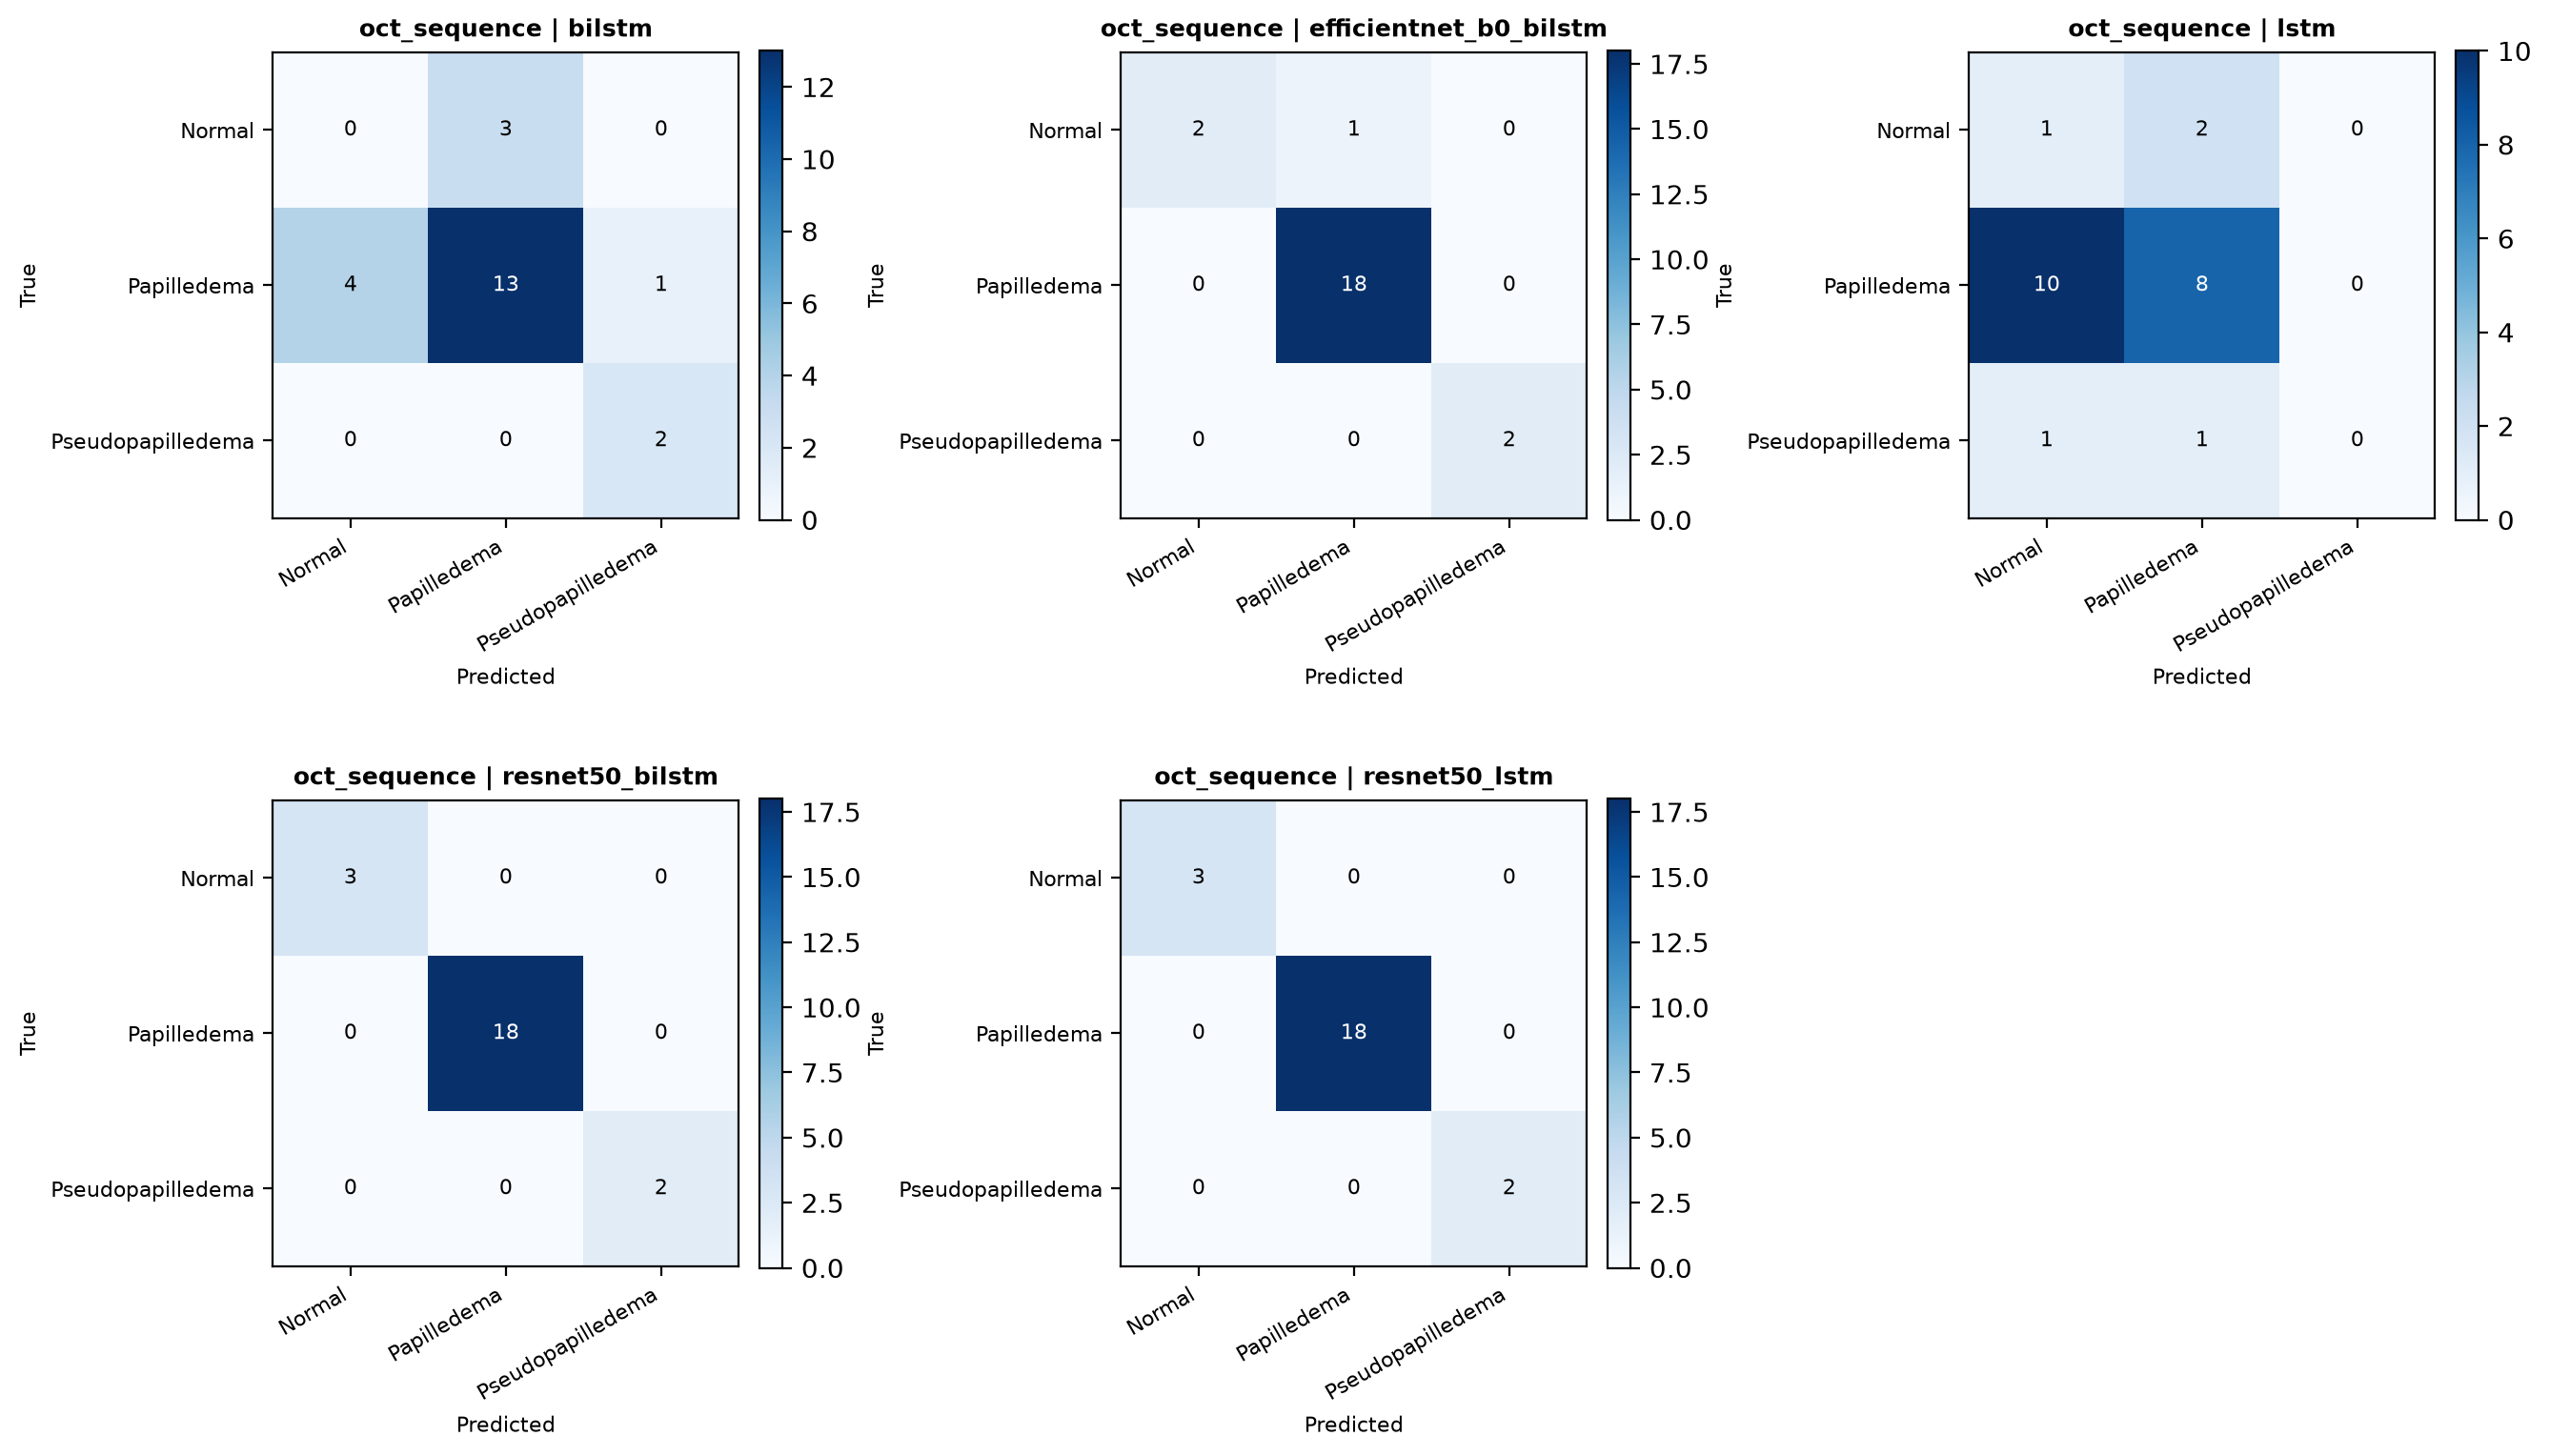

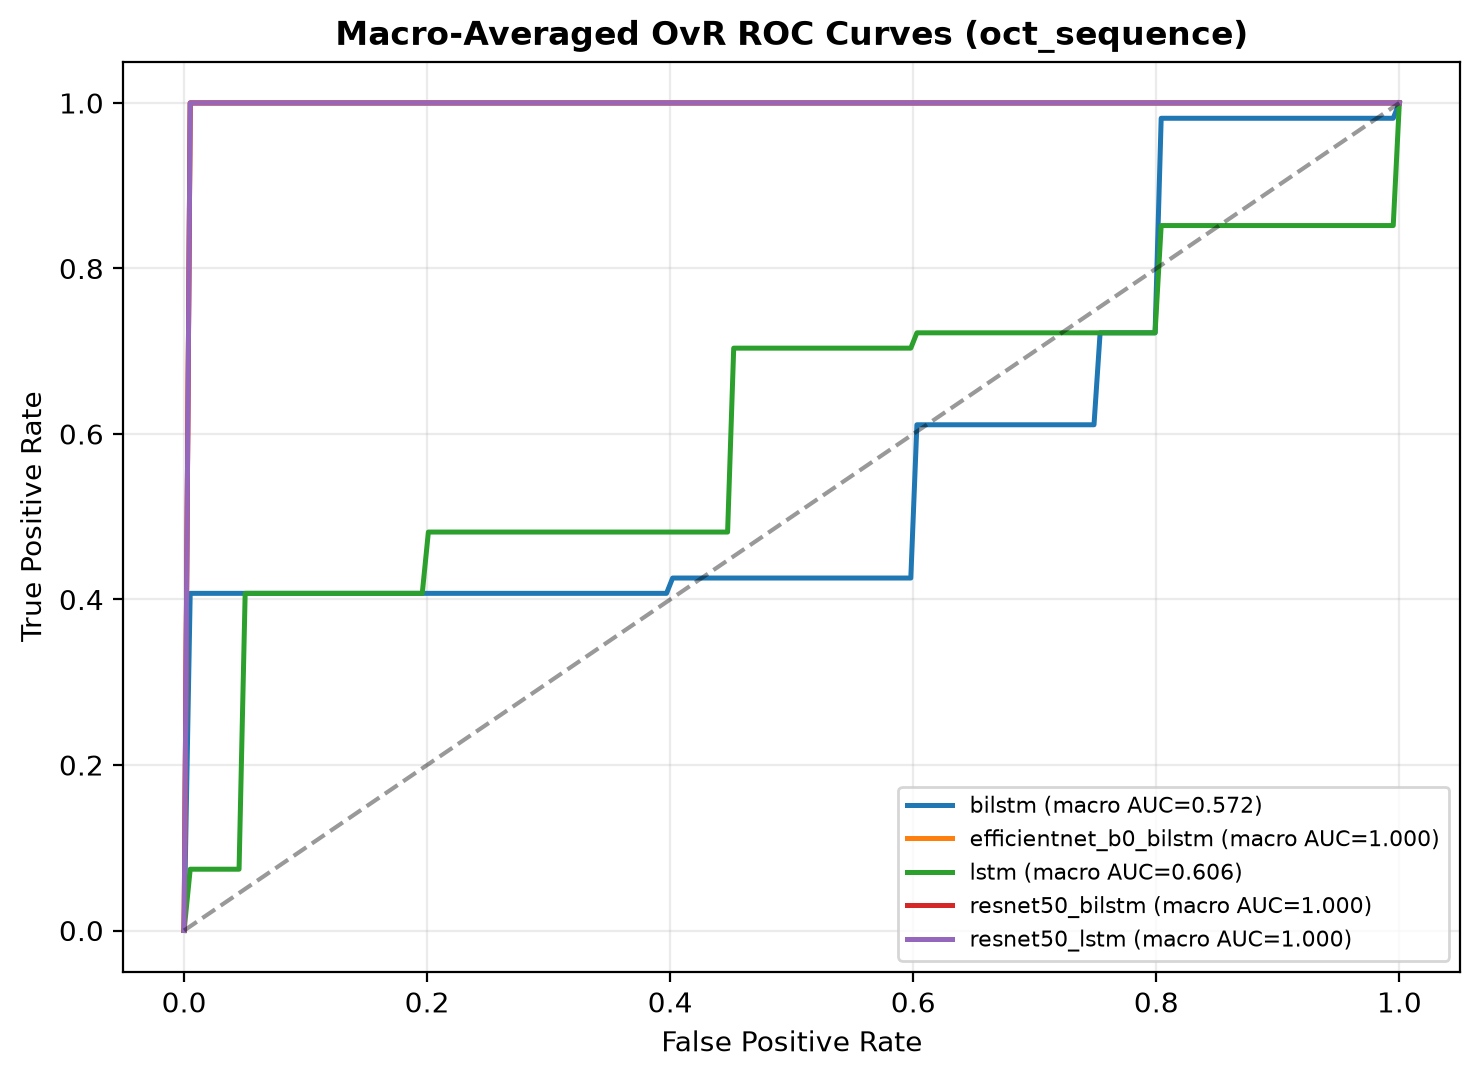

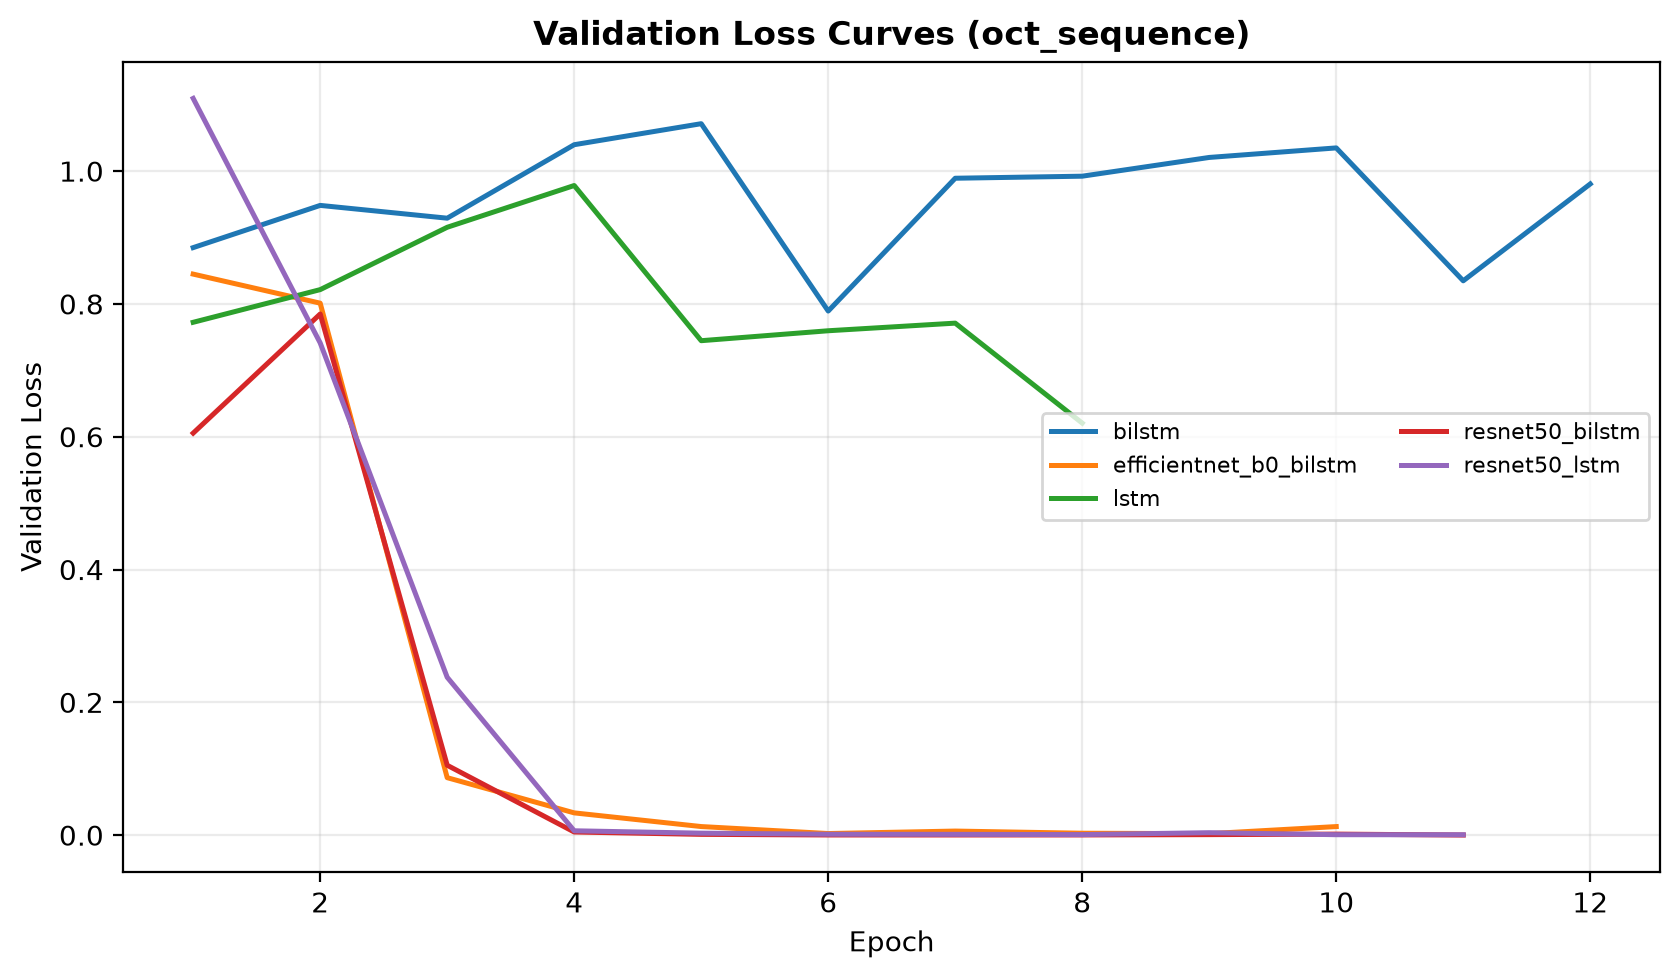

In [12]:
o_seq_tbl = pd.read_csv("results/tables/oct_sequence_comparison.csv")
o_seq_ci = ci_df[(ci_df["track"] == "oct_sequence") & (ci_df["metric"] == "macro_f1")][["model", "point_estimate", "ci95_low", "ci95_high", "n_groups"]]

print("=== OCT Ordered Sequence Ranked Comparison (5-Seed Mean & Std) ===")
print(o_seq_tbl[["model", "category", "macro_f1_mean", "macro_f1_std", "balanced_accuracy_mean", "accuracy_mean", "macro_precision_mean", "macro_recall_mean", "roc_auc_mean", "pr_auc_mean", "total_params", "inference_latency_ms"]].round(4).to_string(index=False))
print("\n=== Grouped Bootstrap 95% CIs (23 Test Windows across 4 Sequences) ===")
print(o_seq_ci.sort_values("point_estimate", ascending=False).round(4).to_string(index=False))

for fig_name in [
    "results/figures/oct_sequence_comparison.png",
    "results/figures/oct_sequence_confusion_matrices.png",
    "results/figures/oct_sequence_roc_curves.png",
    "results/figures/oct_sequence_validation_loss_curves.png",
]:
    display(IPyImage(filename=fig_name))

## 13. Track 4 Results — Original OCT Exploratory Severity Grading (G1–G4)

### **Strictly Exploratory Analysis Notice**
Grading (`G1–G4`, `895` B-scans) lacks clinical Frisén validation documentation and suffers severe class/prefix concentration (`test`: `G1=6` [1 prefix `hagerh`], `G2=146`, `G3=13`, `G4=11` [1 prefix `mostafaa`]). Accordingly, these runs explore methodological difficulty under severe label imbalance and must **not** be interpreted clinically.

### Key Observations
- **Macro F1 Remains Modest Across All Models:** `resnet50_lstm` (`Macro F1 = 0.5274 ± 0.0780`, `Accuracy = 0.7250`) and `efficientnet_b0` (`Macro F1 = 0.5042 ± 0.0941`, highest `Balanced Accuracy = 0.5387`, highest `ROC-AUC = 0.8326` & `PR-AUC = 0.6638`) lead, while `resnet50_bilstm` achieves highest accuracy (`0.7477`) via stronger G2 recall (`Macro F1 = 0.4789`).
- **Imbalance Disparity (`Accuracy` vs `Macro F1`):** Because `G2` makes up `83.0%` (`146/176`) of the test split, even weak models appear artificially strong under raw accuracy (`MLP = 0.5170 acc` vs `0.2486 macro_f1`), underscoring why `macro_f1` and `balanced_accuracy` are essential.

=== OCT Exploratory Severity Grading Ranked Comparison (5-Seed Mean & Std) ===
                 model category  macro_f1_mean  macro_f1_std  balanced_accuracy_mean  accuracy_mean  macro_precision_mean  macro_recall_mean  roc_auc_mean  pr_auc_mean  total_params  inference_latency_ms
         resnet50_lstm   hybrid         0.5274        0.0780                  0.5157         0.7250                0.6870             0.5157        0.7749       0.6542      24241604                3.8029
       efficientnet_b0      cnn         0.5042        0.0941                  0.5387         0.6875                0.5893             0.5387        0.8326       0.6638       4012096                3.2383
       resnet50_bilstm   hybrid         0.4789        0.0717                  0.4945         0.7477                0.4925             0.4945        0.7247       0.5869      24440004                4.1297
           densenet121      cnn         0.4683        0.0766                  0.4982         0.6625      

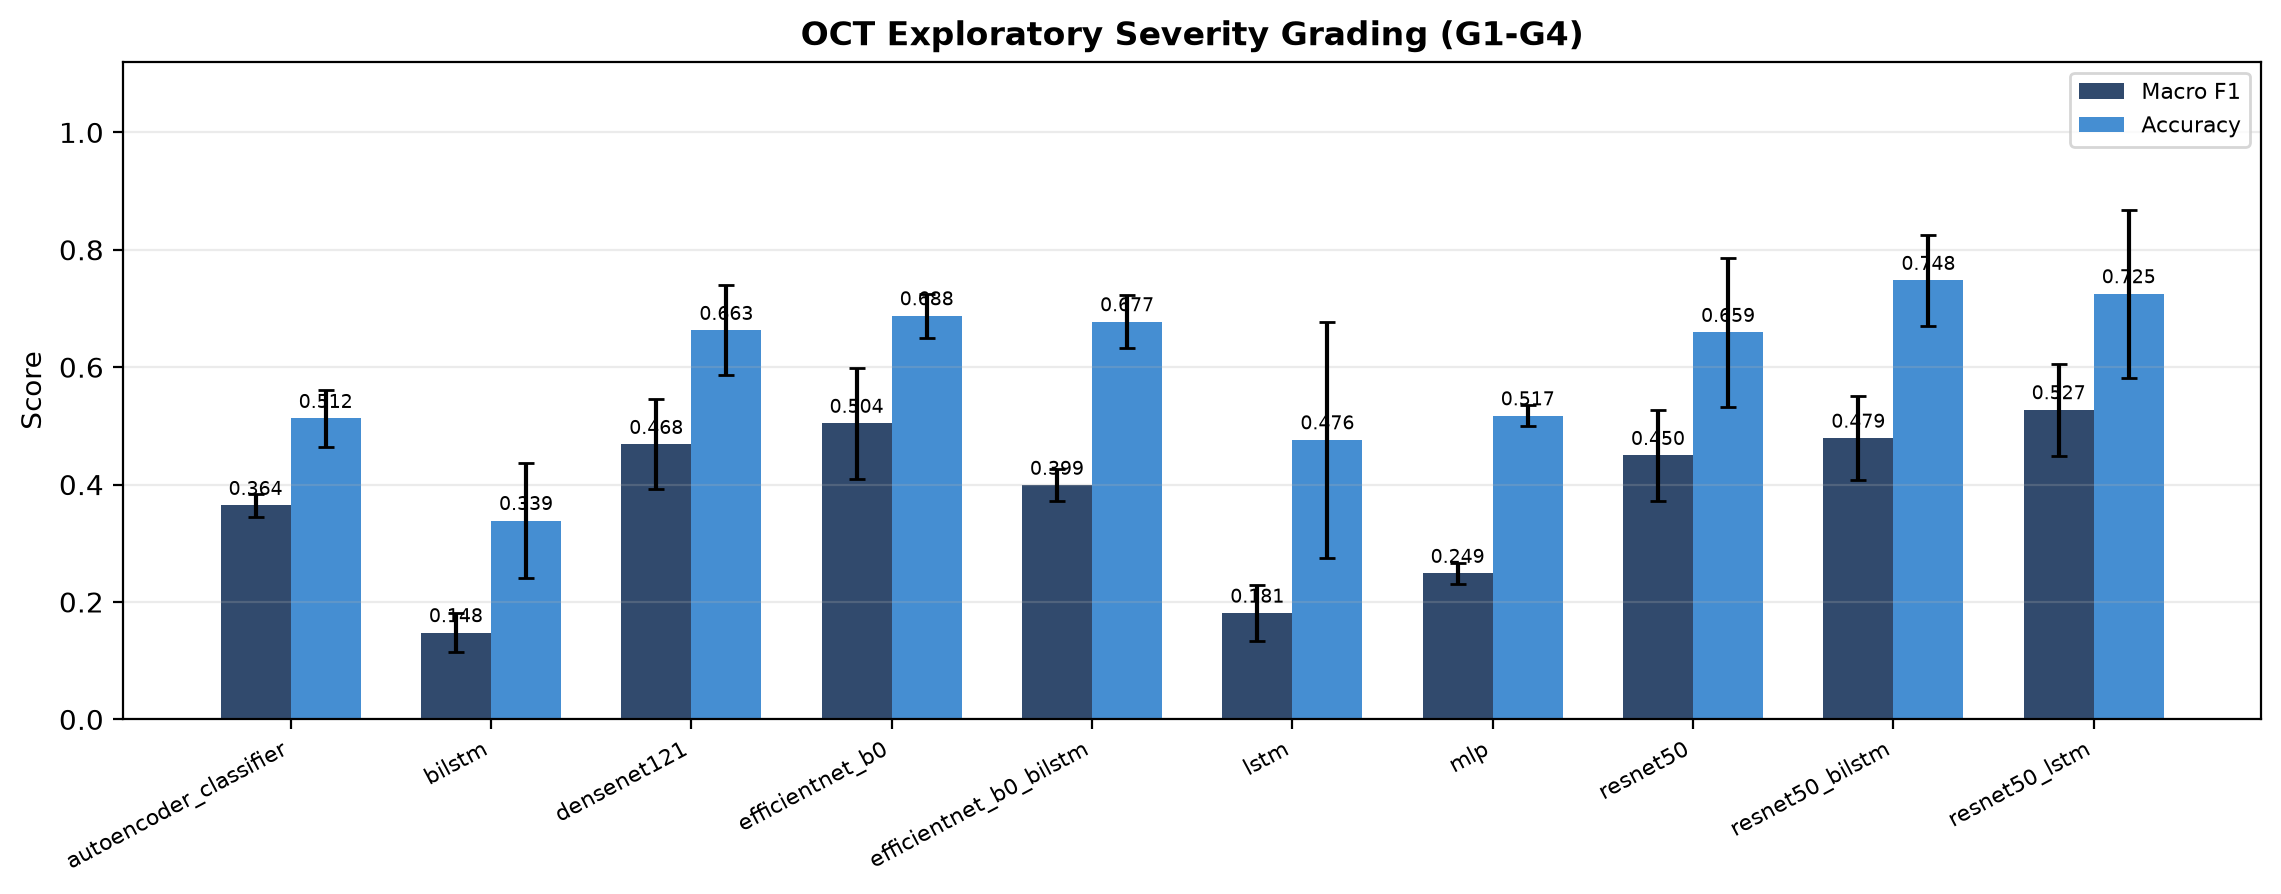

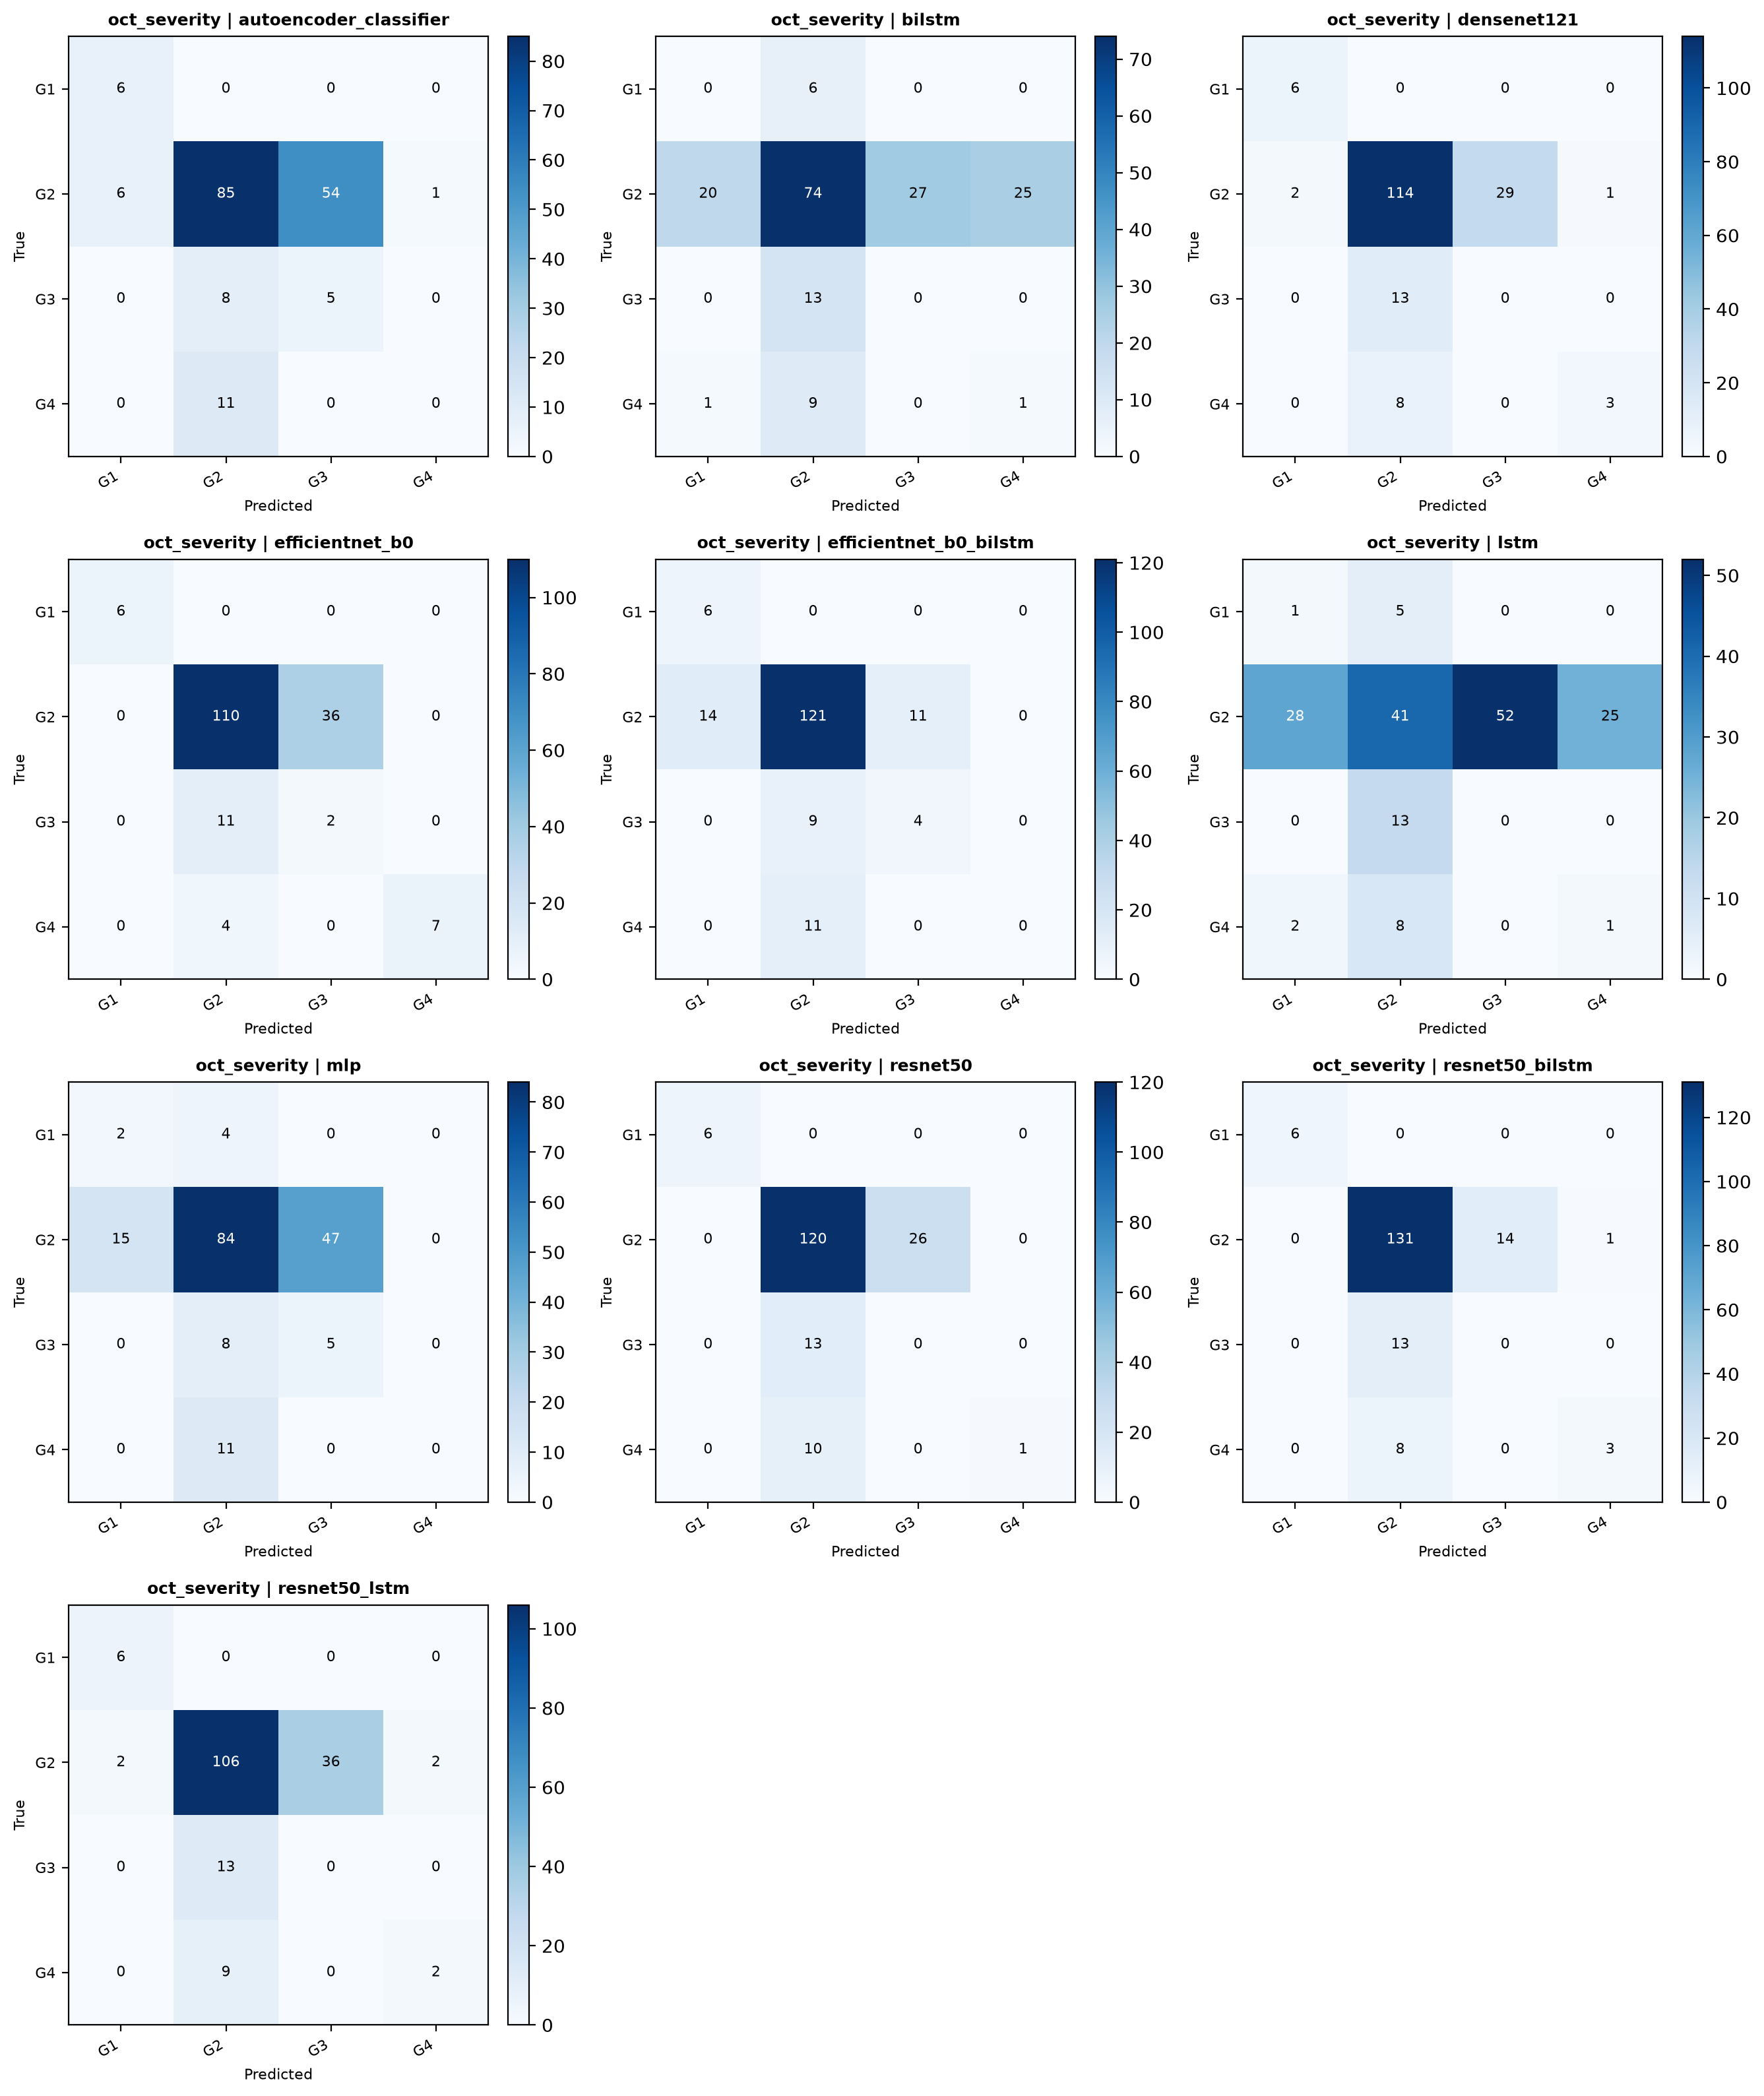

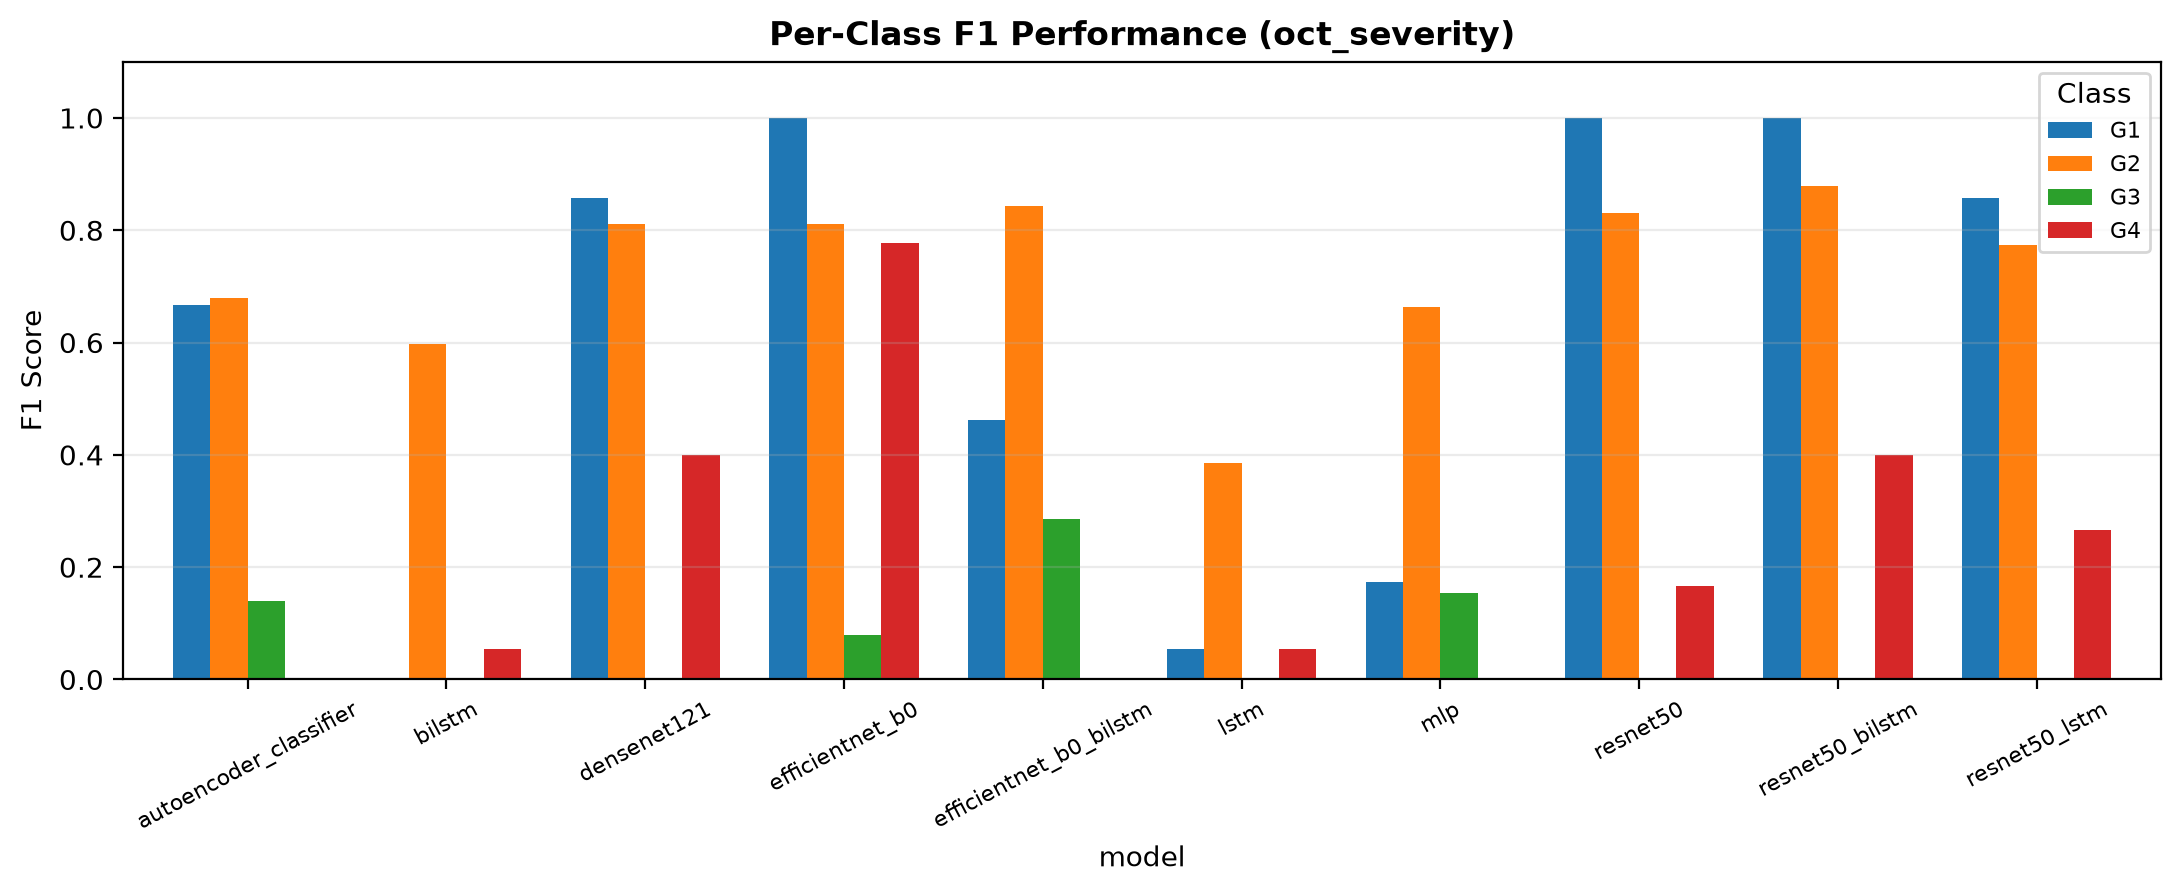

In [13]:
o_sev_tbl = pd.read_csv("results/tables/oct_severity_comparison.csv")
print("=== OCT Exploratory Severity Grading Ranked Comparison (5-Seed Mean & Std) ===")
print(o_sev_tbl[["model", "category", "macro_f1_mean", "macro_f1_std", "balanced_accuracy_mean", "accuracy_mean", "macro_precision_mean", "macro_recall_mean", "roc_auc_mean", "pr_auc_mean", "total_params", "inference_latency_ms"]].round(4).to_string(index=False))

sev_cls_rows = []
for mod_name in ["resnet50_lstm", "efficientnet_b0", "resnet50_bilstm"]:
    best_row = runs_df[(runs_df["track"] == "oct_severity") & (runs_df["model"] == mod_name)].sort_values("macro_f1", ascending=False).iloc[0]
    p_df = pd.read_csv(f"results/predictions/{best_row['exp_id']}_predictions.csv")
    for cls in ["G1", "G2", "G3", "G4"]:
        sub = p_df[p_df["true_label"] == cls]
        sev_cls_rows.append({
            "model (best seed)": f"{mod_name} (s{best_row['seed']})",
            "class": cls,
            "test_support": len(sub),
            "class_recall": round(float(sub["correct"].mean()), 4),
        })
print("\n=== Per-Class Test Recall Profile (Best Seed per Top-3 Severity Model) ===")
print(pd.DataFrame(sev_cls_rows).pivot(index="class", columns="model (best seed)", values="class_recall").to_string())

for fig_name in [
    "results/figures/severity_comparison.png",
    "results/figures/oct_severity_confusion_matrices.png",
    "results/figures/oct_severity_per_class_performance.png",
]:
    display(IPyImage(filename=fig_name))

## 14. Within-Track Cross-Architecture Family & Efficiency Comparison

Compares architectural families (`CNN`, `Hybrid CNN-RNN`, `Standalone RNN`, `Baselines`) **strictly within each track** (never aggregating scores across Fundus and OCT) alongside parameter count, total training duration, and per-sample GPU inference latency (`ms`).

=== Within-Track Architecture Family Summary ===
         track category  models  runs  macro_f1_mean  macro_f1_std  balanced_acc_mean  accuracy_mean  roc_auc_mean  pr_auc_mean  mean_latency_ms
 fundus_3class      cnn       3    15         0.9803        0.0051             0.9792         0.9854        0.9987       0.9973           2.9659
 fundus_3class   hybrid       3    15         0.9756        0.0100             0.9755         0.9818        0.9968       0.9936           2.8930
 fundus_3class baseline       2    10         0.8354        0.0380             0.8358         0.8678        0.9565       0.9044           1.8715
 fundus_3class      rnn       2    10         0.7376        0.0366             0.7592         0.7649        0.8957       0.7674           2.5294
oct_individual      cnn       3    15         0.9871        0.0179             0.9822         0.9942        0.9999       0.9995           3.6561
oct_individual   hybrid       3    15         0.9802        0.0195             0.

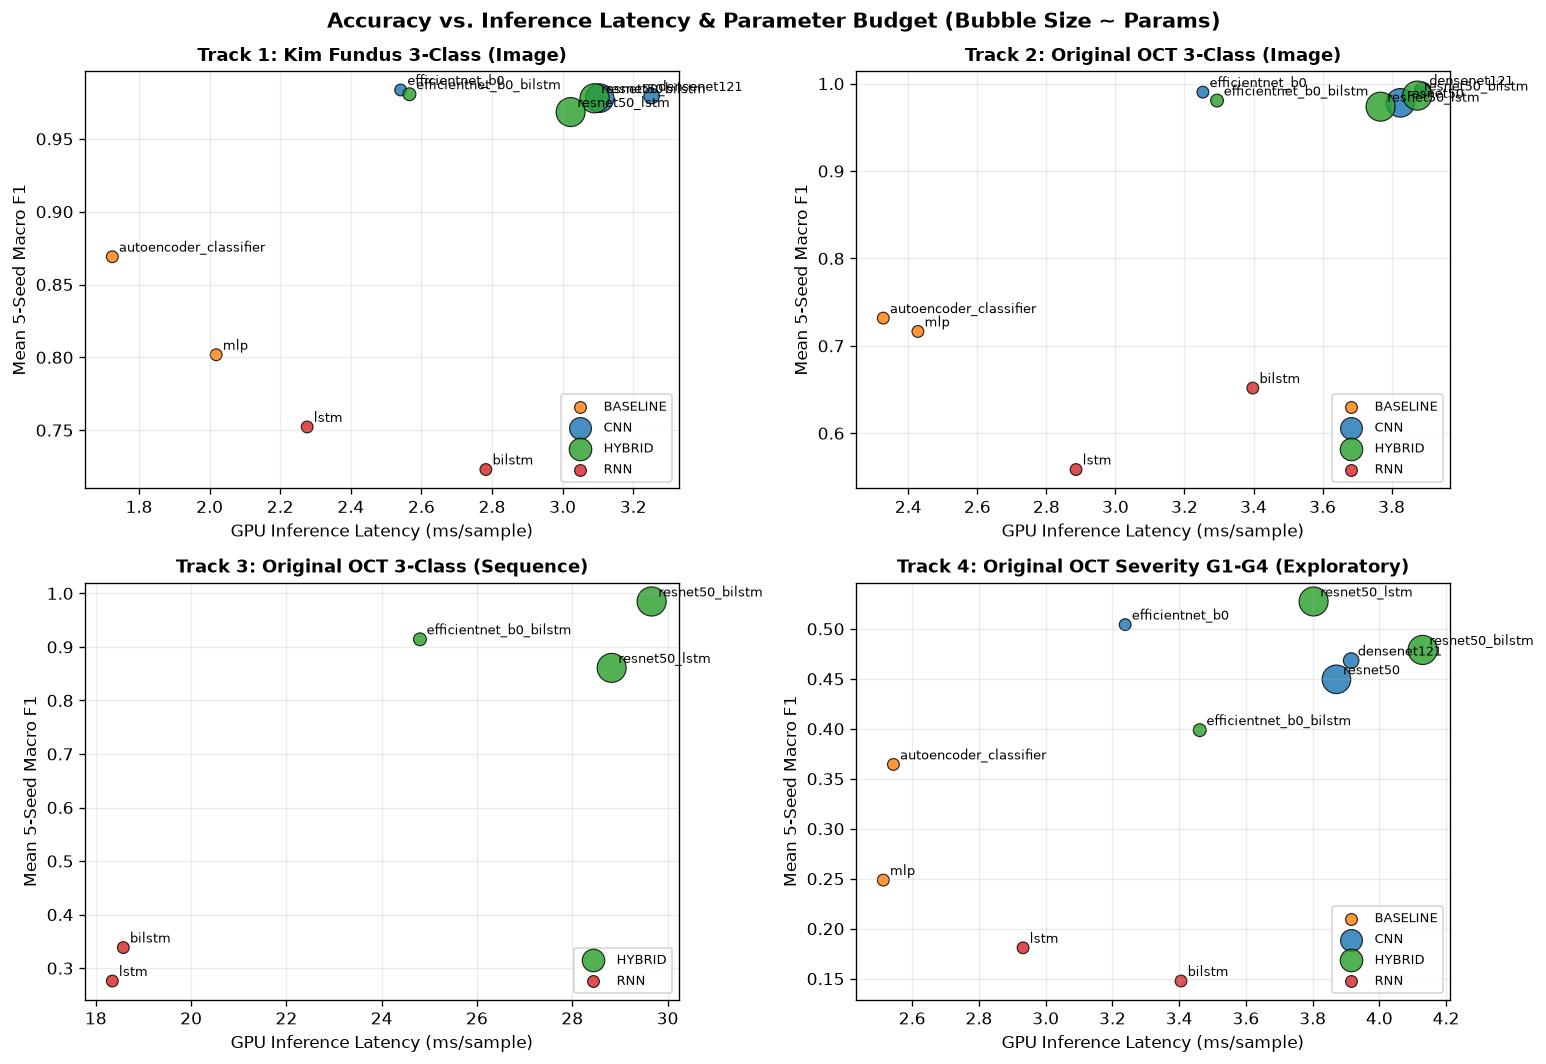

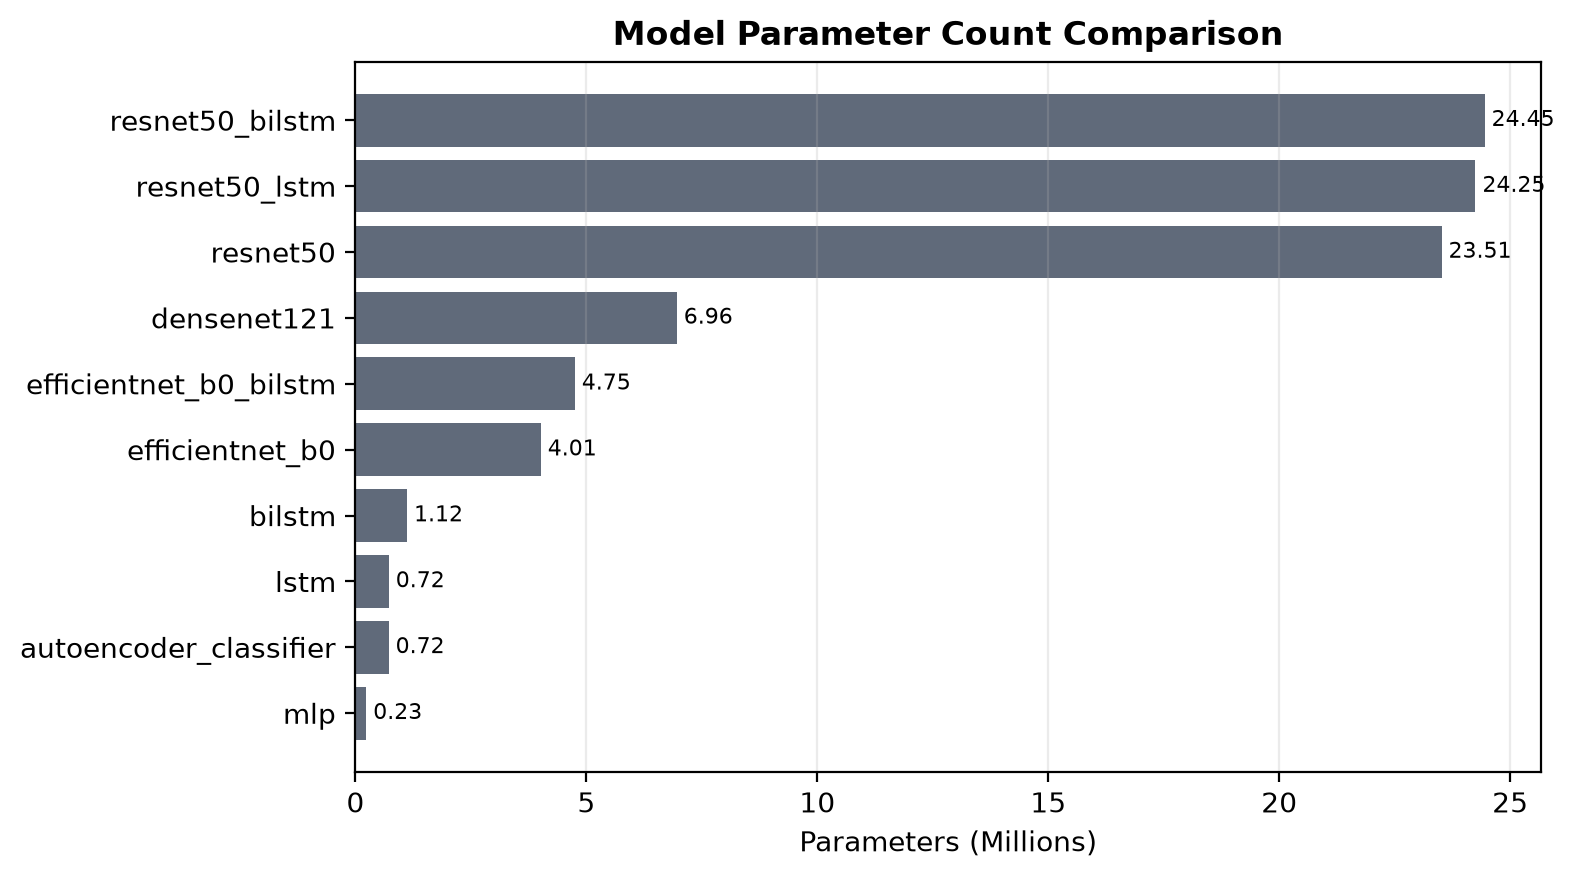

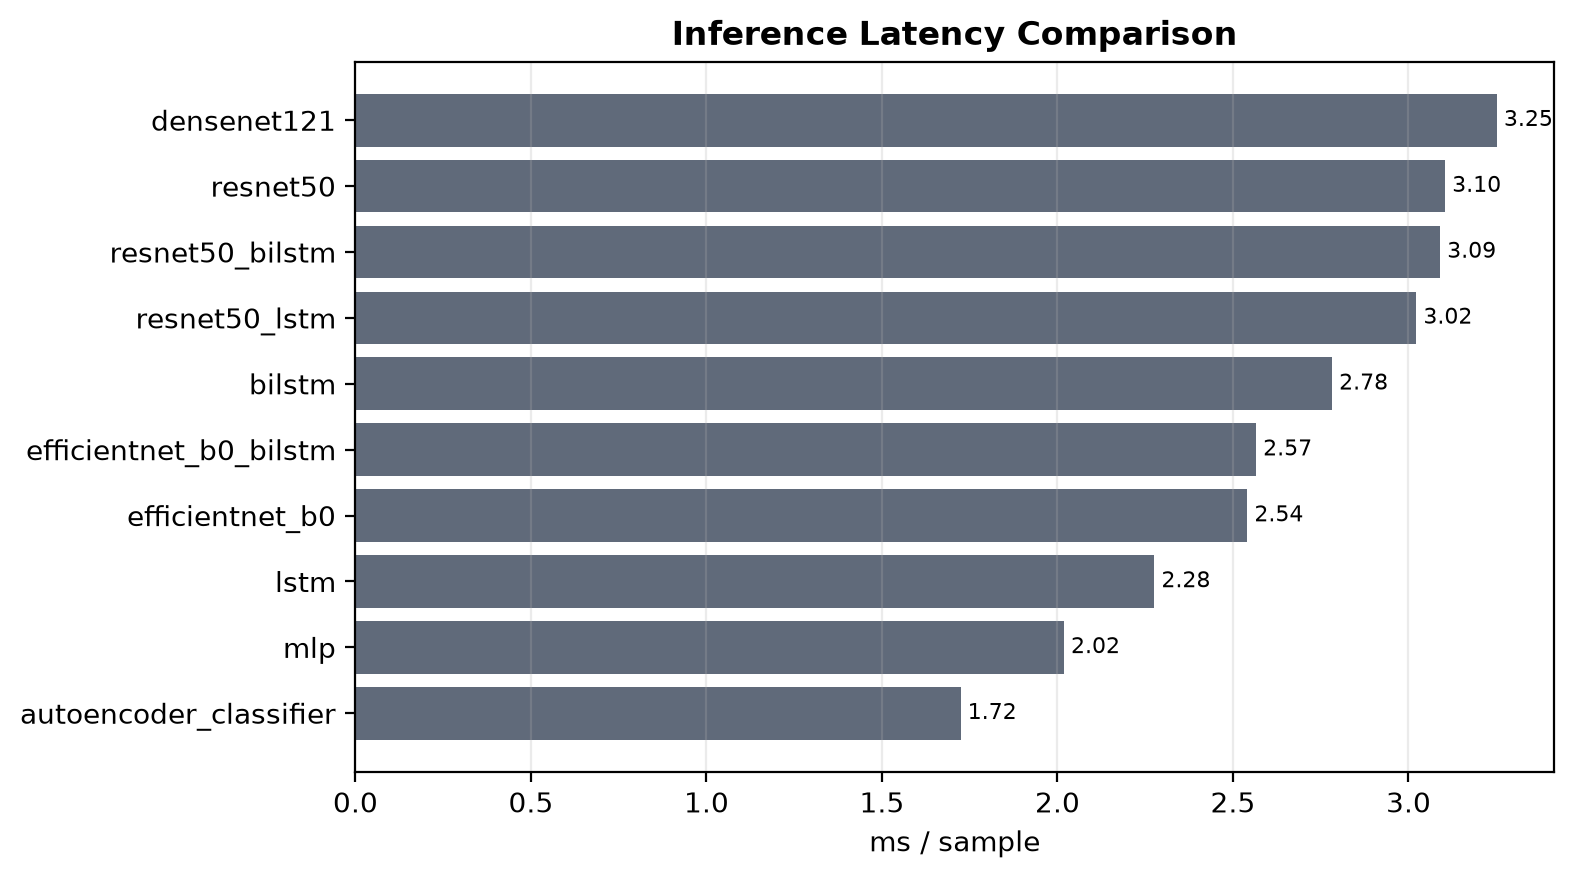

In [14]:
fam_tbl = (
    runs_df.groupby(["track", "category"])
    .agg(
        models=("model", "nunique"),
        runs=("exp_id", "count"),
        macro_f1_mean=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std"),
        balanced_acc_mean=("balanced_accuracy", "mean"),
        accuracy_mean=("accuracy", "mean"),
        roc_auc_mean=("roc_auc_ovr", "mean"),
        pr_auc_mean=("pr_auc_ovr", "mean"),
        mean_latency_ms=("inference_latency_ms", "mean"),
    )
    .round(4)
    .reset_index()
    .sort_values(["track", "macro_f1_mean"], ascending=[True, False])
)
print("=== Within-Track Architecture Family Summary ===")
print(fam_tbl.to_string(index=False))

comp_tbl = pd.read_csv("results/tables/computational_comparison.csv")
print("\n=== Computational Cost (Selected Fundus & Sequence Rows) ===")
print(comp_tbl[comp_tbl["track"].isin(["fundus_3class", "oct_sequence"])].round(3).to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
cat_colors = {"cnn": "#1f77b4", "hybrid": "#2ca02c", "rnn": "#d62728", "baseline": "#ff7f0e"}
track_titles = {
    "fundus_3class": "Track 1: Kim Fundus 3-Class (Image)",
    "oct_individual": "Track 2: Original OCT 3-Class (Image)",
    "oct_sequence": "Track 3: Original OCT 3-Class (Sequence)",
    "oct_severity": "Track 4: Original OCT Severity G1-G4 (Exploratory)",
}
for ax, (tr_key, tr_title) in zip(axes.flat, track_titles.items()):
    sub = (
        runs_df[runs_df["track"] == tr_key]
        .groupby(["model", "category"])
        .agg(f1=("macro_f1", "mean"), lat=("inference_latency_ms", "mean"), params=("total_params", "first"))
        .reset_index()
    )
    for cat, g in sub.groupby("category"):
        ax.scatter(g["lat"], g["f1"], s=np.clip(g["params"] / 80000, 50, 400), color=cat_colors[cat], alpha=0.82, label=cat.upper(), edgecolors="black", linewidths=0.7)
    for _, r in sub.iterrows():
        ax.annotate(r["model"], (r["lat"], r["f1"]), xytext=(4, 3), textcoords="offset points", fontsize=7.5)
    ax.set_title(tr_title, fontsize=10.5, fontweight="bold")
    ax.set_xlabel("GPU Inference Latency (ms/sample)")
    ax.set_ylabel("Mean 5-Seed Macro F1")
    ax.grid(True, alpha=0.25)
    ax.legend(fontsize=8, loc="lower right")

plt.suptitle("Accuracy vs. Inference Latency & Parameter Budget (Bubble Size ~ Params)", fontsize=12.5, fontweight="bold")
plt.tight_layout()
plt.show()

display(IPyImage(filename="results/figures/parameter_comparison.png"))
display(IPyImage(filename="results/figures/inference_time_comparison.png"))

## 15. Statistical Analysis & Hypothesis Testing

Audits **149 track-level global and sample-level hypothesis tests** plus **290 seed-level paired comparisons** (`results/statistical_analysis/`).

### Direct Answers to Key Research Questions (Strictly Grounded in Observed Statistics)
1. **Do architectures differ significantly within each track (Friedman Test across 5 matched seeds)?**
   - **Yes across all 4 tracks:** `fundus_3class` ($\chi^2 = 38.25, p = 1.57\times 10^{-5}$, Kendall's $W = 0.850$); `oct_individual` ($\chi^2 = 36.10, p = 3.81\times 10^{-5}$, $W = 0.802$); `oct_sequence` ($\chi^2 = 16.64, p = 0.00227$, $W = 0.832$); `oct_severity` ($\chi^2 = 36.88, p = 2.76\times 10^{-5}$, $W = 0.820$).
2. **Do Hybrid CNN–RNN models outperform standalone CNNs on image tasks?**
   - **No:** On `fundus_3class`, `efficientnet_b0` vs `efficientnet_b0_bilstm` (`0.9835` vs `0.9806`) yields Holm $p = 1.0$ (paired t-test & McNemar) and tiny effect $d = 0.29$; `resnet50` vs `resnet50_bilstm` (`0.9779` vs `0.9779`) yields Holm $p = 1.0, d = 0.01$. Same holds on `oct_individual` (Holm $p = 1.0$ among top CNNs and hybrids).
3. **Do CNN & Hybrid models significantly beat standalone RNNs and MLPs on Fundus & OCT?**
   - **Yes (substantial effect sizes):** On `fundus_3class`, `efficientnet_b0` beats `lstm` ($+0.2314$ Macro F1, $d=17.07$, seed t-test Holm $p=0.00012$, McNemar Holm $p<10^{-5}$), `bilstm` ($+0.2606$, $p=0.0071$, McNemar $p<10^{-6}$), and `mlp` ($+0.1818$, $p=0.0015$, McNemar $p=3\times 10^{-6}$). On `oct_sequence`, `resnet50_bilstm` beats `lstm` ($+0.7089$ Macro F1, McNemar exact Holm $p=0.0012$).
4. **Why are zero Wilcoxon signed-rank tests significant (`0/145`)?**
   - Exact statistical mathematics: with $n = 5$ matched random seeds, the **smallest achievable two-sided Wilcoxon p-value** is $2 / 2^5 = 0.0625 > \alpha = 0.05$ even before Holm–Bonferroni correction. Therefore Wilcoxon is strictly underpowered at $n=5$ and cannot claim $p < 0.05$.
5. **What critical statistical caveat applies to seed tests and OCT McNemar tests?**
   - Multi-seed tests measure **training stochasticity on a fixed train/val/test split**, NOT independent patient cohorts. Furthermore, OCT McNemar tests evaluate **183 slices (or 23 windows) drawn from only 4 test sequences** (`oct_severity`: `176` slices from `5` clusters), violating i.i.d. error assumptions and making p-values **anti-conservative** (flagged on every OCT row).

=== Global Friedman Tests Across All 4 Tracks ===
         track         sample_size  statistic  p_value effect_size_name  effect_size  significant
 fundus_3class 5 seeds x 10 models  38.252734 0.000016       kendalls_w     0.850061         True
oct_individual 5 seeds x 10 models  36.099631 0.000038       kendalls_w     0.802214         True
  oct_sequence  5 seeds x 5 models  16.638298 0.002272       kendalls_w     0.831915         True
  oct_severity 5 seeds x 10 models  36.883636 0.000028       kendalls_w     0.819636         True

=== Key Pairwise Comparisons (Fundus & OCT Sequence Focus) ===
        track                           models_compared                           test_used                 sample_size  p_value  p_adjusted effect_size_name  effect_size  significant
fundus_3class                 bilstm vs efficientnet_b0               Paired t-test (seeds)             5 matched seeds 0.000286    0.007119         cohens_d    -5.318208         True
fundus_3class               

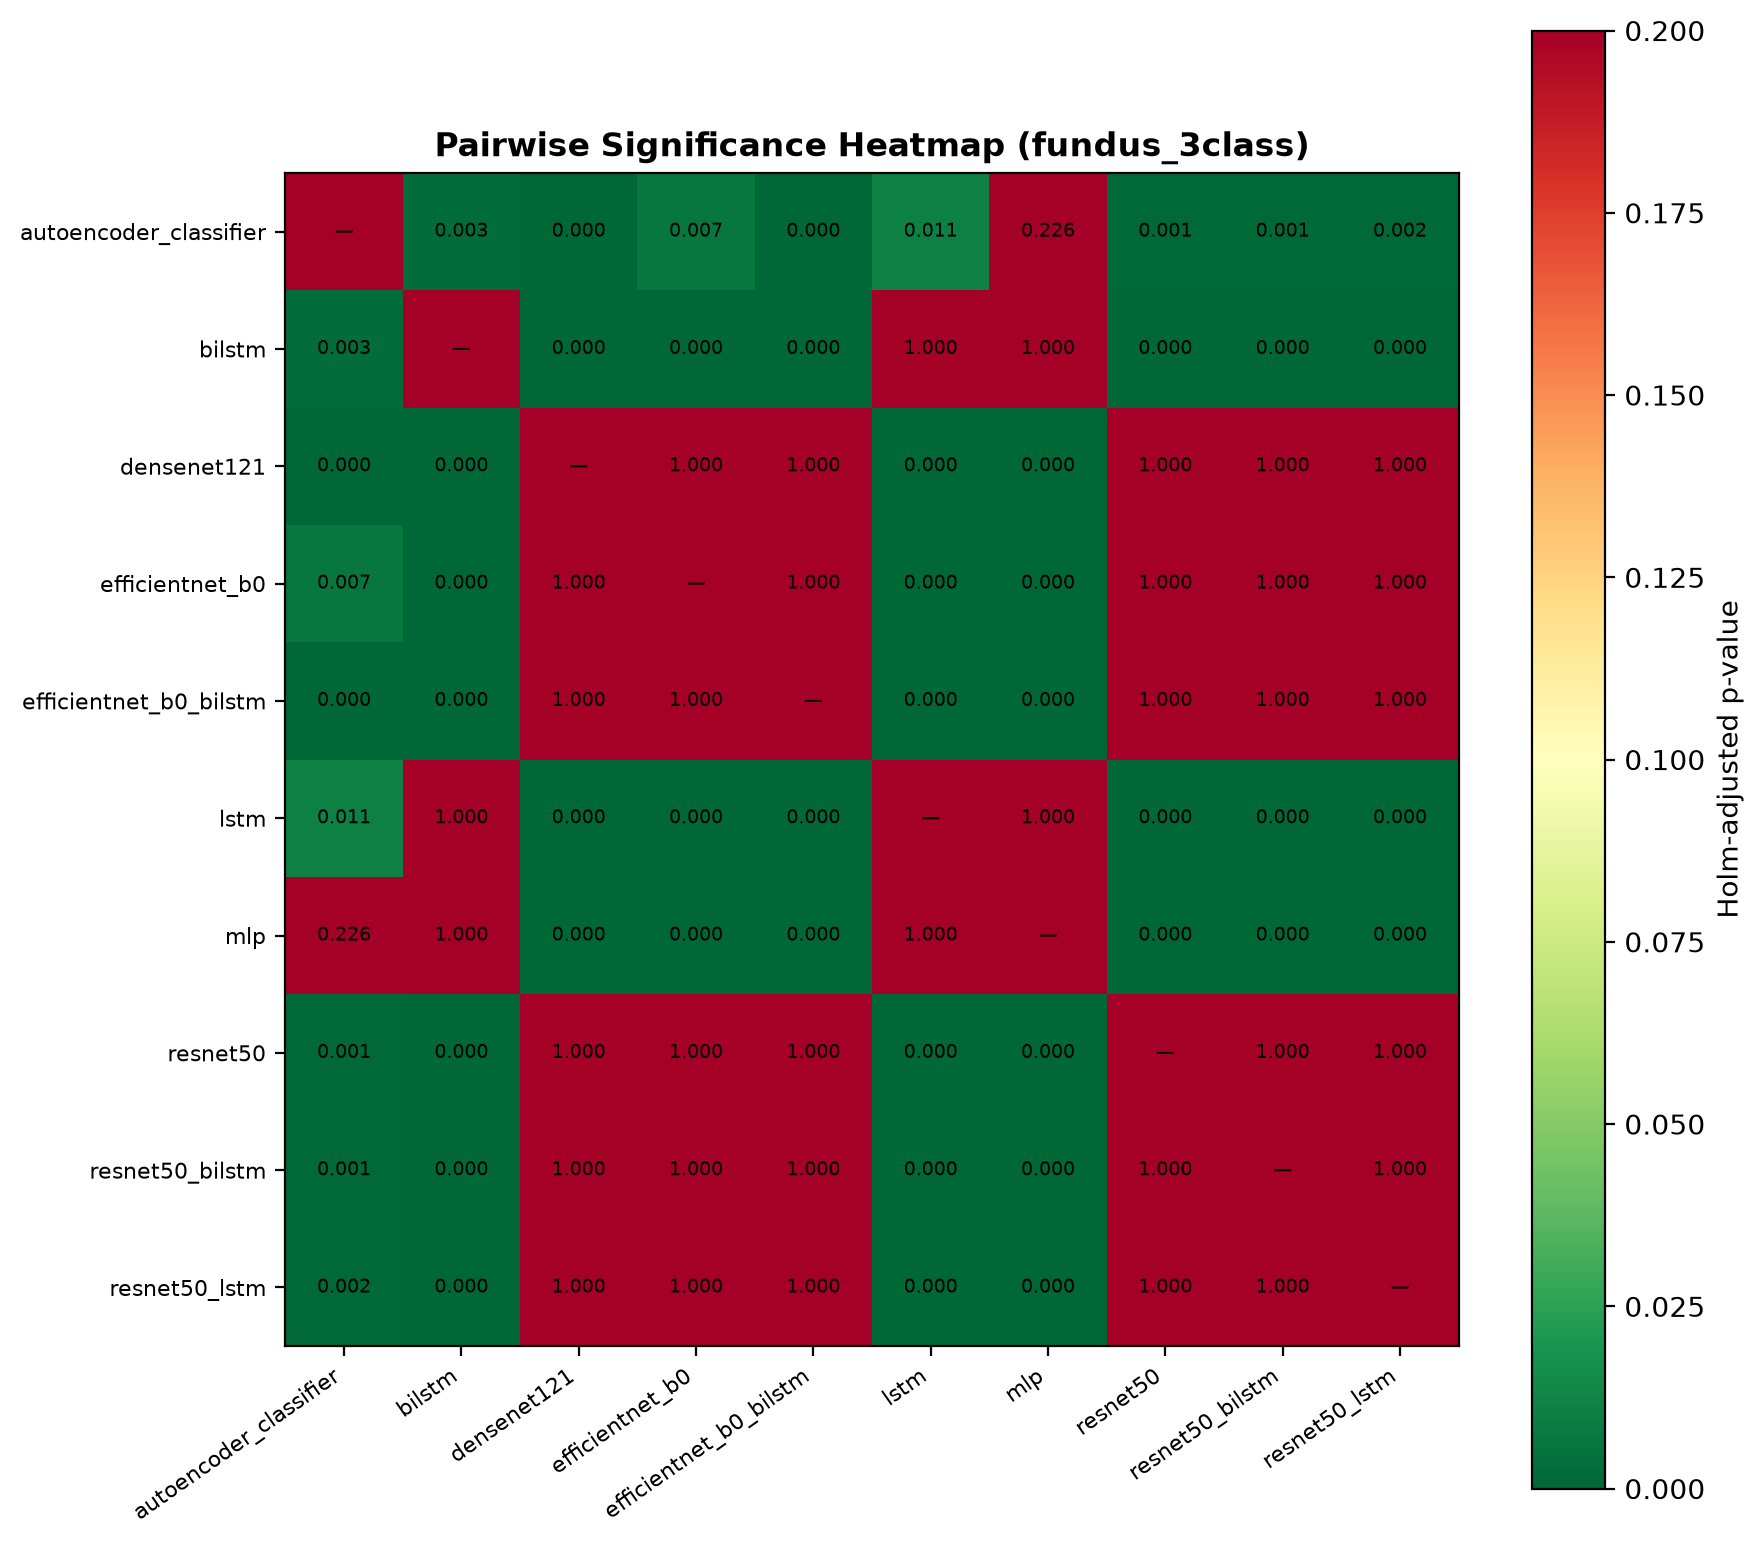

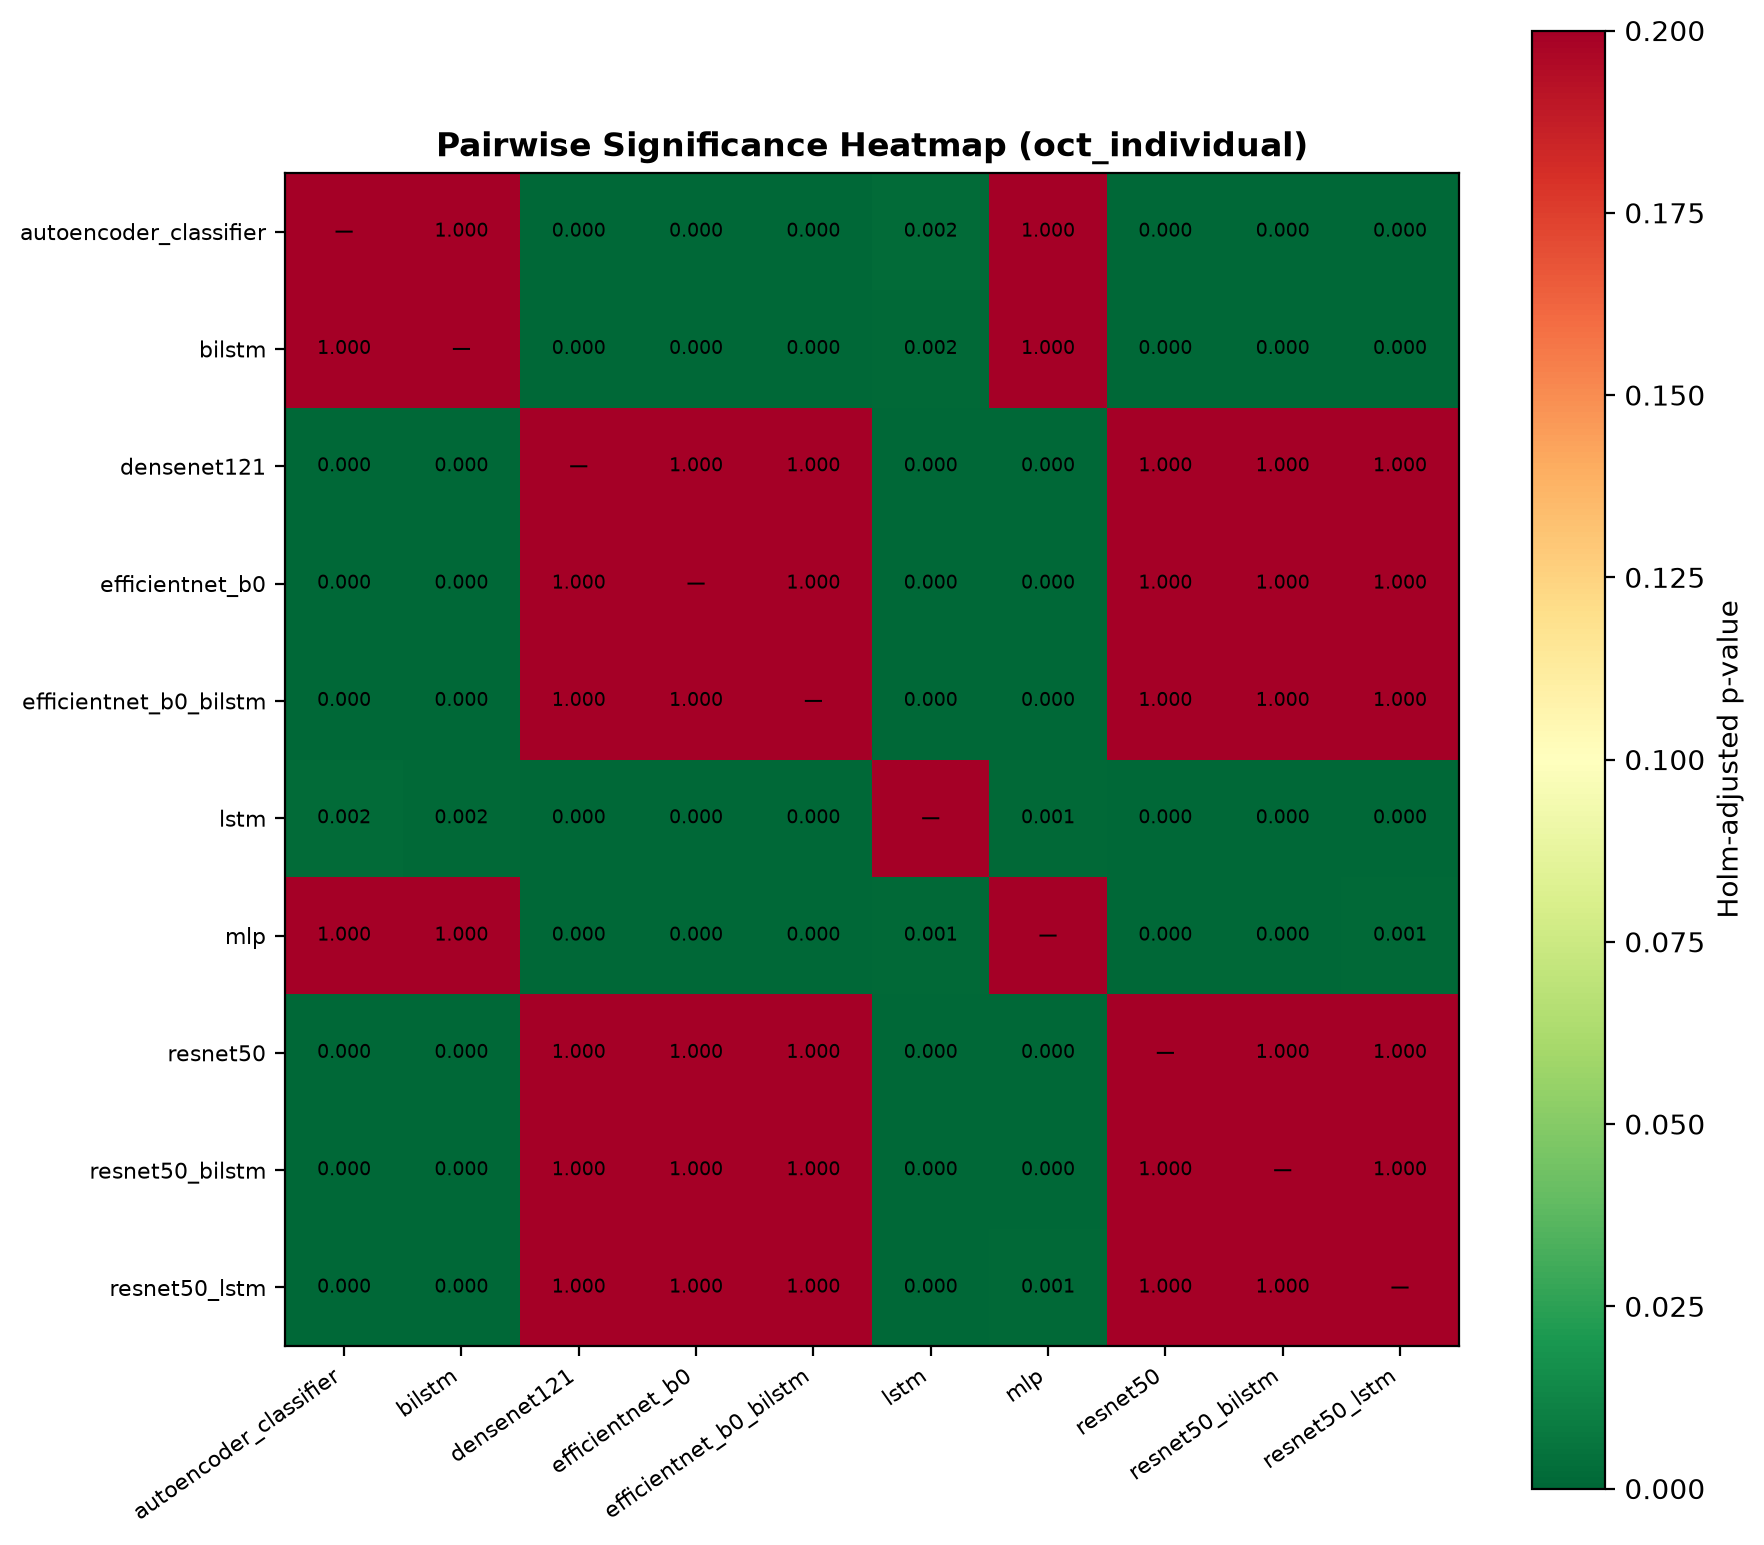

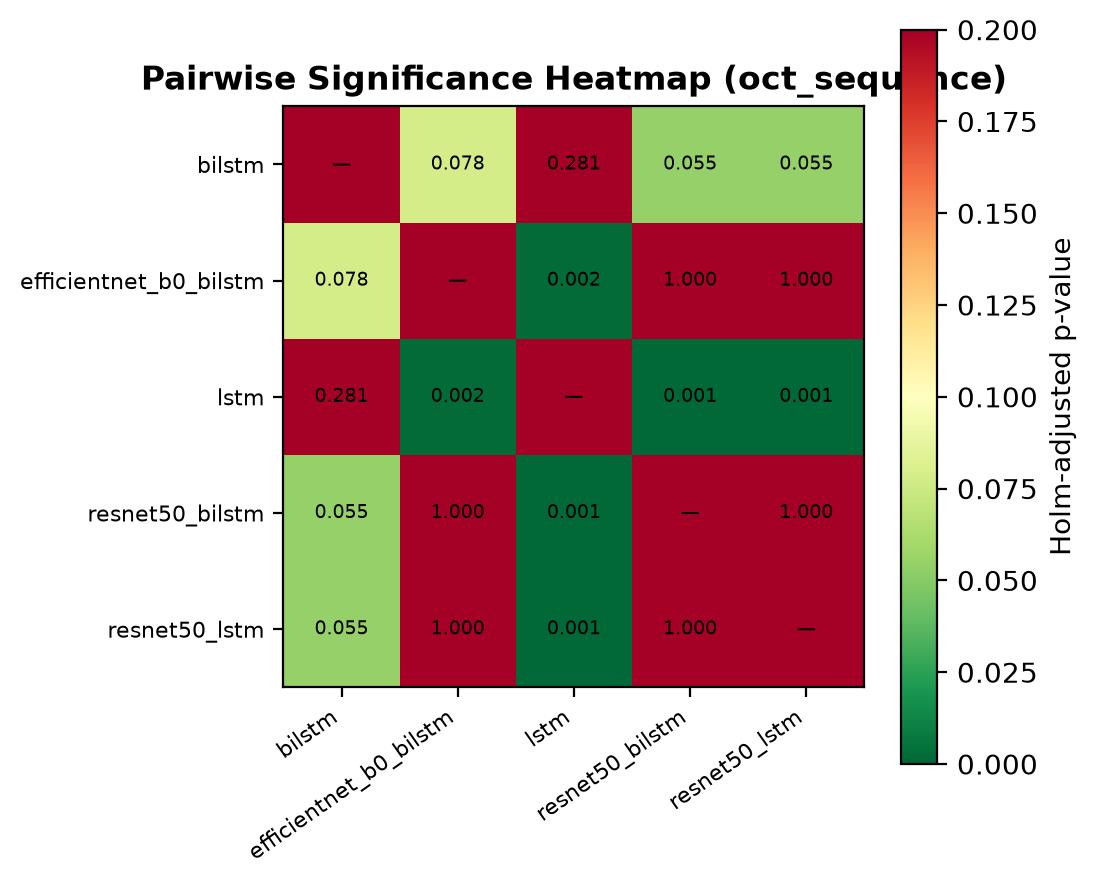

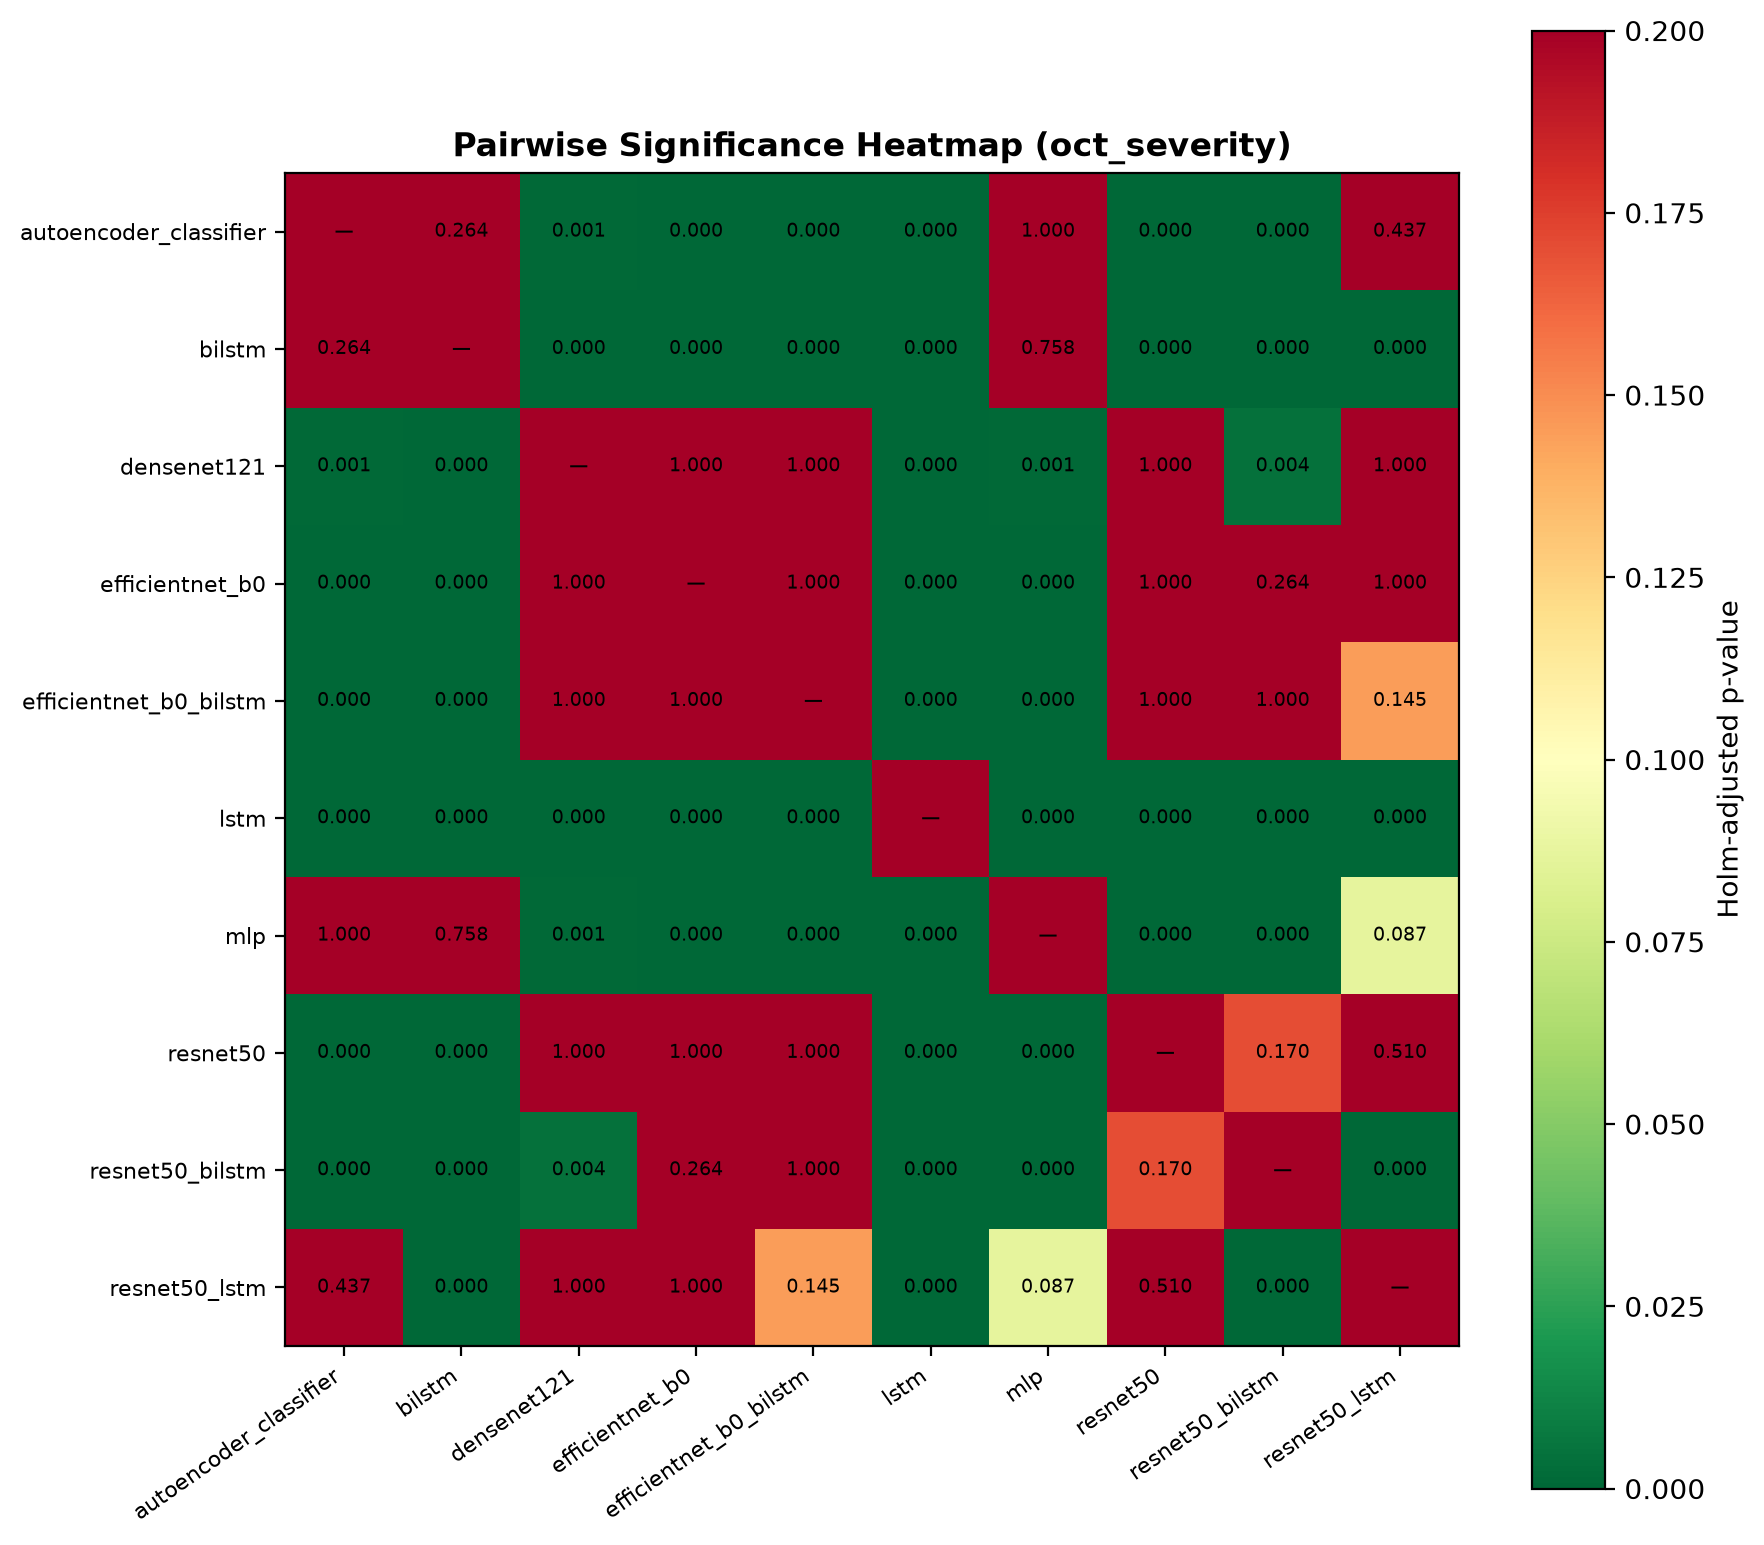

In [15]:
ht_df = pd.read_csv("results/statistical_analysis/hypothesis_tests.csv")
pw_df = pd.read_csv("results/statistical_analysis/pairwise_comparisons.csv")

print("=== Global Friedman Tests Across All 4 Tracks ===")
fried = ht_df[ht_df["test_used"] == "Friedman test"][["track", "sample_size", "statistic", "p_value", "effect_size_name", "effect_size", "significant"]]
print(fried.round(6).to_string(index=False))

print("\n=== Key Pairwise Comparisons (Fundus & OCT Sequence Focus) ===")
key_pair_sets = [
    ("fundus_3class", frozenset({"efficientnet_b0", "efficientnet_b0_bilstm"})),
    ("fundus_3class", frozenset({"resnet50", "resnet50_bilstm"})),
    ("fundus_3class", frozenset({"densenet121", "efficientnet_b0"})),
    ("fundus_3class", frozenset({"efficientnet_b0", "lstm"})),
    ("fundus_3class", frozenset({"efficientnet_b0", "bilstm"})),
    ("fundus_3class", frozenset({"efficientnet_b0", "mlp"})),
    ("oct_sequence", frozenset({"resnet50_bilstm", "bilstm"})),
    ("oct_sequence", frozenset({"resnet50_bilstm", "lstm"})),
    ("oct_sequence", frozenset({"efficientnet_b0_bilstm", "resnet50_bilstm"})),
]
mask = pw_df.apply(lambda r: (r["track"], frozenset(r["models_compared"].split(" vs "))) in key_pair_sets, axis=1)
sel = pw_df[mask][["track", "models_compared", "test_used", "sample_size", "p_value", "p_adjusted", "effect_size_name", "effect_size", "significant"]]
print(sel.round(6).to_string(index=False))

print("\n=== Significant Hypothesis Tests by Track & Method (Holm alpha=0.05) ===")
print(pw_df.groupby(["track", "test_used"])["significant"].agg(total="count", significant="sum").to_string())

for fig_name in [
    "results/figures/fundus_3class_statistical_significance_heatmap.png",
    "results/figures/oct_individual_statistical_significance_heatmap.png",
    "results/figures/oct_sequence_statistical_significance_heatmap.png",
    "results/figures/oct_severity_statistical_significance_heatmap.png",
]:
    display(IPyImage(filename=fig_name))

## 16. Representative Error Analysis & Failure Case Inspection

Aggregates test errors across all completed non-smoke runs (`results/predictions/*_errors.csv`), quantifies dominant confusion pairs within each track, and visualizes actual misclassified clinical test samples with ground-truth vs. predicted probabilities.

=== 5-Seed Pooled Misclassification Summary ===
         track                  model  sum_errors_5seeds  high_conf_errors_5seeds                                                                                dominant_confusions
 fundus_3class        efficientnet_b0                 12                       10                                      Pseudopapilledema->Papilledema:8, Pseudopapilledema->Normal:4
 fundus_3class efficientnet_b0_bilstm                 15                        8         Pseudopapilledema->Papilledema:7, Normal->Pseudopapilledema:5, Pseudopapilledema->Normal:2
 fundus_3class autoencoder_classifier                109                       49      Pseudopapilledema->Normal:36, Normal->Pseudopapilledema:18, Papilledema->Pseudopapilledema:18
 fundus_3class                    mlp                162                       32 Papilledema->Pseudopapilledema:42, Normal->Pseudopapilledema:36, Pseudopapilledema->Papilledema:27
 fundus_3class                   lstm          

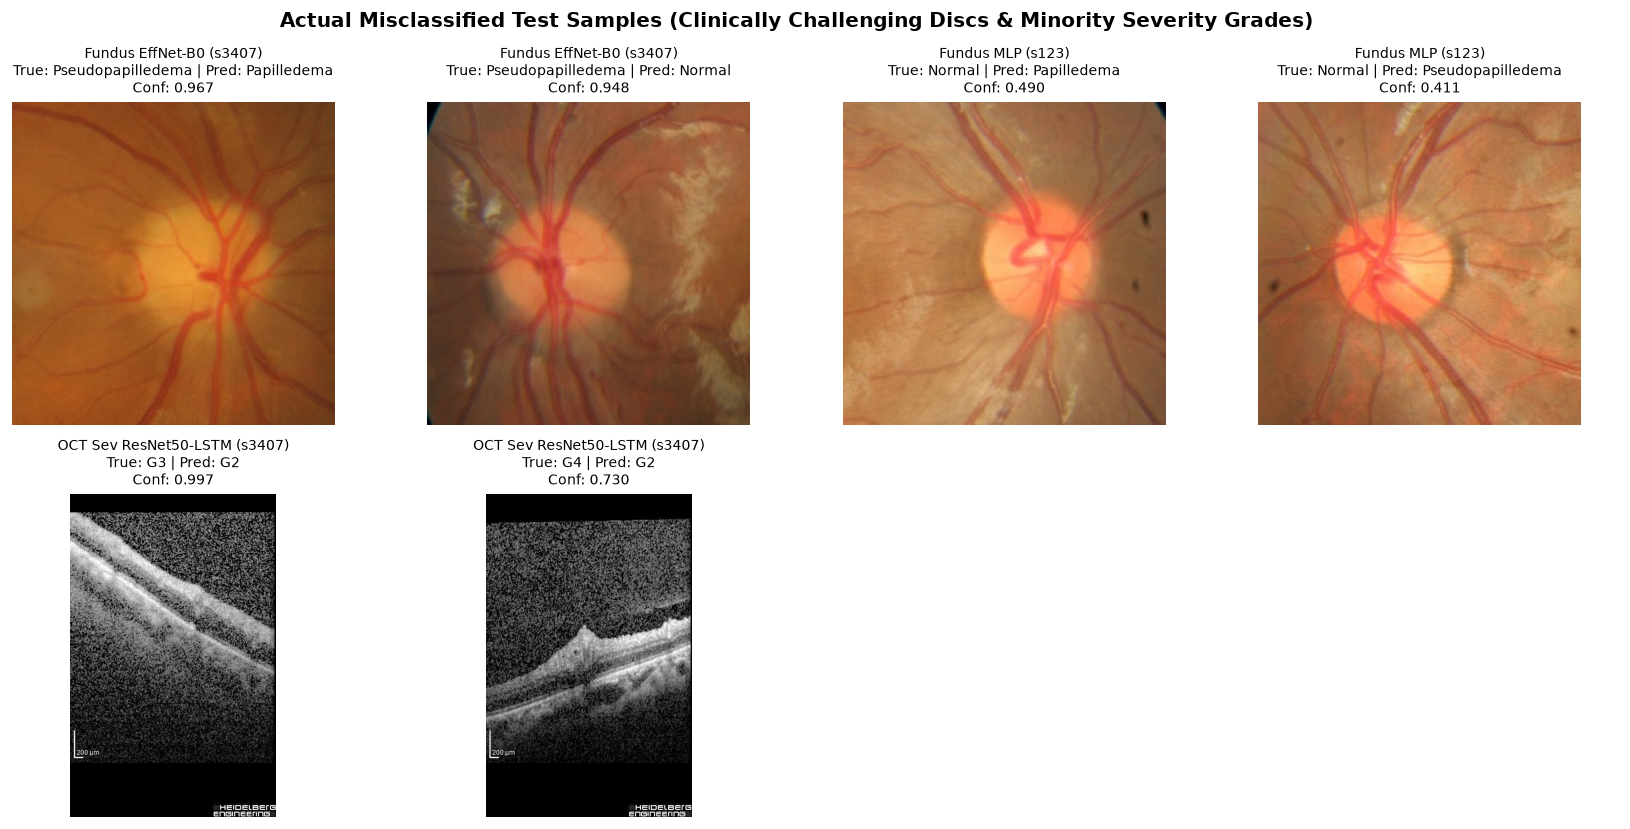

In [16]:
err_summary_rows = []
for track_name, models_check in [
    ("fundus_3class", ["efficientnet_b0", "efficientnet_b0_bilstm", "autoencoder_classifier", "mlp", "lstm"]),
    ("oct_individual", ["densenet121", "efficientnet_b0", "resnet50_bilstm", "lstm"]),
    ("oct_sequence", ["resnet50_bilstm", "efficientnet_b0_bilstm", "bilstm", "lstm"]),
    ("oct_severity", ["resnet50_lstm", "efficientnet_b0", "resnet50_bilstm", "bilstm"]),
]:
    for m in models_check:
        sub_runs = runs_df[(runs_df["track"] == track_name) & (runs_df["model"] == m)]
        pair_counts = {}
        total_err, high_conf_err = 0, 0
        for eid in sub_runs["exp_id"]:
            edf = pd.read_csv(f"results/predictions/{eid}_errors.csv")
            total_err += len(edf)
            if len(edf):
                high_conf_err += int(edf["high_confidence_error"].sum())
                for (tl, pl), cnt in edf.groupby(["true_label", "pred_label"]).size().items():
                    key = f"{tl}->{pl}"
                    pair_counts[key] = pair_counts.get(key, 0) + int(cnt)
        top_pairs = ", ".join(f"{k}:{v}" for k, v in sorted(pair_counts.items(), key=lambda x: -x[1])[:3])
        err_summary_rows.append({
            "track": track_name,
            "model": m,
            "sum_errors_5seeds": total_err,
            "high_conf_errors_5seeds": high_conf_err,
            "dominant_confusions": top_pairs or "None (0 errors)",
        })

print("=== 5-Seed Pooled Misclassification Summary ===")
print(pd.DataFrame(err_summary_rows).to_string(index=False))

best_f_run = runs_df[(runs_df["track"] == "fundus_3class") & (runs_df["model"] == "efficientnet_b0")].sort_values("macro_f1", ascending=False).iloc[0]
f_err_df = pd.read_csv(f"results/predictions/{best_f_run['exp_id']}_errors.csv")
f_mlp_run = runs_df[(runs_df["track"] == "fundus_3class") & (runs_df["model"] == "mlp")].sort_values("macro_f1", ascending=False).iloc[0]
f_mlp_err = pd.read_csv(f"results/predictions/{f_mlp_run['exp_id']}_errors.csv")
sev_run = runs_df[(runs_df["track"] == "oct_severity") & (runs_df["model"] == "resnet50_lstm")].sort_values("macro_f1", ascending=False).iloc[0]
sev_err_df = pd.read_csv(f"results/predictions/{sev_run['exp_id']}_errors.csv")

examples = []
for _, r in f_err_df.head(2).iterrows():
    examples.append((f"Fundus EffNet-B0 (s{best_f_run['seed']})", "RGB", r))
for _, r in f_mlp_err.head(2).iterrows():
    examples.append((f"Fundus MLP (s{f_mlp_run['seed']})", "RGB", r))
for _, r in sev_err_df.drop_duplicates(subset=["true_label", "pred_label"]).head(4).iterrows():
    examples.append((f"OCT Sev ResNet50-LSTM (s{sev_run['seed']})", "L", r))

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (tag, mode_vis, r) in zip(axes.flat, examples):
    im = Image.open(r["image_path"]).convert(mode_vis)
    ax.imshow(im, cmap="gray" if mode_vis == "L" else None)
    ax.set_title(f"{tag}\nTrue: {r['true_label']} | Pred: {r['pred_label']}\nConf: {r['confidence']:.3f}", fontsize=8.5)
    ax.axis("off")
for ax in axes.flat[len(examples):]:
    ax.axis("off")

plt.suptitle("Actual Misclassified Test Samples (Clinically Challenging Discs & Minority Severity Grades)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

## 17. Clinical Relevance, Threats to Validity & Limitations

1. **No Verified Patient Identifiers (`is_verified_patient = False`):**
   Both public repositories lack ground-truth patient IDs. Although pixel hashes and NCC clustered Fundus duplicates (`190` test groups / `205` images) and visual/filename continuity grouped OCT B-scan sequences, distinct sequences from the same patient could still appear across splits — especially where a subject prefix contains multiple sessions. Results must therefore **never** be described as patient-independent clinical validation.
2. **Severe Prefix Concentration in Original OCT:**
   `Normal` (`sabrenr`) and `Pseudopapilledema` (`heshama`) each originate from **1 inferred subject prefix** (`2` contiguous sequences each), and `G1` (`hagerh`) and `G4` (`mostafaa`) likewise originate from **1 prefix each**. Near-ceiling OCT classification metrics (`0.97–1.00`) reflect high separability among very few acquisition series (`4` test clusters) rather than broad population generalization.
3. **Exploratory Status of Severity Grading (`G1–G4`):**
   Folder-encoded Frisén grades have no accompanying clinical grading protocol or inter-rater adjudication, and `test` supports (`G1=6`, `G2=146`, `G3=13`, `G4=11`) produce high run-to-run variance and poor minority-class generalization (`Macro F1 ~0.40–0.53`).
4. **Fixed-Split Seed Tests vs. External Cohort Inference:**
   All Friedman and paired seed t-tests evaluate training optimization variance across `5` seeds on **one fixed partition** (`n=5`, where Wilcoxon cannot reach `< 0.05`), while OCT McNemar p-values over `183` slices / `23` windows share only `4` clusters (`5` in severity) and are anti-conservative.
5. **No Clinical Deployment Claims:**
   High classification accuracy on retrospective academic datasets does not establish diagnostic safety, device calibration stability, or clinical utility in neurology/ophthalmology triage without prospective multicenter patient-level evaluation.

## 18. Conclusions & Future Work

1. **Convolutional Spatial Hierarchy Dominates Both Modalities:** Pretrained 2D CNNs (`efficientnet_b0 = 0.9835` on Fundus; `densenet121 = 0.9928` on OCT individual B-scans) and CNN-backed Hybrids (`0.9779–0.9863`) consistently achieve top accuracy and calibration across all metrics while requiring only `2.5–3.9 ms/sample` on RTX 5050 GPU.
2. **Spatial Tokenization Without CNN Feature Extraction Underperforms:** Standalone RNNs (`lstm`, `bilstm`) operating directly on ordered spatial strips lag by `0.23–0.43` Macro F1 on 2D image tasks and fail (`0.28–0.34`) on small-sample ordered OCT sequences, whereas Hybrid CNN–RNNs recover ordered slice structure cleanly (`resnet50_bilstm = 0.9849` Macro F1, `1.0000` ROC/PR AUC on `oct_sequence`).
3. **Efficiency–Accuracy Sweet Spot:** `efficientnet_b0` (`4.01M` parameters, `2.54 ms` latency) provides top Fundus Macro F1 (`0.9835`) and second-best OCT B-scan Macro F1 (`0.9903`) with `~6x` fewer parameters than ResNet-50 variants (`23.5–24.4M`).
4. **Future Directions:**
   - Acquire multi-center datasets with **verified patient-level identifiers**, balanced Frisén severity representation, and external test cohorts.
   - Explore ordinal regression / focal / class-balanced losses with volumetric 3D/slice-attention encoders when multi-subject OCT cohorts become available.
   - Evaluate model calibration (ECE / Brier score) and clinician-in-the-loop saliency audit on borderline Papilledema vs. Pseudopapilledema discs.

## 19. Consolidated Research Artifact & Export Manifest

Programmatically inventories all generated result tables (`results/tables/`), statistical analyses (`results/statistical_analysis/`), markdown reports (`results/reports/`), and publication figures (`results/figures/`), saving a verified manifest JSON at `results/reports/notebook_export_manifest.json`.

In [17]:
manifest = {
    "notebook": "notebooks/Papilledema_Complete_Research_Analysis.ipynb",
    "completed_non_smoke_runs": int(len(runs_df)),
    "tracks": runs_df.groupby("track")["exp_id"].count().to_dict(),
    "tables": [{"file": p.name, "bytes": p.stat().st_size} for p in sorted(Path("results/tables").glob("*.csv"))],
    "statistical_files": [{"file": p.name, "bytes": p.stat().st_size} for p in sorted(Path("results/statistical_analysis").glob("*"))],
    "reports": [{"file": p.name, "bytes": p.stat().st_size} for p in sorted(Path("results/reports").glob("*.md"))],
    "figures_count": len(list(Path("results/figures").glob("*.png"))),
    "figures": [p.name for p in sorted(Path("results/figures").glob("*.png"))],
    "predictions_files_count": len(list(Path("results/predictions").glob("*.csv"))),
}
manifest_path = Path("results/reports/notebook_export_manifest.json")
manifest_path.write_text(json.dumps(manifest, indent=2), encoding="utf-8")

print("Saved export manifest :", manifest_path)
print("Tables CSV count      :", len(manifest["tables"]))
print("Statistical files     :", len(manifest["statistical_files"]))
print("Markdown reports      :", len(manifest["reports"]))
print("Publication PNGs      :", manifest["figures_count"])
print("Prediction/Error CSVs :", manifest["predictions_files_count"])

Saved export manifest : results\reports\notebook_export_manifest.json
Tables CSV count      : 10
Statistical files     : 6
Markdown reports      : 4
Publication PNGs      : 57
Prediction/Error CSVs : 366
